# Cryptocurrency Statistical Arbitrage Strategy

## 1. Research Objective

This notebook develops and evaluates a pairs-trading strategy on a universe of liquid
cryptocurrency instruments. The strategy targets temporary deviations from a long-run
linear relationship between two cointegrated assets: when the spread between a pair widens
beyond a calibrated threshold, the strategy takes a market-neutral position sized against
reversion to the historical relationship.

The analysis follows a three-sample protocol -- formation, validation, and out-of-sample --
so that pair selection, model choice, and parameter values are all fixed before the data on
which the strategy is ultimately judged is observed. Section 4 documents this split in
detail; it is the main safeguard against overfitting in the rest of the notebook.

A secondary objective is to test whether a dynamic hedge ratio (a rolling regression beta,
re-estimated as new data arrives) improves on a static hedge ratio fit once during formation.
This is set up as a controlled experiment in Section 9, isolating the hedge-ratio effect
from the effect of rolling Z-score normalization.

**Engine note.** Positions are tracked as fixed coin quantities set at trade entry and held
until exit, with cash P&L marked bar-by-bar -- the same convention a manual pairs-trade
implementation would use. Signals observed at a bar's close execute at the next bar's price,
and transaction costs are charged directly on the bar an order executes.

## 2. Strategy Configuration

All parameters are declared once, in a single configuration dictionary, and referenced by
name everywhere else in the notebook. The three sample boundaries are the most consequential
entries: every date-based slice used later is taken from this dictionary by name, rather
than inferred implicitly (e.g. "everything after 2022"), so a later edit cannot silently
change what counts as out-of-sample.

In [1]:
import pandas as pd
import numpy as np
import itertools as it
import pickle
import time
import os
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.stats.multitest import multipletests

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)
np.random.seed(0)


In [2]:
CONFIG = {
    # Sample boundaries (Section 4)
    'FORMATION_START': '2020-01-01',
    'FORMATION_END':   '2022-12-31',
    'VALIDATION_START': '2023-01-01',
    'VALIDATION_END':   '2023-12-31',
    'OOS_START': '2024-01-01',
    'OOS_END':   '2026-06-30',

    # Universe filtering
    'MANUAL_EXCLUDE': ['USDCUSDT', 'FDUSDUSDT', 'XMRUSDT'],  # stablecoins / not economically tradable pairs
    'MIN_HISTORY_CUTOFF': '2021-06-30',  # coins first observed after this date lack sufficient formation history

    # Bar frequency
    'BARS_PER_DAY': 6,         # 4h bars
    'BARS_PER_YEAR': 365 * 6,  # annualization factor

    # Cointegration screening
    'EG_ALPHA': 0.05,        # Engle-Granger significance level
    'FDR_METHOD': 'fdr_bh',  # Benjamini-Hochberg multiple-testing correction
    'MIN_OBS_FOR_TEST': 100, # minimum overlapping observations to run a cointegration test

    # Static control model (reproduces a previously reported ICP/FIL result; see Section 3)
    'STATIC_BASELINE_PAIR': ('FILUSDT', 'ICPUSDT'),  # (X, Y), Y = alpha + beta*X + eps
    'STATIC_ALPHA': 0.1236,
    'STATIC_BETA': 0.9335,
    'BASELINE_EXPECTED_TRADES': 5,
    'BASELINE_EXPECTED_DURATIONS': [21, 86, 91, 36, 2],
    'BASELINE_EXPECTED_AVG_NET_PNL': 0.1026,  # prior cash/quantity report, approximate
    'BASELINE_PNL_TOLERANCE': 0.01,           # absolute return tolerance for the regression check

    # Trading rules (shared across the static and dynamic models unless an experiment
    # explicitly overrides one in isolation -- see Section 9)
    'ENTRY_Z': 1.5,
    'EXIT_Z': 0.5,
    'HARD_STOP_Z': 4.0,
    'TIME_STOP_BARS': 156,
    'COST_PER_LEG_BPS': 20,  # applied per unit of turnover, per leg

    # Dynamic-model parameters
    'ROLLING_WINDOW_DAYS': 90,  # converted to bars via BARS_PER_DAY

    # Tradability handling
    'FFILL_LIMIT_BARS': 2,  # bridges gaps of at most 2 bars (~8h); no unbounded forward-fill
}

CONFIG['ROLLING_WINDOW_BARS'] = CONFIG['ROLLING_WINDOW_DAYS'] * CONFIG['BARS_PER_DAY']

for key, value in CONFIG.items():
    print(f'{key:24s} = {value}')


FORMATION_START          = 2020-01-01
FORMATION_END            = 2022-12-31
VALIDATION_START         = 2023-01-01
VALIDATION_END           = 2023-12-31
OOS_START                = 2024-01-01
OOS_END                  = 2026-06-30
MANUAL_EXCLUDE           = ['USDCUSDT', 'FDUSDUSDT', 'XMRUSDT']
MIN_HISTORY_CUTOFF       = 2021-06-30
BARS_PER_DAY             = 6
BARS_PER_YEAR            = 2190
EG_ALPHA                 = 0.05
FDR_METHOD               = fdr_bh
MIN_OBS_FOR_TEST         = 100
STATIC_BASELINE_PAIR     = ('FILUSDT', 'ICPUSDT')
STATIC_ALPHA             = 0.1236
STATIC_BETA              = 0.9335
BASELINE_EXPECTED_TRADES = 5
BASELINE_EXPECTED_DURATIONS = [21, 86, 91, 36, 2]
BASELINE_EXPECTED_AVG_NET_PNL = 0.1026
BASELINE_PNL_TOLERANCE   = 0.01
ENTRY_Z                  = 1.5
EXIT_Z                   = 0.5
HARD_STOP_Z              = 4.0
TIME_STOP_BARS           = 156
COST_PER_LEG_BPS         = 20
ROLLING_WINDOW_DAYS      = 90
FFILL_LIMIT_BARS         = 2
ROLLING_WINDOW_BARS      = 540


## 3. Data Collection and Universe Construction

Price and return series are loaded from a pre-built local cache (`px.pkl`, `ret.pkl`) at
4-hour bar frequency. The universe is filtered before any statistical work begins:
stablecoins and instruments with insufficient formation-period history are dropped, since
neither can support a meaningful cointegration test or a useful hedge pair.

In [3]:
with open("px.pkl", "rb") as f:
    px = pickle.load(f)
with open("ret.pkl", "rb") as f:
    ret = pickle.load(f)

print('Raw data:', px.shape, '|', px.index[0], 'to', px.index[-1])

Raw data: (14233, 47) | 2020-01-01 00:00:00 to 2026-06-30 00:00:00


Coins are excluded if they are economically unsuitable as a pairs-trading leg
(stablecoins, explicitly listed in `CONFIG['MANUAL_EXCLUDE']`) or if their first observation
falls after `MIN_HISTORY_CUTOFF` -- too little formation-period history to support a
reliable regression fit.

In [4]:
def _coverage(col):
    first = col.first_valid_index()
    last = col.last_valid_index()
    active = col.loc[first:last]
    td = len(active)
    valid = active.count()
    missing_pct = ((td - valid) / td) * 100 if td > 0 else np.nan
    return pd.Series({'First Date': first, 'Last Date': last,
                       'Observations': valid, 'Missing (%)': round(missing_pct, 2)})

overview = ret.apply(_coverage).T

cut = pd.to_datetime(CONFIG['MIN_HISTORY_CUTOFF'])
drop_late = overview[overview['First Date'] > cut].index.tolist()
drop = sorted(set(CONFIG['MANUAL_EXCLUDE'] + drop_late))

px = px.drop(columns=drop)
ret = ret.drop(columns=drop)

print(f'Excluded ({len(drop)}):', drop)
print(f'Remaining universe: {px.shape[1]} coins')

Excluded (19): ['APTUSDT', 'ARBUSDT', 'ENAUSDT', 'FDUSDUSDT', 'FLOKIUSDT', 'IMXUSDT', 'JUPUSDT', 'LDOUSDT', 'OPUSDT', 'PEPEUSDT', 'POLUSDT', 'RENDERUSDT', 'SEIUSDT', 'SUIUSDT', 'TAOUSDT', 'TIAUSDT', 'TONUSDT', 'USDCUSDT', 'XMRUSDT']
Remaining universe: 28 coins


### Tradability and delistings

A coin is tradable only between its first and last valid observation. Small gaps
(`<= FFILL_LIMIT_BARS` bars) are bridged with a forward-fill; beyond that, or once a coin's
final observation has passed (delisting, migration to a new ticker), its price stays `NaN`
rather than being held flat indefinitely. Treating a delisted coin's frozen last price as
tradable would generate fabricated zero-return bars for the remainder of the sample and
silently understate volatility and cost.

In [5]:
def get_tradable_price(px_series, ffill_limit=CONFIG['FFILL_LIMIT_BARS']):
    """Return a price series that is NaN outside the coin's active trading window,
    with only small gaps (<= ffill_limit bars) bridged. No unbounded forward-fill.

    Forward-fill is applied before reindexing onto the full sample index, strictly within
    [first_valid_index, last_valid_index]. Reindexing first and forward-filling afterward
    would let the fill bridge past last_valid_index into the newly introduced trailing
    NaNs -- i.e. treat a coin as tradable for a few bars after its last real print. Filling
    only within the slice ending at the coin's actual last observation avoids this.
    """
    s = px_series.replace(0, np.nan)
    first, last = s.first_valid_index(), s.last_valid_index()
    if first is None:
        return s
    s = s.loc[first:last].ffill(limit=ffill_limit)
    s = s.reindex(px_series.index)
    return s

def tradable_mask(px_series, ffill_limit=CONFIG['FFILL_LIMIT_BARS']):
    """True where the coin has a usable (real or small-gap-filled) price."""
    return get_tradable_price(px_series, ffill_limit).notna()

last_valid = px.apply(lambda c: c.replace(0, np.nan).last_valid_index())
delisted = last_valid[last_valid < px.index[-1]]
print('Coins with data ending before', px.index[-1].date(), ':')
print(delisted.to_string())


Coins with data ending before 2026-06-30 :
FTMUSDT   2025-01-13
OMUSDT    2026-03-02
MKRUSDT   2025-09-15


### Sample splits

In [6]:
formation_px = px.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']]
validation_px = px.loc[CONFIG['VALIDATION_START']:CONFIG['VALIDATION_END']]
oos_px = px.loc[CONFIG['OOS_START']:CONFIG['OOS_END']]

print('Formation  :', formation_px.index[0], '-', formation_px.index[-1], f'({len(formation_px)} bars)')
print('Validation :', validation_px.index[0], '-', validation_px.index[-1], f'({len(validation_px)} bars)')
print('Final OOS  :', oos_px.index[0], '-', oos_px.index[-1], f'({len(oos_px)} bars)')

# Sanity: splits must not overlap
assert formation_px.index.max() < validation_px.index.min(), 'Formation/Validation overlap!'
assert validation_px.index.max() < oos_px.index.min(), 'Validation/OOS overlap!'
print('\nSplit sanity check passed: no overlap between Formation / Validation / OOS.')

Formation  : 2020-01-01 00:00:00 - 2022-12-31 20:00:00 (6576 bars)
Validation : 2023-01-01 00:00:00 - 2023-12-31 20:00:00 (2190 bars)
Final OOS  : 2024-01-01 00:00:00 - 2026-06-30 00:00:00 (5467 bars)

Split sanity check passed: no overlap between Formation / Validation / OOS.


## 4. Sample Definition

| Period | Range | Role |
|---|---|---|
| Formation | 2020-01-01 -- 2022-12-31 | Pair selection, static hedge-ratio and calibration fit |
| Validation | 2023-01-01 -- 2023-12-31 | Model choice (static vs. rolling), window selection |
| Out-of-sample | 2024-01-01 -- 2026-06-30 | Final evaluation, run exactly once |

No date-based slice in this notebook is computed implicitly; every function that needs a
period takes it as an explicit `CONFIG` argument. Pair selection and model/parameter choices
use formation and validation data only. The out-of-sample period is not used for any
selection decision -- its only role is a final, single evaluation of the frozen strategy.

One caveat on the out-of-sample label: this date range was partially visible in earlier
iterations of this research process before the current engine was finalized. It is reported
here as *corrected historical* rather than a pristine holdout, and no parameter was adjusted
in response to it. Section 14 returns to this point.

## 5. Preliminary Pair Screening

### Spread Convention

Every pair in this notebook uses one regression and spread convention, applied identically
in the cointegration test, the static model, the rolling model, and the position logic:

$$Y_t = \alpha + \beta X_t + \epsilon_t \qquad \text{spread}_t = Y_t - \alpha - \beta X_t$$

With a positive $\beta$: $z_t > \text{entry}$ triggers short $Y$ / long $\beta \cdot X$, and
$z_t < -\text{entry}$ triggers long $Y$ / short $\beta \cdot X$. A regression fit with the
dependent and independent variables swapped produces a residual that is not stationary
unless $\beta \approx 1$ by coincidence, since $X$ itself is non-stationary. The helper
functions below enforce a single convention everywhere and include an explicit residual-mean
check as a guard against this class of sign error.

In [7]:
def fit_static_ols(y, x):
    """Fit Y = alpha + beta*X + eps via OLS. y is the dependent variable, x the independent."""
    d = pd.concat([x, y], axis=1).dropna()
    d.columns = ['x', 'y']
    design = sm.add_constant(d['x'].values)
    model = sm.OLS(d['y'].values, design).fit()
    alpha, beta = model.params[0], model.params[1]
    return alpha, beta, model


def compute_spread(y, x, alpha, beta):
    """spread = Y - alpha - beta*X. Single definition used throughout the notebook."""
    return y - alpha - beta * x


def sanity_check_residual_mean(y, x, alpha, beta, tol=None, label=''):
    """Assert the in-sample OLS residual has ~zero mean, catching a swapped-variable
    regression (dependent/independent reversed), which biases the spread mean away from
    zero without necessarily failing the cointegration test itself."""
    spread = compute_spread(y, x, alpha, beta)
    mean, std = spread.mean(), spread.std()
    if tol is None:
        tol = 0.1 * std  # mean should be small relative to the spread's own dispersion
    ok = abs(mean) < tol
    print(f'[{"OK" if ok else "FAILED"}] {label} residual mean={mean:.5f}  std={std:.5f}  (tol={tol:.5f})')
    assert ok, f'Residual mean sanity check failed for {label}: mean={mean:.5f}, std={std:.5f}'
    return ok


Unit test: fit a known, liquid pair and confirm the residual is centered near zero before any pair-selection or backtest code runs.

In [8]:
# Unit test: fit a known pair on formation log-prices and confirm the residual is
# centered near zero. This must pass before any pair-selection or backtest code runs.
_test_x_name, _test_y_name = 'BTCUSDT', 'ETHUSDT'  # any liquid pair works for this check
_log_formation = np.log(formation_px[[_test_x_name, _test_y_name]].dropna())
_a, _b, _m = fit_static_ols(_log_formation[_test_y_name], _log_formation[_test_x_name])
sanity_check_residual_mean(_log_formation[_test_y_name], _log_formation[_test_x_name],
                            _a, _b, label=f'{_test_y_name} on {_test_x_name} (formation)')
print(f'alpha={_a:.4f}, beta={_b:.4f}')

[OK] ETHUSDT on BTCUSDT (formation) residual mean=-0.00000  std=0.34752  (tol=0.03475)
alpha=-7.7997, beta=1.4709


Pairs are drawn from all $\binom{n}{2}$ unordered combinations of the filtered
universe. Each unordered pair is tested in both regression directions in Section 6, since
the assignment of $Y$ and $X$ matters for which residual is stationary, but the pair itself
is only counted once. This screening step reduces the number of cointegration tests to the
economically distinct candidates.

In [9]:
coins = formation_px.columns.tolist()
unique_pairs = list(it.combinations(coins, 2))  # unordered, unique economic pairs
print(f'{len(coins)} coins -> {len(unique_pairs)} unique unordered pairs')


28 coins -> 378 unique unordered pairs


## 6. Cointegration Analysis

Each candidate pair is tested for cointegration using the Engle-Granger procedure
(`statsmodels.tsa.stattools.coint`), which supplies critical values appropriate for a
cointegration test on regression residuals -> a plain ADF test with textbook critical values
is not valid here. Both regression directions are tested for every unordered pair, since
`coint()` regresses its first argument on its second and the assignment of dependent/
independent variable affects the result.

Engle-Granger results are cached to disk, keyed by a hash of the universe and formation
window, so a change to either automatically invalidates a stale cache rather than silently
reusing results computed on a different universe or date range.

In [10]:
import hashlib

log_formation_all = np.log(formation_px)

# Cache key includes the universe and formation window, so a change to either invalidates
# the cache automatically rather than silently reusing results computed on a different
# universe or date range.
_cache_fingerprint = hashlib.md5(
    (','.join(sorted(formation_px.columns)) + '|' + CONFIG['FORMATION_START'] + '|' + CONFIG['FORMATION_END']).encode()
).hexdigest()[:10]
EG_CACHE = f'eg_results_{_cache_fingerprint}.pkl'

if os.path.exists(EG_CACHE):
    eg_df = pd.read_pickle(EG_CACHE)
    print('Loaded Engle-Granger results from cache:', eg_df.shape, f'(fingerprint={_cache_fingerprint})')
else:
    rows = []
    t0 = time.time()
    for c1, c2 in unique_pairs:
        d = log_formation_all[[c1, c2]].dropna()
        if len(d) < CONFIG['MIN_OBS_FOR_TEST']:
            continue
        # coint() regresses its first argument on its second, so calling it both ways
        # checks both candidate (Y, X) assignments for this unordered pair.
        for y_name, x_name in [(c1, c2), (c2, c1)]:
            try:
                eg_stat, eg_pvalue, crit_values = coint(d[y_name].values, d[x_name].values)
            except Exception:
                continue
            rows.append({
                'pair': tuple(sorted([c1, c2])),
                'y': y_name, 'x': x_name,
                'eg_stat': eg_stat, 'eg_pvalue': eg_pvalue, 'n_obs': len(d),
            })
    eg_df = pd.DataFrame(rows)
    eg_df.to_pickle(EG_CACHE)
    print(f'Engle-Granger scan finished in {time.time()-t0:.1f}s, {len(eg_df)} directional tests')

eg_df.head()


Loaded Engle-Granger results from cache: (756, 6) (fingerprint=b62b6e0656)


,pair,y,x,eg_stat,eg_pvalue,n_obs
0,"(BTCUSDT, ETHUSDT)",BTCUSDT,ETHUSDT,-1.158743,0.868376,6575
1,"(BTCUSDT, ETHUSDT)",ETHUSDT,BTCUSDT,-1.322906,0.822717,6575
2,"(BTCUSDT, SOLUSDT)",BTCUSDT,SOLUSDT,-1.421012,0.790220,5237
3,"(BTCUSDT, SOLUSDT)",SOLUSDT,BTCUSDT,-0.951864,0.911603,5237
4,"(BNBUSDT, BTCUSDT)",BTCUSDT,BNBUSDT,-0.852791,0.927404,6575


### Multiple-Testing Correction

Benjamini-Hochberg FDR correction is applied once, across the full family of directional
tests run above -- not per-coin and not re-applied after any subsetting. With hundreds of
simultaneous tests at a raw 5% significance level, dozens of false positives are expected by
chance alone; the correction controls the expected proportion of false discoveries among the
pairs retained.

In [11]:
reject, pvals_adj, _, _ = multipletests(eg_df['eg_pvalue'].values, alpha=CONFIG['EG_ALPHA'],
                                          method=CONFIG['FDR_METHOD'])
eg_df['pvalue_adj'] = pvals_adj
eg_df['significant_fdr'] = reject

n_sig_raw = (eg_df['eg_pvalue'] < CONFIG['EG_ALPHA']).sum()
n_sig_fdr = eg_df['significant_fdr'].sum()
print(f'Directional tests: {len(eg_df)}')
print(f'Significant at raw p<{CONFIG["EG_ALPHA"]}: {n_sig_raw}')
print(f'Significant after Benjamini-Hochberg FDR correction: {n_sig_fdr}')

sig_df = eg_df[eg_df['significant_fdr']].sort_values('pvalue_adj').reset_index(drop=True)
sig_df

Directional tests: 756
Significant at raw p<0.05: 134
Significant after Benjamini-Hochberg FDR correction: 20


,pair,y,x,eg_stat,eg_pvalue,n_obs,pvalue_adj,significant_fdr
0,"(AAVEUSDT, ICPUSDT)",ICPUSDT,AAVEUSDT,-7.701084,1.685276e-10,3600,1.274069e-07,True
1,"(AAVEUSDT, ICPUSDT)",AAVEUSDT,ICPUSDT,-7.146148,3.835844e-09,3600,1.449949e-06,True
2,"(ADAUSDT, ICPUSDT)",ICPUSDT,ADAUSDT,-5.887418,2.828825e-06,3600,7.128640e-04,True
3,"(FILUSDT, ICPUSDT)",ICPUSDT,FILUSDT,-5.178179,7.641960e-05,3600,1.444330e-02,True
4,"(ICPUSDT, LINKUSDT)",ICPUSDT,LINKUSDT,-5.115419,1.004410e-04,3600,1.509586e-02,True
5,"(BTCUSDT, FILUSDT)",BTCUSDT,FILUSDT,-4.954216,1.996806e-04,4844,1.509586e-02,True
6,"(ICPUSDT, SOLUSDT)",ICPUSDT,SOLUSDT,-4.959644,1.951829e-04,3600,1.509586e-02,True
7,"(ADAUSDT, ICPUSDT)",ADAUSDT,ICPUSDT,-5.025265,1.479013e-04,3600,1.509586e-02,True
8,"(GRTUSDT, XLMUSDT)",XLMUSDT,GRTUSDT,-4.966106,1.899544e-04,4465,1.509586e-02,True
9,"(DOTUSDT, GRTUSDT)",GRTUSDT,DOTUSDT,-5.012977,1.558299e-04,4465,1.509586e-02,True


### Deduplication of Mirrored Directions

Because both regression directions were tested for every unordered pair, a pair can appear
twice in the FDR-significant set (e.g. both `ICP` on `FIL` and `FIL` on `ICP`). These are the
same economic relationship traded in two mirrored parameterizations; retaining both would
double-count the pair in later selection and portfolio construction. For each unordered pair,
only the direction with the lower adjusted p-value is kept.

In [12]:
n_before = len(sig_df)
sig_df_dedup = (
    sig_df
    .sort_values('pvalue_adj')
    .drop_duplicates(subset='pair', keep='first')
    .reset_index(drop=True)
)
n_after = len(sig_df_dedup)

n_both_directions_significant = n_before - n_after
print(f'FDR-significant directional tests: {n_before}')
print(f'Unique unordered pairs after keeping only the lowest-pvalue_adj direction: {n_after}')
print(f'Pairs where both directions were significant (reverse-pair duplicate removed): '
      f'{n_both_directions_significant}')

assert sig_df_dedup['pair'].is_unique, 'Deduplication failed: an unordered pair still appears twice.'

# From here on, sig_df is the deduplicated, one-direction-per-pair table.
# The original (both-direction) table is kept as sig_df_both_directions for reference/audit only.
sig_df_both_directions = sig_df
sig_df = sig_df_dedup
sig_df

FDR-significant directional tests: 20
Unique unordered pairs after keeping only the lowest-pvalue_adj direction: 12
Pairs where both directions were significant (reverse-pair duplicate removed): 8


,pair,y,x,eg_stat,eg_pvalue,n_obs,pvalue_adj,significant_fdr
0,"(AAVEUSDT, ICPUSDT)",ICPUSDT,AAVEUSDT,-7.701084,1.685276e-10,3600,1.274069e-07,True
1,"(ADAUSDT, ICPUSDT)",ICPUSDT,ADAUSDT,-5.887418,2.828825e-06,3600,7.128640e-04,True
2,"(FILUSDT, ICPUSDT)",ICPUSDT,FILUSDT,-5.178179,7.641960e-05,3600,1.444330e-02,True
3,"(ICPUSDT, LINKUSDT)",ICPUSDT,LINKUSDT,-5.115419,1.004410e-04,3600,1.509586e-02,True
4,"(BTCUSDT, FILUSDT)",BTCUSDT,FILUSDT,-4.954216,1.996806e-04,4844,1.509586e-02,True
5,"(ICPUSDT, SOLUSDT)",ICPUSDT,SOLUSDT,-4.959644,1.951829e-04,3600,1.509586e-02,True
6,"(GRTUSDT, XLMUSDT)",XLMUSDT,GRTUSDT,-4.966106,1.899544e-04,4465,1.509586e-02,True
7,"(DOTUSDT, GRTUSDT)",GRTUSDT,DOTUSDT,-5.012977,1.558299e-04,4465,1.509586e-02,True
8,"(INJUSDT, XLMUSDT)",XLMUSDT,INJUSDT,-4.839537,3.212057e-04,4811,2.023596e-02,True
9,"(AAVEUSDT, XLMUSDT)",AAVEUSDT,XLMUSDT,-4.625411,7.563010e-04,4848,3.811757e-02,True


### Mean-Reversion Characteristics

For each surviving direction, the Ornstein-Uhlenbeck half-life is estimated via an AR(1) fit
on the spread level:

$$\text{spread}_t - \text{spread}_{t-1} = k \cdot (\text{spread}_{t-1} - \mu) + \epsilon_t,
\qquad \text{half-life} = \frac{-\ln 2}{\ln(1+k)}$$

A finite, interpretable half-life additionally requires $0 < 1+k < 1$: $k \geq 0$ implies no
reversion, and $1+k \leq 0$ implies an oscillating or explosive AR(1) root, neither of which
corresponds to a decaying mean-reverting process. Pairs are also required to cross their
long-run mean a minimum number of times during formation, so the half-life estimate reflects
enough realized mean-reversion cycles to be trusted rather than a single slow drift.

In [13]:
def compute_half_life(spread):
    """OU half-life via AR(1): spread_t - spread_{t-1} = k*(spread_{t-1} - mean) + eps,
    half_life = -ln(2)/ln(1+k). A finite half-life additionally requires 0 < 1+k < 1: k >= 0
    implies no reversion, and 1+k <= 0 implies an oscillating or explosive AR(1) root, which
    is not interpretable as a decaying mean-reversion timescale."""
    s = spread.dropna()
    lagged = s.shift(1).dropna()
    delta = (s - s.shift(1)).dropna()
    lagged = lagged.loc[delta.index]
    design = np.column_stack([np.ones(len(lagged)), lagged.values])
    coef, *_ = np.linalg.lstsq(design, delta.values, rcond=None)
    k = coef[1]
    phi = 1 + k
    if k >= 0 or phi <= 0:
        return np.inf
    return -np.log(2) / np.log(phi)


def count_crossings(spread, level=0.0):
    """Number of times the spread crosses `level` (mean-reversion cycles)."""
    s = spread.dropna()
    sign = np.sign(s - level)
    return int((sign.diff().abs() == 2).sum())


assert len(sig_df) > 0, (
    'No pairs survived the Benjamini-Hochberg FDR correction. A negative/empty result is '
    'a legitimate outcome, but there is nothing to half-life-screen. Inspect eg_df / sig_df '
    'before proceeding -- do not loosen EG_ALPHA or the FDR method to force a non-empty list.'
)

screen_rows = []
for _, row in sig_df.iterrows():
    y_name, x_name = row['y'], row['x']
    log_y = log_formation_all[y_name]
    log_x = log_formation_all[x_name]
    a, b, _ = fit_static_ols(log_y, log_x)
    spread = compute_spread(log_y, log_x, a, b)
    hl = compute_half_life(spread)
    crossings = count_crossings(spread)
    years = (spread.dropna().index[-1] - spread.dropna().index[0]).days / 365.25
    screen_rows.append({
        'pair': row['pair'], 'y': y_name, 'x': x_name,
        'pvalue_adj': row['pvalue_adj'], 'alpha': a, 'beta': b,
        'half_life_bars': hl, 'crossings': crossings,
        'crossings_per_year': crossings / years if years > 0 else np.nan,
    })

screen_df = pd.DataFrame(screen_rows).sort_values('half_life_bars')
screen_df


,pair,y,x,pvalue_adj,alpha,beta,half_life_bars,crossings,crossings_per_year
0,"(AAVEUSDT, ICPUSDT)",ICPUSDT,AAVEUSDT,1.274069e-07,-5.025595,1.566173,39.210144,144,87.806344
2,"(FILUSDT, ICPUSDT)",ICPUSDT,FILUSDT,1.444330e-02,0.123612,0.933541,51.517509,154,93.904007
6,"(GRTUSDT, XLMUSDT)",XLMUSDT,GRTUSDT,1.509586e-02,-1.033310,0.518179,62.266024,187,91.803427
1,"(ADAUSDT, ICPUSDT)",ICPUSDT,ADAUSDT,7.128640e-04,3.046101,1.471822,63.130345,98,59.757095
3,"(ICPUSDT, LINKUSDT)",ICPUSDT,LINKUSDT,1.509586e-02,-1.542653,1.688469,75.589382,118,71.952421
8,"(INJUSDT, XLMUSDT)",XLMUSDT,INJUSDT,2.023596e-02,-2.501311,0.608599,78.383481,165,75.238764
9,"(AAVEUSDT, XLMUSDT)",AAVEUSDT,XLMUSDT,3.811757e-02,6.966440,1.197289,103.113260,172,77.847584
10,"(AVAXUSDT, FTMUSDT)",AVAXUSDT,FTMUSDT,4.219162e-02,3.906373,0.675655,177.358951,120,52.807229
7,"(DOTUSDT, GRTUSDT)",GRTUSDT,DOTUSDT,1.509586e-02,-4.830208,1.395470,216.239113,23,11.291331
4,"(BTCUSDT, FILUSDT)",BTCUSDT,FILUSDT,1.509586e-02,9.429036,0.305211,227.533213,108,48.881041


### Frozen Pair List

Statistical significance, half-life, and crossing-frequency filters are applied together,
and the resulting pair list is frozen. No pair is added or removed based on validation or
out-of-sample performance from this point forward.

In [14]:
MAX_HALF_LIFE_BARS = 300     # ~50 days on 4h bars -- generous upper bound, tune only via 2023 validation reasoning, not OOS
MIN_CROSSINGS = 15           # require enough mean-reversion cycles in-sample to trust the estimate

candidate_pairs = screen_df[
    (screen_df['half_life_bars'] < MAX_HALF_LIFE_BARS) &
    (screen_df['half_life_bars'] > 0) &
    (screen_df['crossings'] >= MIN_CROSSINGS)
].copy()

print(f'Pairs passing statistical + half-life + crossing screen: {len(candidate_pairs)}')
candidate_pairs[['pair','y','x','pvalue_adj','alpha','beta','half_life_bars','crossings']]

Pairs passing statistical + half-life + crossing screen: 12


,pair,y,x,pvalue_adj,alpha,beta,half_life_bars,crossings
0,"(AAVEUSDT, ICPUSDT)",ICPUSDT,AAVEUSDT,1.274069e-07,-5.025595,1.566173,39.210144,144
2,"(FILUSDT, ICPUSDT)",ICPUSDT,FILUSDT,1.444330e-02,0.123612,0.933541,51.517509,154
6,"(GRTUSDT, XLMUSDT)",XLMUSDT,GRTUSDT,1.509586e-02,-1.033310,0.518179,62.266024,187
1,"(ADAUSDT, ICPUSDT)",ICPUSDT,ADAUSDT,7.128640e-04,3.046101,1.471822,63.130345,98
3,"(ICPUSDT, LINKUSDT)",ICPUSDT,LINKUSDT,1.509586e-02,-1.542653,1.688469,75.589382,118
8,"(INJUSDT, XLMUSDT)",XLMUSDT,INJUSDT,2.023596e-02,-2.501311,0.608599,78.383481,165
9,"(AAVEUSDT, XLMUSDT)",AAVEUSDT,XLMUSDT,3.811757e-02,6.966440,1.197289,103.113260,172
10,"(AVAXUSDT, FTMUSDT)",AVAXUSDT,FTMUSDT,4.219162e-02,3.906373,0.675655,177.358951,120
7,"(DOTUSDT, GRTUSDT)",GRTUSDT,DOTUSDT,1.509586e-02,-4.830208,1.395470,216.239113,23
4,"(BTCUSDT, FILUSDT)",BTCUSDT,FILUSDT,1.509586e-02,9.429036,0.305211,227.533213,108


In [15]:
# FROZEN pair list -- do not modify after this cell without restarting the research
# process from Phase 5. Each entry is (X, Y) matching the Y = alpha + beta*X + eps convention.
FROZEN_PAIRS = [(row['x'], row['y']) for _, row in candidate_pairs.iterrows()]
print(f'Frozen pair list ({len(FROZEN_PAIRS)} pairs):')
for x, y in FROZEN_PAIRS:
    print(f'  X={x:12s} Y={y}')

Frozen pair list (12 pairs):
  X=AAVEUSDT     Y=ICPUSDT
  X=FILUSDT      Y=ICPUSDT
  X=GRTUSDT      Y=XLMUSDT
  X=ADAUSDT      Y=ICPUSDT
  X=LINKUSDT     Y=ICPUSDT
  X=INJUSDT      Y=XLMUSDT
  X=XLMUSDT      Y=AAVEUSDT
  X=FTMUSDT      Y=AVAXUSDT
  X=DOTUSDT      Y=GRTUSDT
  X=FILUSDT      Y=BTCUSDT
  X=SOLUSDT      Y=ICPUSDT
  X=GRTUSDT      Y=UNIUSDT


## 7. Spread Model and Calibration

Three signal-generation variants are compared later in Section 9, isolating exactly one
change at each step:

- **Model S (Static):** hedge ratio $(\alpha, \beta)$ fit once on formation data; Z-score
  calibrated from the formation-period spread mean and standard deviation.
- **Model RZ (Rolling Z):** the same static, formation-fit $(\alpha, \beta)$ as Model S, but
  the Z-score's mean and standard deviation are recomputed on a trailing rolling window
  instead of being frozen from formation.
- **Model RB (Rolling Beta):** both the hedge ratio and the Z-score normalization are
  recomputed on a trailing rolling window.

Comparing RB against RZ isolates the effect of a dynamic hedge ratio specifically, since both
models share the same rolling-normalization methodology; comparing RZ against S isolates the
effect of rolling normalization alone. All rolling statistics at bar $t$ use only data from
$[t - \text{window}, t]$.

In [16]:
def gen_rolling_signal(x_price, y_price, window_bars, rolling_beta=True,
                        frozen_alpha=None, frozen_beta=None):
    """Compute alpha/beta (static or rolling) and a rolling-normalized Z-score for one pair.

    rolling_beta=False: alpha/beta are held fixed at `frozen_alpha`/`frozen_beta` -- Model RZ
        must reuse the exact formation-period values from Model S so the comparison isolates
        only the rolling-normalization effect, with an identical hedge ratio at every bar.
    rolling_beta=True: alpha/beta are recomputed at every bar from the trailing window
        (Model RB).

    In both cases the Z-score's mean/std are recomputed on the trailing rolling window.

    min_periods=window_bars (a full window is required, not a partial one), so beta, alpha,
    and the spread mean/std are all computed consistently once warmed up, at the cost of more
    leading NaNs at the start of each rolling series.
    """
    log_x, log_y = np.log(x_price), np.log(y_price)

    if rolling_beta:
        roll_cov = log_x.rolling(window=window_bars, min_periods=window_bars).cov(log_y)
        roll_var = log_x.rolling(window=window_bars, min_periods=window_bars).var()
        beta_series = roll_cov / roll_var
        alpha_series = (log_y.rolling(window=window_bars, min_periods=window_bars).mean()
                         - beta_series * log_x.rolling(window=window_bars, min_periods=window_bars).mean())
    else:
        if frozen_alpha is None or frozen_beta is None:
            raise ValueError(
                'gen_rolling_signal(rolling_beta=False) requires frozen_alpha/frozen_beta: '
                'Model RZ must reuse the frozen formation-period alpha/beta, not re-fit its own.')
        alpha_series = pd.Series(frozen_alpha, index=log_x.index)
        beta_series = pd.Series(frozen_beta, index=log_x.index)

    spread = compute_spread(log_y, log_x, alpha_series, beta_series)
    spread_mean = spread.rolling(window=window_bars, min_periods=window_bars).mean()
    spread_std = spread.rolling(window=window_bars, min_periods=window_bars).std()
    z_score = (spread - spread_mean) / spread_std

    return alpha_series, beta_series, spread, z_score


Truncating the input series at bar $t$ and recomputing must not change the rolling
signal's value at $t$ -- i.e. the value at $t$ never depends on data observed after $t$.

In [17]:
_x_test = np.log(get_tradable_price(px['BTCUSDT'])).iloc[:1000].pipe(np.exp)
_y_test = np.log(get_tradable_price(px['ETHUSDT'])).iloc[:1000].pipe(np.exp)
_window = 100
_check_bar = 500

_, _, _, z_full = gen_rolling_signal(_x_test, _y_test, _window, rolling_beta=True)
_x_trunc = _x_test.iloc[:_check_bar + 1]
_y_trunc = _y_test.iloc[:_check_bar + 1]
_, _, _, z_trunc = gen_rolling_signal(_x_trunc, _y_trunc, _window, rolling_beta=True)

_val_full = z_full.iloc[_check_bar]
_val_trunc = z_trunc.iloc[_check_bar]
assert np.isclose(_val_full, _val_trunc, equal_nan=True), (
    f'Look-ahead detected: z_score at bar {_check_bar} differs when future data is present '
    f'({_val_full} vs {_val_trunc})')
print(f'Look-ahead sanity check PASSED: z_score[{_check_bar}] identical whether or not future',
      'bars are present in the input series.')

Look-ahead sanity check PASSED: z_score[500] identical whether or not future bars are present in the input series.


## 8. Mean-Reversion Characteristics

Half-life and crossing frequency were already computed during pair screening in Section 6,
since they are themselves part of the selection criteria. The frozen pairs range from a
half-life of roughly 39 bars (`AAVE/ICP`, about 6.5 days at 4h bars) to over 250 bars for the
slowest-reverting pair. `TIME_STOP_BARS = 156` (~26 days) is set once, globally, from the
control pair's own half-life (`FIL/ICP`, roughly 51 bars, so the time stop is about $3\times$
that pair's half-life) and applied identically to every pair. For pairs with a substantially
longer half-life than the control pair, the time stop can force an exit before the spread has
had a comparable number of half-lives to revert; this is a known limitation of using one
global time stop across pairs with heterogeneous mean-reversion speed, noted further in
Section 15.

## 9. Trading Rules

The Z-score is the spread standardized by its calibration mean and standard deviation:

$$z_t = \frac{\text{spread}_t - \mu_s}{\sigma_s}$$

**Entry.** A position opens only on a fresh threshold crossing -- $z_{t-1} \leq z_{entry} <
z_t \leq z_{hard\_stop}$ (or the mirrored condition for the short side) -- not merely because
$|z_t|$ currently exceeds the entry threshold. This prevents re-entering on every bar while
the spread remains extended, and specifically excludes crossings that jump straight past the
hard-stop level in a single bar, since a position immediately stopped out on the following
bar would not be a defensible entry. $z_t > z_{entry}$ opens a short-spread position (short
$Y$, long $\beta \cdot X$); $z_t < -z_{entry}$ opens a long-spread position.

**Exit conditions**, evaluated in this order once a position is open:
1. Missing data on either leg -- forced close.
2. $|z_t| > z_{hard\_stop}$ -- hard stop.
3. $|z_t| \leq z_{exit}$ -- ordinary mean-reversion exit.
4. Holding period $\geq$ `TIME_STOP_BARS` -- time stop.
5. Within the last two bars of the sample -- forced end-of-sample close, so every accepted
   trade has room to execute and, if necessary, liquidate inside the observed data.

**Cooldown.** After a hard stop, time stop, or missing-data exit, the pair enters a locked
state and cannot re-enter until the spread first re-arms at $|z_t| \leq z_{exit}$, followed
by a fresh threshold crossing. Without this cooldown, a spread parked beyond the hard stop
would otherwise re-enter and immediately stop out on every subsequent bar.

**No pyramiding.** Only one position per pair is open at a time; a sustained threshold
breach does not add to the position.

Threshold values: $z_{entry} = 1.5$, $z_{exit} = 0.5$, $z_{hard\_stop} = 4.0$,
`TIME_STOP_BARS = 156`.

In [18]:
from enum import Enum

class TradeState(Enum):
    FLAT = 0
    LONG_SPREAD = 1   # long Y, short beta*X
    SHORT_SPREAD = 2  # short Y, long beta*X
    LOCKED = 3        # flat cooldown after stop/missing-data exit


def run_trade_state_machine(z_score, entry_z, exit_z, hard_stop_z, time_stop_bars):
    """Generate signal states/trades using close-t information only.

    Trade bars returned here are SIGNAL bars. `backtest_single_pair()` converts them to
    execution bars by adding one. Entry requires a fresh threshold crossing that does not
    land beyond the hard stop. Hard/time/missing-data exits enter LOCKED until the spread
    re-arms at |z| <= exit_z. New entries are disabled during the last two signal bars so
    every accepted trade has time to execute and, if necessary, liquidate inside the sample.
    """
    idx = z_score.index
    state = TradeState.FLAT
    state_series = pd.Series(TradeState.FLAT, index=idx, dtype=object)
    trades = []
    entry_bar = entry_time = direction = None
    trade_id = 0
    z_prev = np.nan

    for i, ts in enumerate(idx):
        z = z_score.iloc[i]

        if state == TradeState.FLAT:
            can_complete_inside_sample = i < len(idx) - 2
            if can_complete_inside_sample and pd.notna(z) and pd.notna(z_prev):
                crossed_up = (z_prev <= entry_z) and (entry_z < z <= hard_stop_z)
                crossed_down = (z_prev >= -entry_z) and (-hard_stop_z <= z < -entry_z)
                if crossed_up:
                    state, direction = TradeState.SHORT_SPREAD, 'short_spread'
                    entry_bar, entry_time = i, ts
                    trade_id += 1
                elif crossed_down:
                    state, direction = TradeState.LONG_SPREAD, 'long_spread'
                    entry_bar, entry_time = i, ts
                    trade_id += 1

        elif state == TradeState.LOCKED:
            if pd.notna(z) and abs(z) <= exit_z:
                state = TradeState.FLAT

        else:
            duration = i - entry_bar
            exit_reason = None
            if pd.isna(z):
                exit_reason = 'force_close_missing_data'
            elif abs(z) > hard_stop_z:
                exit_reason = 'hard_stop'
            elif abs(z) <= exit_z:
                exit_reason = 'exit'
            elif duration >= time_stop_bars:
                exit_reason = 'time_stop'
            elif i >= len(idx) - 2:
                exit_reason = 'end_of_sample'

            if exit_reason is not None:
                trades.append({
                    'trade_id': trade_id,
                    'direction': direction,
                    'entry_bar': entry_bar, 'entry_time': entry_time,
                    'exit_bar': i, 'exit_time': ts,
                    'duration_bars': i - entry_bar,
                    'exit_reason': exit_reason,
                })
                state = (TradeState.LOCKED if exit_reason in
                         ('hard_stop', 'time_stop', 'force_close_missing_data')
                         else TradeState.FLAT)
                direction = None
                entry_bar = entry_time = None

        state_series.iloc[i] = state
        if pd.notna(z):
            z_prev = z

    assert state not in (TradeState.LONG_SPREAD, TradeState.SHORT_SPREAD), (
        'Open signal state survived the penultimate-bar liquidation guard.')
    return state_series, trades


def state_to_position(state_series, beta_series, x_name, y_name):
    """Diagnostic signal targets only; actual holdings use fixed quantities below."""
    w_x = pd.Series(0.0, index=state_series.index)
    w_y = pd.Series(0.0, index=state_series.index)
    is_short = state_series == TradeState.SHORT_SPREAD
    is_long = state_series == TradeState.LONG_SPREAD
    w_x[is_short], w_y[is_short] = beta_series[is_short], -1.0
    w_x[is_long], w_y[is_long] = -beta_series[is_long], 1.0
    return pd.DataFrame({x_name: w_x, y_name: w_y})


Synthetic paths exercise: a normal round trip, no pyramiding under a sustained
threshold breach, a hard stop, an exact time stop, entry rejection beyond the hard stop,
LOCKED re-arming, a missing-data forced close, a penultimate-bar end-of-sample signal, and
rejection of a signal too close to the sample end to execute and liquidate within the
observed data.

In [19]:
# Signal-state regression tests -------------------------------------------------------
_z1 = pd.Series([0.2, 1.8, 1.9, 1.6, 0.4, 0.1], index=pd.date_range('2022-01-01', periods=6, freq='4h'))
_states1, _trades1 = run_trade_state_machine(_z1, 1.5, 0.5, 4.0, 156)
assert len(_trades1) == 1 and _trades1[0]['direction'] == 'short_spread'
assert _trades1[0]['exit_reason'] == 'exit' and _trades1[0]['duration_bars'] == 3

_z2 = pd.Series([0.1, 1.6, 1.7, 1.8, 1.9, 0.3], index=pd.date_range('2022-01-01', periods=6, freq='4h'))
_, _trades2 = run_trade_state_machine(_z2, 1.5, 0.5, 4.0, 156)
assert len(_trades2) == 1, 'sustained threshold breach must not pyramid'

_z3 = pd.Series([0.1, 1.6, 4.5, 0.2], index=pd.date_range('2022-01-01', periods=4, freq='4h'))
_, _trades3 = run_trade_state_machine(_z3, 1.5, 0.5, 4.0, 156)
assert _trades3[0]['exit_reason'] == 'hard_stop'

_z4 = pd.Series([0.1] + [1.6] * 10, index=pd.date_range('2022-01-01', periods=11, freq='4h'))
_, _trades4 = run_trade_state_machine(_z4, 1.5, 0.5, 4.0, 5)
assert _trades4[0]['exit_reason'] == 'time_stop' and _trades4[0]['duration_bars'] == 5

_z5 = pd.Series([0.1] + [7.0] * 20, index=pd.date_range('2022-01-01', periods=21, freq='4h'))
_states5, _trades5 = run_trade_state_machine(_z5, 1.5, 0.5, 4.0, 156)
assert len(_trades5) == 0 and (_states5 == TradeState.FLAT).all()

_z5c = pd.Series([0.1, 2.0, 2.1, 0.3, 0.2], index=pd.date_range('2022-01-01', periods=5, freq='4h'))
_, _trades5c = run_trade_state_machine(_z5c, 1.5, 0.5, 4.0, 156)
assert len(_trades5c) == 1 and _trades5c[0]['exit_reason'] == 'exit'

_z5b = pd.Series([0.1, 2.0, 4.5, 0.2, 0.3, 1.8, 1.9, 0.2, 0.1, 0.1],
                 index=pd.date_range('2022-01-01', periods=10, freq='4h'))
_, _trades5b = run_trade_state_machine(_z5b, 1.5, 0.5, 4.0, 156)
assert len(_trades5b) == 2 and _trades5b[0]['exit_reason'] == 'hard_stop'

_z6 = pd.Series([0.1, 1.8, 1.9, 1.7], index=pd.date_range('2022-01-01', periods=4, freq='4h'))
_states6, _trades6 = run_trade_state_machine(_z6, 1.5, 0.5, 4.0, 156)
assert _trades6[-1]['exit_reason'] == 'end_of_sample'
assert _trades6[-1]['exit_bar'] == len(_z6) - 2
assert (_states6.iloc[-2:] == TradeState.FLAT).all()

_z7 = pd.Series([0.1, 1.8, 1.9, np.nan, np.nan, np.nan],
                index=pd.date_range('2022-01-01', periods=6, freq='4h'))
_states7, _trades7 = run_trade_state_machine(_z7, 1.5, 0.5, 4.0, 156)
assert len(_trades7) == 1 and _trades7[0]['exit_reason'] == 'force_close_missing_data'
assert _trades7[0]['exit_bar'] == 3 and (_states7.iloc[3:] == TradeState.LOCKED).all()

_z8 = pd.Series([0.1, 0.2, 1.8], index=pd.date_range('2022-01-01', periods=3, freq='4h'))
_, _trades8 = run_trade_state_machine(_z8, 1.5, 0.5, 4.0, 156)
assert len(_trades8) == 0, 'a signal without room for next-bar entry and liquidation is invalid'
print('All signal-state-machine checks PASSED.')


All signal-state-machine checks PASSED.


## 10. Position Sizing and Transaction Costs

At entry, the pair's current equity is allocated across both legs using the entry-bar hedge
ratio, gross-normalized so $|w_X| + |w_Y| = 1$:

$$w_X = \frac{\beta}{1+|\beta|}, \qquad w_Y = \frac{-1}{1+|\beta|} \quad \text{(short-spread entry)}$$

Coin quantities are then fixed at $q = w \cdot \text{capital} / \text{price}$ and held
constant until exit -- no continuous rebalancing to constant weights during the holding
period. Transaction costs are charged as `COST_PER_LEG_BPS` basis points on the notional
value of each executed order (entry and exit), applied directly on the bar the order
executes, including the final liquidation.

In [20]:
def _entry_weights(direction, beta):
    """Signed entry notionals under spread = Y - alpha - beta*X, gross normalized to one."""
    denom = 1.0 + abs(beta)
    if not np.isfinite(denom) or denom <= 0:
        raise ValueError(f'Invalid beta at entry: {beta}')
    if direction == 'short_spread':
        return beta / denom, -1.0 / denom
    if direction == 'long_spread':
        return -beta / denom, 1.0 / denom
    raise ValueError(f'Unknown direction: {direction}')


## 11. Backtest Implementation

### Execution Convention

A signal observed at the close of bar $t$ executes at the price of bar $t+1$: entry and exit
bars recorded by the state machine (Section 9) are signal bars, and the accounting layer
below maps each one to its execution bar by adding one. Both timestamps are preserved on
every trade record for auditability.

In [21]:
def _execution_trades(signal_trades, index):
    """Map signal bars to next-bar executions and preserve both timestamps."""
    executed = []
    for tr in signal_trades:
        entry_exec = tr['entry_bar'] + 1
        exit_exec = tr['exit_bar'] + 1
        if entry_exec >= len(index) or exit_exec >= len(index):
            raise AssertionError(f'Trade cannot execute inside sample: {tr}')
        ex = dict(tr)
        ex.update({
            'signal_entry_bar': tr['entry_bar'], 'signal_entry_time': tr['entry_time'],
            'signal_exit_bar': tr['exit_bar'], 'signal_exit_time': tr['exit_time'],
            'signal_duration_bars': tr['duration_bars'],
            'entry_bar': entry_exec, 'entry_time': index[entry_exec],
            'exit_bar': exit_exec, 'exit_time': index[exit_exec],
            'duration_bars': exit_exec - entry_exec,
        })
        executed.append(ex)
    return executed


### Cash Ledger

Each bar first marks any open position to market using the prior bar's quantities, then
executes any order (entry, exit, or both) scheduled for that bar. Every pair carries an
independent quantity stream for its two legs, so pairs sharing a coin never write into each
other's state -- aggregation across pairs happens only later, explicitly, in the portfolio
engine (Section 13), where opposite-signed exposures on a shared coin can be netted.

In [22]:
class PairPosition:
    """Minimal isolation container used by the regression test below."""
    def __init__(self, x_name, y_name, index):
        self.x_name, self.y_name, self.index = x_name, y_name, index
        self.q_x = pd.Series(np.nan, index=index, name=x_name)
        self.q_y = pd.Series(np.nan, index=index, name=y_name)

    def as_frame(self):
        return pd.DataFrame({self.x_name: self.q_x, self.y_name: self.q_y})


Two quantity containers share one coin but retain fully independent values.

In [23]:
_idx = pd.date_range('2021-01-01', periods=5, freq='4h')
_p1 = PairPosition('AAAUSDT', 'GRTUSDT', _idx)
_p2 = PairPosition('GRTUSDT', 'BBBUSDT', _idx)
_p1.q_y.iloc[2] = -3.0
_p2.q_x.iloc[2] = 2.0
assert _p1.q_y.iloc[2] == -3.0 and _p2.q_x.iloc[2] == 2.0
print('Pair quantity isolation sanity check PASSED.')


Pair quantity isolation sanity check PASSED.


In [24]:
def execute_fixed_quantity_pair(x_price, y_price, beta_series, signal_state, signal_trades,
                                cost_per_leg_bps, initial_equity=1.0):
    """Cash ledger with next-bar execution and fixed quantities between executions.

    At entry, the current pair equity is allocated across the two legs using the signal-bar
    beta. Coin quantities are then held unchanged. Each bar marks the existing quantities
    to market before any order at that bar is executed. Trading cost is charged immediately
    as `abs(delta_quantity) * execution_price * bps`, including the last-bar liquidation.
    """
    idx = x_price.index
    x_price = x_price.reindex(idx).astype(float)
    y_price = y_price.reindex(idx).astype(float)
    beta_series = beta_series.reindex(idx)
    signal_state = signal_state.reindex(idx)
    trades = _execution_trades(signal_trades, idx)
    entries = {tr['entry_bar']: tr for tr in trades}
    exits = {tr['exit_bar']: tr for tr in trades}
    rate = cost_per_leg_bps * 1e-4

    # Valuation fallback is used only for a forced missing-data liquidation. It is explicit
    # and flagged in the trade record; a normal entry always requires a current tradable price.
    x_mark = x_price.ffill()
    y_mark = y_price.ffill()

    numeric_columns = ['qty_x', 'qty_y', 'notional_x', 'notional_y', 'w_x', 'w_y',
                       'turnover_cash', 'turnover', 'cost_cash', 'costs',
                       'gross_pnl_cash', 'net_pnl_cash', 'gross_ret', 'net_ret',
                       'equity_before', 'equity', 'gross_equity', 'gross_exposure']
    # Populate NumPy arrays inside the loop, then construct one DataFrame -- repeated
    # DataFrame.loc writes make a full multi-pair Run All needlessly slow.
    values = {name: np.zeros(len(idx), dtype=float) for name in numeric_columns}
    state_values = np.empty(len(idx), dtype=object)

    q_x = q_y = 0.0
    direction = None
    equity = gross_equity = float(initial_equity)

    for i, ts in enumerate(idx):
        prev_equity = equity
        gross_pnl = 0.0
        if i > 0 and (q_x != 0.0 or q_y != 0.0):
            gross_pnl = (q_x * (x_mark.iloc[i] - x_mark.iloc[i-1]) +
                         q_y * (y_mark.iloc[i] - y_mark.iloc[i-1]))
            if not np.isfinite(gross_pnl):
                raise ValueError(f'Cannot mark open position at {ts}.')

        equity_before_trade = prev_equity + gross_pnl
        target_q_x, target_q_y = q_x, q_y
        next_direction = direction

        if i in exits:
            target_q_x = target_q_y = 0.0
            next_direction = None

        if i in entries:
            tr = entries[i]
            if pd.isna(x_price.iloc[i]) or pd.isna(y_price.iloc[i]):
                raise ValueError(f'Entry execution has no tradable price at {ts}: {tr}')
            beta_entry = float(beta_series.iloc[tr['signal_entry_bar']])
            target_w_x, target_w_y = _entry_weights(tr['direction'], beta_entry)
            capital = max(equity_before_trade, 0.0)
            target_q_x = target_w_x * capital / x_price.iloc[i]
            target_q_y = target_w_y * capital / y_price.iloc[i]
            next_direction = tr['direction']
            tr.update({'entry_beta': beta_entry, 'entry_equity_before': equity_before_trade,
                       'entry_price_x': x_price.iloc[i], 'entry_price_y': y_price.iloc[i],
                       'entry_qty_x': target_q_x, 'entry_qty_y': target_q_y})

        exec_px_x, exec_px_y = x_mark.iloc[i], y_mark.iloc[i]
        delta_q_x, delta_q_y = target_q_x - q_x, target_q_y - q_y
        # 0 * NaN is NaN in floating-point arithmetic. Before a coin's listing both the
        # order and position are zero, so the economically correct order notional is zero.
        turnover_x = 0.0 if delta_q_x == 0.0 else abs(delta_q_x) * exec_px_x
        turnover_y = 0.0 if delta_q_y == 0.0 else abs(delta_q_y) * exec_px_y
        turnover_cash = turnover_x + turnover_y
        cost_cash = turnover_cash * rate
        equity = equity_before_trade - cost_cash
        gross_equity += gross_pnl
        net_pnl = gross_pnl - cost_cash

        if i in entries:
            entries[i]['entry_cost_cash'] = cost_cash
        if i in exits:
            exits[i].update({'exit_equity_after': equity, 'exit_price_x': exec_px_x,
                             'exit_price_y': exec_px_y, 'exit_cost_cash': cost_cash,
                             'stale_exit_price': bool(pd.isna(x_price.iloc[i]) or pd.isna(y_price.iloc[i]))})

        q_x, q_y, direction = target_q_x, target_q_y, next_direction
        notional_x = 0.0 if q_x == 0.0 else q_x * x_mark.iloc[i]
        notional_y = 0.0 if q_y == 0.0 else q_y * y_mark.iloc[i]
        denom = equity if equity != 0 else np.nan
        gross_exposure = (abs(notional_x) + abs(notional_y)) / denom

        row = [q_x, q_y, notional_x, notional_y, notional_x / denom, notional_y / denom,
               turnover_cash, turnover_cash / prev_equity, cost_cash, cost_cash / prev_equity,
               gross_pnl, net_pnl, gross_pnl / prev_equity, net_pnl / prev_equity,
               prev_equity, equity, gross_equity, gross_exposure]
        for name, value in zip(numeric_columns, row):
            values[name][i] = value
        state_values[i] = (TradeState.SHORT_SPREAD if direction == 'short_spread'
                           else TradeState.LONG_SPREAD if direction == 'long_spread'
                           else TradeState.FLAT)

    assert abs(q_x) < 1e-14 and abs(q_y) < 1e-14, 'Pair is not flat after final execution.'
    out = pd.DataFrame(values, index=idx)
    out['state'] = pd.Series(state_values, index=idx, dtype=object)
    out['signal_state'] = signal_state
    return out, trades


def backtest_single_pair(x_price, y_price, alpha, beta, ret_x, ret_y,
                         entry_z, exit_z, hard_stop_z, time_stop_bars, cost_per_leg_bps,
                         z_score=None, alpha_series=None, beta_series=None,
                         state_start=None):
    """Single-pair path: signal generation -> next-bar execution -> fixed-quantity cash P&L.

    state_start, if given, restricts the trade state machine to bars at or after that date --
    the signal itself still uses full history for its rolling/formation statistics, but no
    position can be open before state_start and the state machine is seeded FLAT there. This
    is used for both Validation and Final OOS (Sections 12-14) so each evaluation begins with
    zero exposure while still allowing prior history to inform the signal.
    """
    log_x, log_y = np.log(x_price), np.log(y_price)
    if z_score is None:
        spread = compute_spread(log_y, log_x, alpha, beta)
        z_score = (spread - spread.mean()) / spread.std()
    else:
        spread = compute_spread(log_y, log_x, alpha, beta)

    beta_for_entry = (beta_series.reindex(z_score.index) if beta_series is not None
                      else pd.Series(beta, index=z_score.index))
    z_for_state = z_score
    if state_start is not None:
        z_for_state = z_score.where(z_score.index >= pd.Timestamp(state_start))

    signal_state, signal_trades = run_trade_state_machine(
        z_for_state, entry_z, exit_z, hard_stop_z, time_stop_bars)
    result, trades = execute_fixed_quantity_pair(
        x_price, y_price, beta_for_entry, signal_state, signal_trades,
        cost_per_leg_bps=cost_per_leg_bps, initial_equity=1.0)
    result['z_score'] = z_score
    result['spread'] = spread
    return result, trades


### Trade-Level P&L

Per-trade gross and net P&L are derived directly from the bar-level cash ledger, dividing by
the capital allocated to the pair immediately before entry execution.

In [25]:
def compute_trade_pnl(trade, result_df):
    """Cash P&L for one executed trade, including both execution-bar costs."""
    start, end = trade['entry_bar'], trade['exit_bar']
    capital = float(result_df['equity_before'].iloc[start])
    gross_pnl = result_df['gross_pnl_cash'].iloc[start:end+1].sum() / capital
    net_pnl = result_df['equity'].iloc[end] / capital - 1.0
    total_costs = result_df['cost_cash'].iloc[start:end+1].sum() / capital
    return gross_pnl, net_pnl, total_costs


### Execution and Accounting Checks

The synthetic checks below verify, independently of any real market data, that: a signal at
bar $t$ executes at $t+1$; quantities remain fixed through the holding period (no implicit
intra-trade rebalancing); bar-level cash P&L equals quantity times price change; entry and
exit costs are charged on their actual execution bars, including the exit bar; and trade-level
P&L reconciles exactly with the bar-level ledger.

In [26]:
_synth_idx = pd.date_range('2022-01-01', periods=8, freq='4h')
_synth_z = pd.Series([0.1, 1.8, 1.9, 1.8, 1.6, 0.3, 0.2, 0.1], index=_synth_idx)
_synth_x = pd.Series([100., 101., 102., 100., 103., 104., 105., 106.], index=_synth_idx)
_synth_y = pd.Series([50., 50., 49., 48., 49., 50., 51., 52.], index=_synth_idx)

_synth_result, _synth_trades = backtest_single_pair(
    _synth_x, _synth_y, alpha=0.0, beta=2.0,
    ret_x=_synth_x.pct_change(fill_method=None), ret_y=_synth_y.pct_change(fill_method=None),
    entry_z=1.5, exit_z=0.5, hard_stop_z=4.0, time_stop_bars=156,
    cost_per_leg_bps=CONFIG['COST_PER_LEG_BPS'], z_score=_synth_z,
    beta_series=pd.Series(2.0, index=_synth_idx))

assert len(_synth_trades) == 1
_synth_trade = _synth_trades[0]
assert _synth_trade['signal_entry_bar'] == 1 and _synth_trade['entry_bar'] == 2
assert _synth_trade['signal_exit_bar'] == 5 and _synth_trade['exit_bar'] == 6
print('Next-bar execution reconciliation PASSED:',
      _synth_trade['signal_entry_time'], '->', _synth_trade['entry_time'], '|',
      _synth_trade['signal_exit_time'], '->', _synth_trade['exit_time'])


Next-bar execution reconciliation PASSED: 2022-01-01 04:00:00 -> 2022-01-01 08:00:00 | 2022-01-01 20:00:00 -> 2022-01-02 00:00:00


In [27]:
_expected_qx = (2/3) / _synth_x.iloc[2]
_expected_qy = (-1/3) / _synth_y.iloc[2]
_expected_qty_x = pd.Series([0., 0., _expected_qx, _expected_qx, _expected_qx, _expected_qx, 0., 0.], index=_synth_idx)
_expected_qty_y = pd.Series([0., 0., _expected_qy, _expected_qy, _expected_qy, _expected_qy, 0., 0.], index=_synth_idx)
pd.testing.assert_series_equal(_synth_result['qty_x'], _expected_qty_x, check_names=False, atol=1e-12)
pd.testing.assert_series_equal(_synth_result['qty_y'], _expected_qty_y, check_names=False, atol=1e-12)
assert (_synth_result['turnover_cash'].iloc[3:6] == 0).all()
print('Fixed-quantity reconciliation PASSED: no implicit intra-trade rebalancing.')


Fixed-quantity reconciliation PASSED: no implicit intra-trade rebalancing.


In [28]:
_rate = CONFIG['COST_PER_LEG_BPS'] * 1e-4
_expected_gross_pnl = pd.Series(0.0, index=_synth_idx)
for _i in range(3, 7):
    _expected_gross_pnl.iloc[_i] = (
        _expected_qx * (_synth_x.iloc[_i] - _synth_x.iloc[_i-1]) +
        _expected_qy * (_synth_y.iloc[_i] - _synth_y.iloc[_i-1]))
_expected_cost_cash = pd.Series(0.0, index=_synth_idx)
_expected_cost_cash.iloc[2] = _rate * (abs(_expected_qx)*_synth_x.iloc[2] + abs(_expected_qy)*_synth_y.iloc[2])
_expected_cost_cash.iloc[6] = _rate * (abs(_expected_qx)*_synth_x.iloc[6] + abs(_expected_qy)*_synth_y.iloc[6])

_expected_equity = pd.Series(index=_synth_idx, dtype=float)
_eq = 1.0
for _i in range(len(_synth_idx)):
    _eq += _expected_gross_pnl.iloc[_i] - _expected_cost_cash.iloc[_i]
    _expected_equity.iloc[_i] = _eq

pd.testing.assert_series_equal(_synth_result['gross_pnl_cash'], _expected_gross_pnl, check_names=False, atol=1e-12)
pd.testing.assert_series_equal(_synth_result['cost_cash'], _expected_cost_cash, check_names=False, atol=1e-12)
pd.testing.assert_series_equal(_synth_result['equity'], _expected_equity, check_names=False, atol=1e-12)
assert _synth_result['cost_cash'].iloc[6] > 0 and _synth_result['qty_x'].iloc[6] == 0
print('Cash P&L and direct execution-bar cost reconciliation PASSED.')


Cash P&L and direct execution-bar cost reconciliation PASSED.


In [29]:
_g, _n, _c = compute_trade_pnl(_synth_trade, _synth_result)
_expected_g = _expected_gross_pnl.iloc[2:7].sum()
_expected_n = _expected_equity.iloc[6] - 1.0
_expected_c = _expected_cost_cash.iloc[2:7].sum()
assert abs(_g - _expected_g) < 1e-12
assert abs(_n - _expected_n) < 1e-12
assert abs(_c - _expected_c) < 1e-12
print(f'Trade-level reconciliation PASSED: gross={_g:.6f}, net={_n:.6f}, costs={_c:.6f}.')


Trade-level reconciliation PASSED: gross=0.006002, net=0.001936, costs=0.004066.


## 12. In-Sample Results: Static Control Model

Before any pair-selection or dynamic-model work, the static `FIL`/`ICP` control pair is
re-run on formation data only (2020-2022, starting FLAT) as a regression check against a
previously reported result for this exact pair and parameterization. This isolates the
engine itself: if the reproduction does not match, the fix belongs here, before dynamic-beta
work begins.

In [30]:
x_name, y_name = CONFIG['STATIC_BASELINE_PAIR']

# Fit alpha/beta on formation data only, and confirm it is close to the known frozen values.
log_form = np.log(formation_px[[x_name, y_name]].dropna())
fit_alpha, fit_beta, _ = fit_static_ols(log_form[y_name], log_form[x_name])
sanity_check_residual_mean(log_form[y_name], log_form[x_name], fit_alpha, fit_beta,
                            label=f'{y_name} on {x_name} (formation, static baseline)')
print(f'Freshly fit:  alpha={fit_alpha:.4f}  beta={fit_beta:.4f}')
print(f'Frozen prior: alpha={CONFIG["STATIC_ALPHA"]:.4f}  beta={CONFIG["STATIC_BETA"]:.4f}')

alpha_diff = abs(fit_alpha - CONFIG['STATIC_ALPHA'])
beta_diff = abs(fit_beta - CONFIG['STATIC_BETA'])
print(f'\nDifference: alpha_diff={alpha_diff:.4f}, beta_diff={beta_diff:.4f}')
if alpha_diff > 0.02 or beta_diff > 0.02:
    print('WARNING: freshly fit alpha/beta diverge materially from the frozen prior values.',
          'Investigate before proceeding (data alignment, date range, log-price convention).')
else:
    print('Freshly fit alpha/beta are close to the frozen prior values -- looks consistent.')

# Use the frozen prior values (not the freshly fit ones) for the actual backtest, since
# these are what the existing strategy is defined by.
BASELINE_ALPHA = CONFIG['STATIC_ALPHA']
BASELINE_BETA = CONFIG['STATIC_BETA']

[OK] ICPUSDT on FILUSDT (formation, static baseline) residual mean=0.00000  std=0.21739  (tol=0.02174)
Freshly fit:  alpha=0.1236  beta=0.9335
Frozen prior: alpha=0.1236  beta=0.9335

Difference: alpha_diff=0.0000, beta_diff=0.0000
Freshly fit alpha/beta are close to the frozen prior values -- looks consistent.


In [31]:
# Formation-only control run: frozen calibration, flat start, next-bar execution.
x_price_full = get_tradable_price(px[x_name]).loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']]
y_price_full = get_tradable_price(px[y_name]).loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']]
ret_x_full = x_price_full.pct_change(fill_method=None)  # retained for API compatibility
ret_y_full = y_price_full.pct_change(fill_method=None)

_log_x_form = np.log(x_price_full)
_log_y_form = np.log(y_price_full)
_spread_form = compute_spread(_log_y_form, _log_x_form, BASELINE_ALPHA, BASELINE_BETA)
_spread_mean_frozen = _spread_form.mean()
_spread_std_frozen = _spread_form.std()
_z_score_frozen_calibration = (_spread_form - _spread_mean_frozen) / _spread_std_frozen

baseline_result, baseline_trades = backtest_single_pair(
    x_price_full, y_price_full, BASELINE_ALPHA, BASELINE_BETA, ret_x_full, ret_y_full,
    entry_z=CONFIG['ENTRY_Z'], exit_z=CONFIG['EXIT_Z'], hard_stop_z=CONFIG['HARD_STOP_Z'],
    time_stop_bars=CONFIG['TIME_STOP_BARS'], cost_per_leg_bps=CONFIG['COST_PER_LEG_BPS'],
    z_score=_z_score_frozen_calibration, state_start=CONFIG['FORMATION_START'])

baseline_trades_df = pd.DataFrame(baseline_trades)
print(f'Control window: {CONFIG["FORMATION_START"]} to {CONFIG["FORMATION_END"]} (starts FLAT)')
print(f'Total executed trades: {len(baseline_trades_df)}')
print('Execution holding durations:', baseline_trades_df['duration_bars'].tolist())
print('Exit reasons:')
print(baseline_trades_df['exit_reason'].value_counts())
print(f'Cumulative net cash return: {baseline_result["equity"].iloc[-1]-1:.4f}')
baseline_trades_df.head(10)


Control window: 2020-01-01 to 2022-12-31 (starts FLAT)
Total executed trades: 5
Execution holding durations: [21, 86, 91, 36, 2]
Exit reasons:
exit_reason
exit    5
Name: count, dtype: int64
Cumulative net cash return: 0.6256


,trade_id,direction,entry_bar,entry_time,exit_bar,exit_time,duration_bars,exit_reason,signal_entry_bar,signal_entry_time,...,entry_price_x,entry_price_y,entry_qty_x,entry_qty_y,entry_cost_cash,exit_equity_after,exit_price_x,exit_price_y,exit_cost_cash,stale_exit_price
0,1,long_spread,3244,2021-06-24 16:00:00,3265,2021-06-28 04:00:00,21,exit,3243,2021-06-24 12:00:00,...,56.69,35.00,-0.008517,0.014777,0.002000,1.140627,56.73,44.83,0.002291,False
1,2,long_spread,3899,2021-10-11 20:00:00,3985,2021-10-26 04:00:00,86,exit,3898,2021-10-11 16:00:00,...,73.47,45.00,-0.007496,0.013110,0.002281,1.262241,64.30,49.38,0.002259,False
2,3,long_spread,4311,2021-12-19 12:00:00,4402,2022-01-03 16:00:00,91,exit,4310,2021-12-19 08:00:00,...,36.23,23.18,-0.016821,0.028163,0.002524,1.420591,34.74,28.10,0.002751,False
3,4,short_spread,4447,2022-01-11 04:00:00,4483,2022-01-17 04:00:00,36,exit,4446,2022-01-11 00:00:00,...,28.34,35.62,0.024201,-0.020627,0.002841,1.559013,29.54,30.05,0.002669,False
4,5,short_spread,5647,2022-07-30 04:00:00,5649,2022-07-30 12:00:00,2,exit,5646,2022-07-30 00:00:00,...,7.08,8.44,0.106313,-0.095535,0.003118,1.625571,7.73,8.40,0.003249,False


The regression check below requires an exact trade count and holding-duration match,
and an average net trade P&L within one percentage point of the previously reported cash/
quantity result -- a stronger criterion than timing alone, since it also validates the
position-sizing and cost logic, not just the signal.

In [32]:
pnl_rows = []
for tr in baseline_trades:
    g, n, c = compute_trade_pnl(tr, baseline_result)
    pnl_rows.append({**tr, 'gross_pnl': g, 'net_pnl': n, 'total_costs': c})
baseline_trades_pnl = pd.DataFrame(pnl_rows)

actual_durations = baseline_trades_pnl['duration_bars'].tolist()
avg_net_trade = baseline_trades_pnl['net_pnl'].mean()
assert len(baseline_trades_pnl) == CONFIG['BASELINE_EXPECTED_TRADES'], (
    f'Baseline trade count drifted: {len(baseline_trades_pnl)}')
assert actual_durations == CONFIG['BASELINE_EXPECTED_DURATIONS'], (
    f'Baseline durations drifted: {actual_durations}')
assert abs(avg_net_trade - CONFIG['BASELINE_EXPECTED_AVG_NET_PNL']) <= CONFIG['BASELINE_PNL_TOLERANCE'], (
    f'Baseline cash P&L did not reproduce prior report: avg={avg_net_trade:.4%}, '
    f'target={CONFIG["BASELINE_EXPECTED_AVG_NET_PNL"]:.4%}')

print(f'Win rate (net): {(baseline_trades_pnl["net_pnl"] > 0).mean()*100:.1f}%')
print(f'Average net P&L per trade: {avg_net_trade*100:.3f}% '
      f'(prior report ~{CONFIG["BASELINE_EXPECTED_AVG_NET_PNL"]*100:.2f}%)')
print(f'Total executed costs: {baseline_trades_pnl["total_costs"].sum()*100:.3f}%')
print('Baseline timing + cash/quantity P&L regression PASSED.')
baseline_trades_pnl[['trade_id','direction','signal_entry_time','entry_time','signal_exit_time',
                     'exit_time','duration_bars','exit_reason','gross_pnl','net_pnl']]


Win rate (net): 100.0%
Average net P&L per trade: 10.257% (prior report ~10.26%)
Total executed costs: 2.041%
Baseline timing + cash/quantity P&L regression PASSED.


,trade_id,direction,signal_entry_time,entry_time,signal_exit_time,exit_time,duration_bars,exit_reason,gross_pnl,net_pnl
0,1,long_spread,2021-06-24 12:00:00,2021-06-24 16:00:00,2021-06-28 00:00:00,2021-06-28 04:00:00,21,exit,0.144918,0.140627
1,2,long_spread,2021-10-11 16:00:00,2021-10-11 20:00:00,2021-10-26 00:00:00,2021-10-26 04:00:00,86,exit,0.110601,0.106620
2,3,long_spread,2021-12-19 08:00:00,2021-12-19 12:00:00,2022-01-03 12:00:00,2022-01-03 16:00:00,91,exit,0.129632,0.125452
3,4,short_spread,2022-01-11 00:00:00,2022-01-11 04:00:00,2022-01-17 00:00:00,2022-01-17 04:00:00,36,exit,0.101319,0.097440
4,5,short_spread,2022-07-30 00:00:00,2022-07-30 04:00:00,2022-07-30 08:00:00,2022-07-30 12:00:00,2,exit,0.046776,0.042693


### Model Orchestration

`run_model_on_pair()` ties signal generation (Section 7) to the execution engine
(Section 11) for a single pair under one of the three models. Two implementation details
matter for correctness:

- **Missing data.** `ret_x`/`ret_y` and the tradable price series share one basis
  (`get_tradable_price()`, Section 3), and the Z-score is explicitly set to `NaN` wherever
  either leg's tradable price is unavailable -- not only where a rolling window has not yet
  warmed up. This guarantees the state machine's missing-data exit path (Section 9) fires
  whenever a leg is genuinely untradable, rather than potentially acting on a stale,
  gap-filled value past the point a pair can actually be traded.
- **`pct_change(fill_method=None)`** is passed explicitly so a missing price always yields a
  missing return, independent of the pandas version's default fill behavior.

In [33]:
def run_model_on_pair(x_name, y_name, model, window_bars, entry_z, exit_z, hard_stop_z,
                       time_stop_bars, cost_per_leg_bps, price_data, ret_data,
                       state_start=None):
    """model in {'S', 'RZ', 'RB'}. state_start is forwarded to backtest_single_pair --
    see its docstring. Model S's alpha/beta are fit on formation data only, then applied
    unchanged to the full price series; Model RZ reuses this exact frozen (alpha, beta), so
    RZ vs. S isolates only the rolling-Z-normalization effect. Model RB estimates its own
    rolling beta.
    """
    x_price = get_tradable_price(price_data[x_name])
    y_price = get_tradable_price(price_data[y_name])
    ret_x = x_price.pct_change(fill_method=None)
    ret_y = y_price.pct_change(fill_method=None)

    # Formation-only fit, shared by Model S and Model RZ.
    log_x_form = np.log(x_price.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']])
    log_y_form = np.log(y_price.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']])
    fit_data_form = pd.concat([log_x_form, log_y_form], axis=1).dropna()
    fit_data_form.columns = ['x', 'y']
    a0, b0, _ = fit_static_ols(fit_data_form['y'], fit_data_form['x'])

    log_x, log_y = np.log(x_price), np.log(y_price)

    if model == 'S':
        spread = compute_spread(log_y, log_x, a0, b0)
        spread_mean = spread.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']].mean()
        spread_std = spread.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']].std()
        z_score = (spread - spread_mean) / spread_std
        beta_series = pd.Series(b0, index=x_price.index)
        alpha_used, beta_used = a0, b0
    elif model == 'RZ':
        alpha_series, beta_series, spread, z_score = gen_rolling_signal(
            x_price, y_price, window_bars, rolling_beta=False,
            frozen_alpha=a0, frozen_beta=b0)
        alpha_used, beta_used = a0, b0
    elif model == 'RB':
        alpha_series, beta_series, spread, z_score = gen_rolling_signal(
            x_price, y_price, window_bars, rolling_beta=True)
        alpha_used, beta_used = 0.0, 1.0  # unused: backtest_single_pair only needs alpha/beta
                                            # scalars for a diagnostic reference spread when
                                            # z_score/beta_series are supplied directly
    else:
        raise ValueError(f'Unknown model: {model}')

    # Force-close if either leg's tradable price is unavailable (see markdown above).
    untradable = x_price.isna() | y_price.isna()
    z_score = z_score.where(~untradable, np.nan)

    result, trades = backtest_single_pair(
        x_price, y_price, alpha_used, beta_used,
        ret_x, ret_y, entry_z=entry_z, exit_z=exit_z, hard_stop_z=hard_stop_z,
        time_stop_bars=time_stop_bars, cost_per_leg_bps=cost_per_leg_bps,
        z_score=z_score, beta_series=beta_series, state_start=state_start)

    return result, trades


## 13. Validation Results

Only 2023 data may inform model and parameter decisions from this point forward. Models S,
RZ, and RB are run on every frozen pair, with the trade state machine starting FLAT on
`VALIDATION_START` -- formation history remains available to the signal (rolling windows,
frozen alpha/beta), but no position carried from formation can bias the validation-period
evaluation.

In [34]:
# Pre-freeze comparison: formation data may calibrate signals, but the 2023 evaluation
# state starts FLAT and no 2024+ data is available to this cell.
px_pre_freeze = px.loc[:CONFIG['VALIDATION_END']]
ret_pre_freeze = ret.loc[:CONFIG['VALIDATION_END']]
MODEL_RESULTS, MODEL_TRADES = {}, {}

for x_name, y_name in FROZEN_PAIRS:
    for model in ['S', 'RZ', 'RB']:
        key = (x_name, y_name, model)
        result, trades = run_model_on_pair(
            x_name, y_name, model, window_bars=CONFIG['ROLLING_WINDOW_BARS'],
            entry_z=CONFIG['ENTRY_Z'], exit_z=CONFIG['EXIT_Z'],
            hard_stop_z=CONFIG['HARD_STOP_Z'], time_stop_bars=CONFIG['TIME_STOP_BARS'],
            cost_per_leg_bps=CONFIG['COST_PER_LEG_BPS'],
            price_data=px_pre_freeze, ret_data=ret_pre_freeze,
            state_start=CONFIG['VALIDATION_START'])
        MODEL_RESULTS[key], MODEL_TRADES[key] = result, trades
        val = result.loc[CONFIG['VALIDATION_START']:CONFIG['VALIDATION_END']]
        assert val['qty_x'].iloc[0] == 0 and val['qty_y'].iloc[0] == 0
        print(f'{x_name}/{y_name} [{model}]: {len(trades)} validation trades, '
              f'net cash return = {val["equity"].iloc[-1]-1:.4f}')


AAVEUSDT/ICPUSDT [S]: 2 validation trades, net cash return = 0.1270


AAVEUSDT/ICPUSDT [RZ]: 9 validation trades, net cash return = 0.1136


AAVEUSDT/ICPUSDT [RB]: 13 validation trades, net cash return = -0.1268


FILUSDT/ICPUSDT [S]: 1 validation trades, net cash return = -0.2162


FILUSDT/ICPUSDT [RZ]: 9 validation trades, net cash return = -0.0143


...

SOLUSDT/ICPUSDT [RZ]: 7 validation trades, net cash return = -0.0783


SOLUSDT/ICPUSDT [RB]: 9 validation trades, net cash return = -0.2494


GRTUSDT/UNIUSDT [S]: 0 validation trades, net cash return = 0.0000


GRTUSDT/UNIUSDT [RZ]: 12 validation trades, net cash return = -0.0501


GRTUSDT/UNIUSDT [RB]: 14 validation trades, net cash return = -0.1271


### Per-Pair Comparison

Sharpe ratios per pair give a first, purely diagnostic view of RZ vs. S and RB vs. RZ. This
distribution is not itself the selection criterion -- portfolio-level results below are.

In [35]:
def summarize_model_performance(result, ann_factor):
    r = result['net_ret'].dropna()
    if len(r) == 0 or r.std() == 0:
        return {'sharpe': np.nan, 'ann_return': np.nan, 'ann_vol': np.nan, 'n_bars': len(r)}
    sharpe = (r.mean() * ann_factor) / (r.std() * np.sqrt(ann_factor))
    return {
        'sharpe': sharpe,
        'ann_return': r.mean() * ann_factor,
        'ann_vol': r.std() * np.sqrt(ann_factor),
        'n_bars': len(r),
    }

comparison_rows = []
for x_name, y_name in FROZEN_PAIRS:
    for model in ['S', 'RZ', 'RB']:
        result = MODEL_RESULTS[(x_name, y_name, model)]
        val_slice = result.loc[CONFIG['VALIDATION_START']:CONFIG['VALIDATION_END']]
        stats = summarize_model_performance(val_slice, CONFIG['BARS_PER_YEAR'])
        comparison_rows.append({'pair': f'{x_name}/{y_name}', 'model': model, **stats})

comparison_df = pd.DataFrame(comparison_rows)
pivot = comparison_df.pivot(index='pair', columns='model', values='sharpe')
pivot['RB_minus_RZ'] = pivot['RB'] - pivot['RZ']
pivot['RZ_minus_S'] = pivot['RZ'] - pivot['S']
pivot.round(3)

model,RB,RZ,S,RB_minus_RZ,RZ_minus_S
pair,,,,,
AAVEUSDT/ICPUSDT,-0.484,0.528,1.124,-1.012,-0.596
ADAUSDT/ICPUSDT,-0.333,0.377,2.117,-0.709,-1.741
DOTUSDT/GRTUSDT,-2.020,-0.997,0.130,-1.023,-1.127
FILUSDT/BTCUSDT,-0.900,-2.633,0.454,1.733,-3.087
FILUSDT/ICPUSDT,-0.156,0.009,-0.808,-0.166,0.818
FTMUSDT/AVAXUSDT,-0.124,1.447,0.035,-1.570,1.411
GRTUSDT/UNIUSDT,-0.209,-0.034,NaN,-0.175,NaN
GRTUSDT/XLMUSDT,-0.151,-2.701,0.098,2.550,-2.799
INJUSDT/XLMUSDT,-0.393,-1.273,-0.957,0.880,-0.316


In [36]:
def drawdown(returns):
    """Cumulative drawdown series from a bar-level net return series. Defined here
    (moved up from Phase 10) so it's available to the 2023 portfolio-level model
    comparison below, not just the Final OOS drawdown plots later."""
    cumulative = (1 + returns.fillna(0)).cumprod()
    running_max = cumulative.cummax()
    return (cumulative - running_max) / running_max


### Portfolio-Level Comparison

Averaging independent per-pair Sharpe ratios is not the same as the Sharpe ratio of an
actual combined portfolio: it ignores that pairs sharing a coin can partially offset each
other's exposure, and it gives no direct measure of combined turnover, cost, or drawdown.
The portfolio engine below aggregates fixed coin quantities from equal-initial-capital pair
sleeves, nets shared-coin orders before computing turnover and cost, and produces one cash
ledger for the combined book. The same function is reused for window selection and for the
out-of-sample evaluation, so model choice, window choice, and the final evaluation are all
measured on a consistent basis.

In [37]:
def build_coin_netted_portfolio(pair_results, pairs, price_data, cost_per_leg_bps,
                                start, end, initial_equity=1.0):
    """Aggregate equal-initial-capital pair sleeves into coin quantities and a cash ledger."""
    pairs = list(pairs)
    n_pairs = len(pairs)
    if n_pairs == 0:
        raise ValueError('Cannot build a portfolio without pairs.')
    idx = pair_results[pairs[0]].loc[start:end].index
    sleeve_weight = 1.0 / n_pairs

    coin_qty = {}
    pair_level_turnover_notional = pd.Series(0.0, index=idx)
    for x_name, y_name in pairs:
        r = pair_results[(x_name, y_name)].reindex(idx)
        coin_qty.setdefault(x_name, pd.Series(0.0, index=idx))
        coin_qty.setdefault(y_name, pd.Series(0.0, index=idx))
        coin_qty[x_name] = coin_qty[x_name].add(r['qty_x'].fillna(0.0) * sleeve_weight)
        coin_qty[y_name] = coin_qty[y_name].add(r['qty_y'].fillna(0.0) * sleeve_weight)
        pair_level_turnover_notional = pair_level_turnover_notional.add(
            r['turnover_cash'].fillna(0.0) * sleeve_weight)
    coin_qty_df = pd.DataFrame(coin_qty, index=idx)

    coin_prices = pd.DataFrame({
        coin: get_tradable_price(price_data[coin]).reindex(idx) for coin in coin_qty_df.columns
    }, index=idx)
    coin_marks = coin_prices.ffill()
    qty_prev = coin_qty_df.shift().fillna(0.0)
    gross_pnl_cash = (qty_prev * coin_marks.diff()).sum(axis=1).fillna(0.0)
    order_qty = (coin_qty_df - qty_prev).fillna(0.0)
    turnover_notional = (order_qty.abs() * coin_marks).sum(axis=1).fillna(0.0)
    cost_cash = turnover_notional * cost_per_leg_bps * 1e-4

    equity_before = pd.Series(index=idx, dtype=float)
    equity = pd.Series(index=idx, dtype=float)
    gross_equity = pd.Series(index=idx, dtype=float)
    net_ret = pd.Series(index=idx, dtype=float)
    gross_ret = pd.Series(index=idx, dtype=float)
    current_equity = current_gross_equity = float(initial_equity)
    for i, ts in enumerate(idx):
        equity_before.iloc[i] = current_equity
        gross_ret.iloc[i] = gross_pnl_cash.iloc[i] / current_equity
        net_pnl = gross_pnl_cash.iloc[i] - cost_cash.iloc[i]
        net_ret.iloc[i] = net_pnl / current_equity
        current_equity += net_pnl
        current_gross_equity += gross_pnl_cash.iloc[i]
        equity.iloc[i] = current_equity
        gross_equity.iloc[i] = current_gross_equity

    coin_notional = coin_qty_df * coin_marks
    coin_weights = coin_notional.div(equity.replace(0, np.nan), axis=0)
    gross_notional = coin_notional.abs().sum(axis=1)
    gross_exposure = gross_notional / equity.replace(0, np.nan)
    coin_concentration = coin_notional.abs().max(axis=1).div(gross_notional.replace(0, np.nan))

    frame = pd.DataFrame({
        'gross_pnl_cash': gross_pnl_cash,
        'cost_cash': cost_cash,
        'net_pnl_cash': gross_pnl_cash - cost_cash,
        'gross_ret': gross_ret,
        'net_ret': net_ret,
        'equity_before': equity_before,
        'equity': equity,
        'gross_equity': gross_equity,
        'turnover_notional': turnover_notional,
        'turnover': turnover_notional / equity_before,
        'costs': cost_cash / equity_before,
        'gross_exposure': gross_exposure.fillna(0.0),
        'coin_concentration': coin_concentration,
        'pair_level_turnover_notional': pair_level_turnover_notional,
    }, index=idx)

    assert coin_qty_df.iloc[-1].abs().max() < 1e-12, (
        'Portfolio is not flat after final next-bar liquidation.')
    return {'frame': frame, 'coin_qty': coin_qty_df, 'coin_notional': coin_notional,
            'coin_weights': coin_weights, 'order_qty': order_qty,
            'coin_prices': coin_prices, 'coin_marks': coin_marks}


def evaluate_coin_netted_portfolio(pair_results, pairs, price_data, cost_per_leg_bps,
                                   start, end):
    portfolio = build_coin_netted_portfolio(
        pair_results, pairs, price_data, cost_per_leg_bps, start, end)
    f = portfolio['frame']
    net_stats = summarize_model_performance(pd.DataFrame({'net_ret': f['net_ret']}), CONFIG['BARS_PER_YEAR'])
    gross_stats = summarize_model_performance(pd.DataFrame({'net_ret': f['gross_ret']}), CONFIG['BARS_PER_YEAR'])
    dd = drawdown(f['net_ret'])
    active_conc = f.loc[f['gross_exposure'] > 0, 'coin_concentration']
    pair_turnover = f['pair_level_turnover_notional'].sum()
    net_turnover = f['turnover_notional'].sum()
    metrics = {
        'sharpe': net_stats['sharpe'], 'gross_sharpe': gross_stats['sharpe'],
        'ann_return': net_stats['ann_return'], 'gross_ann_return': gross_stats['ann_return'],
        'ann_vol': net_stats['ann_vol'],
        'cum_return': f['equity'].iloc[-1] - 1.0,
        'gross_cum_return': f['gross_equity'].iloc[-1] - 1.0,
        'max_dd': dd.min(), 'total_turnover': f['turnover'].sum(),
        'total_costs': f['cost_cash'].sum(),
        'pair_level_turnover_notional': pair_turnover,
        'netted_turnover_notional': net_turnover,
        'netting_savings_turnover': pair_turnover - net_turnover,
        'avg_gross_exposure': f['gross_exposure'].mean(),
        'max_gross_exposure': f['gross_exposure'].max(),
        'avg_coin_concentration': active_conc.mean() if len(active_conc) else np.nan,
        'max_coin_concentration': active_conc.max() if len(active_conc) else np.nan,
        'max_single_coin_weight': portfolio['coin_weights'].abs().max(axis=1).max(),
    }
    portfolio['drawdown'] = dd
    portfolio['metrics'] = metrics
    return portfolio, metrics


VALIDATION_PORTFOLIOS = {}

def build_validation_portfolio(model, pairs=FROZEN_PAIRS):
    pair_results = {(x, y): MODEL_RESULTS[(x, y, model)] for x, y in pairs}
    portfolio, metrics = evaluate_coin_netted_portfolio(
        pair_results, pairs, px_pre_freeze, CONFIG['COST_PER_LEG_BPS'],
        CONFIG['VALIDATION_START'], CONFIG['VALIDATION_END'])
    VALIDATION_PORTFOLIOS[model] = portfolio
    return {'model': model, **metrics}


portfolio_2023_rows = [build_validation_portfolio(m) for m in ['S', 'RZ', 'RB']]
portfolio_2023_df = pd.DataFrame(portfolio_2023_rows).set_index('model')
print('2023 validation: FLAT start, fixed quantities, coin-level netted execution:')
portfolio_2023_df.round(4)


2023 validation: FLAT start, fixed quantities, coin-level netted execution:


,sharpe,gross_sharpe,ann_return,gross_ann_return,ann_vol,cum_return,gross_cum_return,max_dd,total_turnover,total_costs,pair_level_turnover_notional,netted_turnover_notional,netting_savings_turnover,avg_gross_exposure,max_gross_exposure,avg_coin_concentration,max_coin_concentration,max_single_coin_weight
model,,,,,,,,,,,,,,,,,,
S,0.0431,0.1629,0.0021,0.0078,0.0480,0.0009,0.0066,-0.0685,2.8777,0.0056,2.8232,2.8232,0.0000,0.0837,0.3945,0.4738,0.7731,0.1171
RZ,-0.8906,-0.4525,-0.0761,-0.0386,0.0854,-0.0766,-0.0402,-0.1118,18.7115,0.0364,18.3652,18.1903,0.1749,0.2782,0.8537,0.3241,0.6727,0.2310
RB,-1.6885,-1.2424,-0.1832,-0.1346,0.1085,-0.1723,-0.1268,-0.1812,24.2837,0.0455,23.2240,22.7510,0.4730,0.3216,0.8103,0.3592,0.8896,0.3317


### Model Selection

Selection uses the 2023 coin-netted portfolio Sharpe, not an average of per-pair Sharpes.
The candidate models form a complexity hierarchy (S $\subset$ RZ $\subset$ RB), and each more
complex candidate is evaluated independently against every simpler model it would replace:

- RB is selected if its portfolio Sharpe is positive **and** it exceeds both S and RZ by more
  than `SELECTION_GO_MARGIN`.
- Otherwise RZ is selected if its portfolio Sharpe is positive **and** it exceeds S by more
  than the margin.
- Otherwise S, the simplest model, is kept.

This still defaults to the simplest model -- nothing is promoted without clearing a margin --
but does not require RZ to succeed on its own before RB can be considered; a dynamic hedge
ratio that only helps once combined with rolling normalization should still be selectable. A
selected model with non-positive validation Sharpe stops the notebook rather than proceeding
to a Final OOS run: a non-positive validation result is a legitimate scientific outcome, not
a reason to force a downstream evaluation.

In [38]:
SELECTION_GO_MARGIN = 0.10  # a candidate must beat every simpler model it replaces by more than this

print('2023 validation, actual equal-weight PORTFOLIO Sharpe by model:')
print(portfolio_2023_df['sharpe'].round(4))

s_sharpe = portfolio_2023_df.loc['S', 'sharpe'] if 'S' in portfolio_2023_df.index else np.nan
rz_sharpe = portfolio_2023_df.loc['RZ', 'sharpe'] if 'RZ' in portfolio_2023_df.index else np.nan
rb_sharpe = portfolio_2023_df.loc['RB', 'sharpe'] if 'RB' in portfolio_2023_df.index else np.nan

rb_beats_both = (pd.notna(rb_sharpe) and rb_sharpe > 0
                 and pd.notna(s_sharpe) and (rb_sharpe - s_sharpe) > SELECTION_GO_MARGIN
                 and pd.notna(rz_sharpe) and (rb_sharpe - rz_sharpe) > SELECTION_GO_MARGIN)
rz_beats_s = (pd.notna(rz_sharpe) and rz_sharpe > 0
              and pd.notna(s_sharpe) and (rz_sharpe - s_sharpe) > SELECTION_GO_MARGIN)

if rb_beats_both:
    SELECTED_MODEL = 'RB'
    decision_reason = (f'RB ({rb_sharpe:.3f}) beats both S ({s_sharpe:.3f}) and RZ ({rz_sharpe:.3f}) '
                        f'by more than {SELECTION_GO_MARGIN} -- select RB.')
elif rz_beats_s:
    SELECTED_MODEL = 'RZ'
    decision_reason = (f'RB does not beat both S and RZ by the margin (RB={rb_sharpe:.3f}). '
                        f'RZ ({rz_sharpe:.3f}) beats S ({s_sharpe:.3f}) by more than '
                        f'{SELECTION_GO_MARGIN} -- select RZ.')
else:
    SELECTED_MODEL = 'S'
    decision_reason = (f'Neither RB (={rb_sharpe:.3f}) beats both S and RZ, nor does RZ '
                        f'(={rz_sharpe:.3f}) beat S (={s_sharpe:.3f}), by more than '
                        f'{SELECTION_GO_MARGIN} -- staying at S, the simplest model.')

print(f'\nDecision path: {decision_reason}')
print(f'SELECTED_MODEL = {SELECTED_MODEL!r}')

final_sharpe = portfolio_2023_df.loc[SELECTED_MODEL, 'sharpe']
if pd.isna(final_sharpe) or final_sharpe <= 0:
    print(f'\nWARNING: SELECTED_MODEL={SELECTED_MODEL!r} has a non-positive 2023 portfolio '
          f'Sharpe ({final_sharpe:.3f}). This is a valid negative result -- the dynamic-hedge-'
          f'ratio hypothesis and the static baseline do not show a validated portfolio-level '
          f'edge on this pair set. Do not freeze a model to force a Final OOS run.')
assert not (pd.isna(final_sharpe) or final_sharpe <= 0), (
    f'SELECTED_MODEL={SELECTED_MODEL!r} portfolio Sharpe is not positive ({final_sharpe:.3f}) -- '
    f'refusing to freeze and run Final OOS on a model with no validated 2023 portfolio edge.')


2023 validation, actual equal-weight PORTFOLIO Sharpe by model:
model
S     0.0431
RZ   -0.8906
RB   -1.6885
Name: sharpe, dtype: float64

Decision path: Neither RB (=-1.688) beats both S and RZ, nor does RZ (=-0.891) beat S (=0.043), by more than 0.1 -- staying at S, the simplest model.
SELECTED_MODEL = 'S'


### Rolling-Window Selection

If a rolling model (RZ or RB) were selected, its window length would still need to be
chosen; this step is skipped entirely for Model S, which has no rolling window. The
candidate grid (90/180/365 days) is evaluated the same way as model selection: on coin-
netted 2023 portfolio Sharpe, not the mean of per-pair Sharpes, using the same underlying
portfolio engine for consistency across every selection step in this section.

In [39]:
# Window search remains a validation-only experiment. It uses the same FLAT-start and
# coin-netted quantity engine as model selection and OOS.
WINDOW_CANDIDATES_DAYS = [90, 180, 365]

if SELECTED_MODEL == 'S':
    print("SELECTED_MODEL == 'S': static baseline has no rolling window to tune -- skipping window sweep.")
    validation_df = pd.DataFrame(columns=['window_days', 'pair', 'sharpe', 'ann_return', 'ann_vol',
                                           'n_trades', 'win_rate', 'avg_trade_net_pnl',
                                           'total_costs', 'avg_gross_exposure'])
    window_portfolio_df = pd.DataFrame(columns=['sharpe', 'ann_return', 'ann_vol', 'cum_return',
                                                 'max_dd', 'total_turnover', 'total_costs'])
    WINDOW_PORTFOLIOS = {}
else:
    validation_rows, window_results, WINDOW_PORTFOLIOS = [], {}, {}
    for window_days in WINDOW_CANDIDATES_DAYS:
        window_bars = window_days * CONFIG['BARS_PER_DAY']
        for x_name, y_name in FROZEN_PAIRS:
            result, trades = run_model_on_pair(
                x_name, y_name, SELECTED_MODEL, window_bars=window_bars,
                entry_z=CONFIG['ENTRY_Z'], exit_z=CONFIG['EXIT_Z'],
                hard_stop_z=CONFIG['HARD_STOP_Z'], time_stop_bars=CONFIG['TIME_STOP_BARS'],
                cost_per_leg_bps=CONFIG['COST_PER_LEG_BPS'],
                price_data=px_pre_freeze, ret_data=ret_pre_freeze,
                state_start=CONFIG['VALIDATION_START'])
            window_results[(window_days, x_name, y_name)] = result
            val_slice = result.loc[CONFIG['VALIDATION_START']:CONFIG['VALIDATION_END']]
            val_trades = [t for t in trades if pd.Timestamp(CONFIG['VALIDATION_START']) <= t['entry_time'] <= pd.Timestamp(CONFIG['VALIDATION_END'])]
            n_trades = len(val_trades)
            trade_net = [compute_trade_pnl(t, result)[1] for t in val_trades]
            stats = summarize_model_performance(val_slice, CONFIG['BARS_PER_YEAR'])
            validation_rows.append({
                'window_days': window_days, 'pair': f'{x_name}/{y_name}',
                'sharpe': stats['sharpe'], 'ann_return': stats['ann_return'], 'ann_vol': stats['ann_vol'],
                'n_trades': n_trades, 'win_rate': (np.array(trade_net) > 0).mean() if n_trades else np.nan,
                'avg_trade_net_pnl': np.mean(trade_net) if n_trades else np.nan,
                'total_costs': val_slice['cost_cash'].sum(),
                'avg_gross_exposure': val_slice['gross_exposure'].mean(),
            })
    validation_df = pd.DataFrame(validation_rows)

    window_rows = []
    for window_days in WINDOW_CANDIDATES_DAYS:
        pair_results = {(x, y): window_results[(window_days, x, y)] for x, y in FROZEN_PAIRS}
        portfolio, metrics = evaluate_coin_netted_portfolio(
            pair_results, FROZEN_PAIRS, px_pre_freeze, CONFIG['COST_PER_LEG_BPS'],
            CONFIG['VALIDATION_START'], CONFIG['VALIDATION_END'])
        WINDOW_PORTFOLIOS[window_days] = portfolio
        window_rows.append({'window_days': window_days, **metrics})
    window_portfolio_df = pd.DataFrame(window_rows).set_index('window_days')
    print('2023 coin-netted fixed-quantity portfolio metrics per candidate window:')
    print(window_portfolio_df.round(4))

validation_df.round(4)


SELECTED_MODEL == 'S': static baseline has no rolling window to tune -- skipping window sweep.


,window_days,pair,sharpe,ann_return,ann_vol,n_trades,win_rate,avg_trade_net_pnl,total_costs,avg_gross_exposure


Per-pair dispersion by window is diagnostic only; the selection criterion is the portfolio-level table above.

In [40]:
# Pair-level dispersion is diagnostic only. Window selection uses window_portfolio_df,
# produced by the common coin-netted fixed-quantity portfolio engine.
window_summary = validation_df.groupby('window_days').agg(
    mean_sharpe=('sharpe', 'mean'), median_sharpe=('sharpe', 'median'),
    min_sharpe=('sharpe', 'min'), max_sharpe=('sharpe', 'max'),
    mean_ann_return=('ann_return', 'mean'), mean_n_trades=('n_trades', 'mean'),
    mean_win_rate=('win_rate', 'mean'), mean_costs=('total_costs', 'mean'),
).round(4)
window_summary


,mean_sharpe,median_sharpe,min_sharpe,max_sharpe,mean_ann_return,mean_n_trades,mean_win_rate,mean_costs
window_days,,,,,,,,


A plateau check guards against selecting an isolated Sharpe spike next to
substantially worse neighboring windows in the tested grid -- a common overfitting
signature when a parameter grid is swept and the best single value is taken at face
value.

In [41]:
if SELECTED_MODEL == 'S':
    best_window = None
    print("SELECTED_MODEL == 'S': no rolling window to select -- skipping plateau check.")
else:
    sharpe_by_window = window_portfolio_df['sharpe']
    print('2023 portfolio Sharpe by rolling window:')
    print(sharpe_by_window)

    best_window = sharpe_by_window.idxmax()
    print(f'\nNominal best by Sharpe: {best_window} days')

    sorted_windows = sorted(WINDOW_CANDIDATES_DAYS)
    best_idx = sorted_windows.index(best_window)
    neighbors = [sorted_windows[i] for i in [best_idx-1, best_idx+1] if 0 <= i < len(sorted_windows)]
    neighbor_sharpes = sharpe_by_window.loc[neighbors] if neighbors else pd.Series(dtype=float)

    print(f'Neighboring windows: {neighbors}, Sharpe: {neighbor_sharpes.to_dict()}')
    if len(neighbor_sharpes) > 0:
        drop = sharpe_by_window.loc[best_window] - neighbor_sharpes.max()
        print(f'Gap to best neighbor: {drop:.3f}')
        if (neighbor_sharpes < 0).any() and sharpe_by_window.loc[best_window] > 0:
            print('WARNING: best window is an isolated positive spike next to a negative neighbor.',
                  'Treat as an overfitting red flag -- prefer a more conservative choice from the plateau.')
        else:
            print('No isolated-spike red flag: neighboring windows behave consistently.')


SELECTED_MODEL == 'S': no rolling window to select -- skipping plateau check.


### Model Freeze

No cell below this point may change `ROLLING_WINDOW_BARS`, `FROZEN_PAIRS`, or any entry/
exit/stop parameter based on anything computed from `OOS_START` onward.

In [42]:
FROZEN_MODEL = {
    'pairs': FROZEN_PAIRS,
    'model': SELECTED_MODEL,
    'rolling_window_days': int(best_window) if best_window is not None else None,
    'rolling_window_bars': int(best_window) * CONFIG['BARS_PER_DAY'] if best_window is not None else None,
    'entry_z': CONFIG['ENTRY_Z'],
    'exit_z': CONFIG['EXIT_Z'],
    'hard_stop_z': CONFIG['HARD_STOP_Z'],
    'time_stop_bars': CONFIG['TIME_STOP_BARS'],
    'cost_per_leg_bps': CONFIG['COST_PER_LEG_BPS'],
}
print('FROZEN MODEL (do not modify after this point):')
for k, v in FROZEN_MODEL.items():
    print(f'  {k}: {v}')


FROZEN MODEL (do not modify after this point):
  pairs: [('AAVEUSDT', 'ICPUSDT'), ('FILUSDT', 'ICPUSDT'), ('GRTUSDT', 'XLMUSDT'), ('ADAUSDT', 'ICPUSDT'), ('LINKUSDT', 'ICPUSDT'), ('INJUSDT', 'XLMUSDT'), ('XLMUSDT', 'AAVEUSDT'), ('FTMUSDT', 'AVAXUSDT'), ('DOTUSDT', 'GRTUSDT'), ('FILUSDT', 'BTCUSDT'), ('SOLUSDT', 'ICPUSDT'), ('GRTUSDT', 'UNIUSDT')]
  model: S
  rolling_window_days: None
  rolling_window_bars: None
  entry_z: 1.5
  exit_z: 0.5
  hard_stop_z: 4.0
  time_stop_bars: 156
  cost_per_leg_bps: 20


## 14. Out-of-Sample Evaluation

This is the final, single evaluation of the frozen strategy on data no selection decision
in this notebook has used. Prices are cut at `OOS_END` so any position still open near the
sample boundary signals an end-of-sample exit on the penultimate bar and executes
liquidation on the last bar, consistent with the entry/exit conventions in Section 9.

One caveat, noted already in Section 4: this date range was partially visible in earlier
iterations of this research process before the current engine was finalized, and is reported
as *corrected historical* rather than a pristine holdout. No parameter was adjusted based on
it -- the frozen configuration from Section 13 is applied unchanged -- but a fully untouched
evaluation would require new data collected after this notebook, e.g. via paper trading or
a walk-forward design.

In [43]:
# Final corrected/pseudo-OOS run. Prices are explicitly cut at OOS_END so any open trade
# signals an end-of-sample exit on the penultimate bar and executes liquidation on the last.
px_oos_engine = px.loc[:CONFIG['OOS_END']]
ret_oos_engine = ret.loc[:CONFIG['OOS_END']]
oos_rows, oos_results, oos_trades = [], {}, {}

for x_name, y_name in FROZEN_MODEL['pairs']:
    result, trades = run_model_on_pair(
        x_name, y_name, FROZEN_MODEL['model'],
        window_bars=FROZEN_MODEL['rolling_window_bars'],
        entry_z=FROZEN_MODEL['entry_z'], exit_z=FROZEN_MODEL['exit_z'],
        hard_stop_z=FROZEN_MODEL['hard_stop_z'], time_stop_bars=FROZEN_MODEL['time_stop_bars'],
        cost_per_leg_bps=FROZEN_MODEL['cost_per_leg_bps'],
        price_data=px_oos_engine, ret_data=ret_oos_engine,
        state_start=CONFIG['OOS_START'])
    oos_slice = result.loc[CONFIG['OOS_START']:CONFIG['OOS_END']]
    oos_results[(x_name, y_name)] = oos_slice
    oos_trade_list = [t for t in trades if pd.Timestamp(CONFIG['OOS_START']) <= t['entry_time'] <= pd.Timestamp(CONFIG['OOS_END'])]
    oos_trades[(x_name, y_name)] = oos_trade_list

    assert oos_slice[['qty_x','qty_y']].iloc[0].abs().sum() == 0.0
    assert oos_slice[['qty_x','qty_y']].iloc[-1].abs().sum() == 0.0
    stats = summarize_model_performance(oos_slice, CONFIG['BARS_PER_YEAR'])
    trade_net = [compute_trade_pnl(t, result)[1] for t in oos_trade_list]
    exit_counts = pd.Series([t['exit_reason'] for t in oos_trade_list]).value_counts().to_dict() if oos_trade_list else {}
    oos_rows.append({
        'pair': f'{x_name}/{y_name}', 'sharpe': stats['sharpe'],
        'ann_return': stats['ann_return'], 'ann_vol': stats['ann_vol'],
        'n_trades': len(oos_trade_list),
        'win_rate': (np.array(trade_net) > 0).mean() if trade_net else np.nan,
        'total_costs': oos_slice['cost_cash'].sum(),
        'cum_net_return': oos_slice['equity'].iloc[-1] - 1.0,
        'avg_gross_exposure': oos_slice['gross_exposure'].mean(),
        'max_gross_exposure': oos_slice['gross_exposure'].max(),
        'exit_reasons': exit_counts,
    })

oos_df = pd.DataFrame(oos_rows)
print('=== FINAL CORRECTED/PSEUDO-OOS RESULT: fixed quantities, next-bar execution ===')
n_oos_bars = len(oos_results[FROZEN_MODEL['pairs'][0]])
bars_per_trade = n_oos_bars / oos_df['n_trades'].replace(0, np.nan)
if (bars_per_trade < 20).any():
    print('NOTE: unusually frequent pair(s):')
    print(oos_df.loc[bars_per_trade < 20, ['pair','n_trades','exit_reasons']].to_string(index=False))
oos_df.round(4)


=== FINAL CORRECTED/PSEUDO-OOS RESULT: fixed quantities, next-bar execution ===


,pair,sharpe,ann_return,ann_vol,n_trades,win_rate,total_costs,cum_net_return,avg_gross_exposure,max_gross_exposure,exit_reasons
0,AAVEUSDT/ICPUSDT,-0.5303,-0.0851,0.1605,4,0.2500,0.0149,-0.2171,0.0958,1.4565,"{'time_stop': 3, 'exit': 1}"
1,FILUSDT/ICPUSDT,-0.3317,-0.0316,0.0951,1,0.0000,0.0041,-0.0861,0.0264,1.2977,{'time_stop': 1}
2,GRTUSDT/XLMUSDT,-0.6519,-0.0792,0.1215,2,0.5000,0.0084,-0.1947,0.0329,1.5952,"{'time_stop': 1, 'hard_stop': 1}"
3,ADAUSDT/ICPUSDT,-0.0920,-0.0171,0.1859,5,0.4000,0.0187,-0.0825,0.1396,1.7669,"{'time_stop': 4, 'end_of_sample': 1}"
4,LINKUSDT/ICPUSDT,0.0689,0.0062,0.0899,1,1.0000,0.0038,0.0054,0.0271,1.1064,{'time_stop': 1}
5,INJUSDT/XLMUSDT,0.5074,0.0968,0.1908,2,0.5000,0.0085,0.2178,0.0498,1.2861,"{'time_stop': 1, 'exit': 1}"
6,XLMUSDT/AAVEUSDT,0.3489,0.0806,0.2311,9,0.7778,0.0344,0.1394,0.1474,2.2887,"{'exit': 4, 'time_stop': 4, 'hard_stop': 1}"
7,FTMUSDT/AVAXUSDT,1.3317,0.1051,0.0789,1,1.0000,0.0046,0.2902,0.0177,1.0392,{'exit': 1}
8,DOTUSDT/GRTUSDT,-0.0474,-0.0072,0.1514,1,0.0000,0.0049,-0.0457,0.0347,1.8163,{'time_stop': 1}
9,FILUSDT/BTCUSDT,NaN,NaN,NaN,0,NaN,0.0000,0.0000,0.0000,0.0000,{}


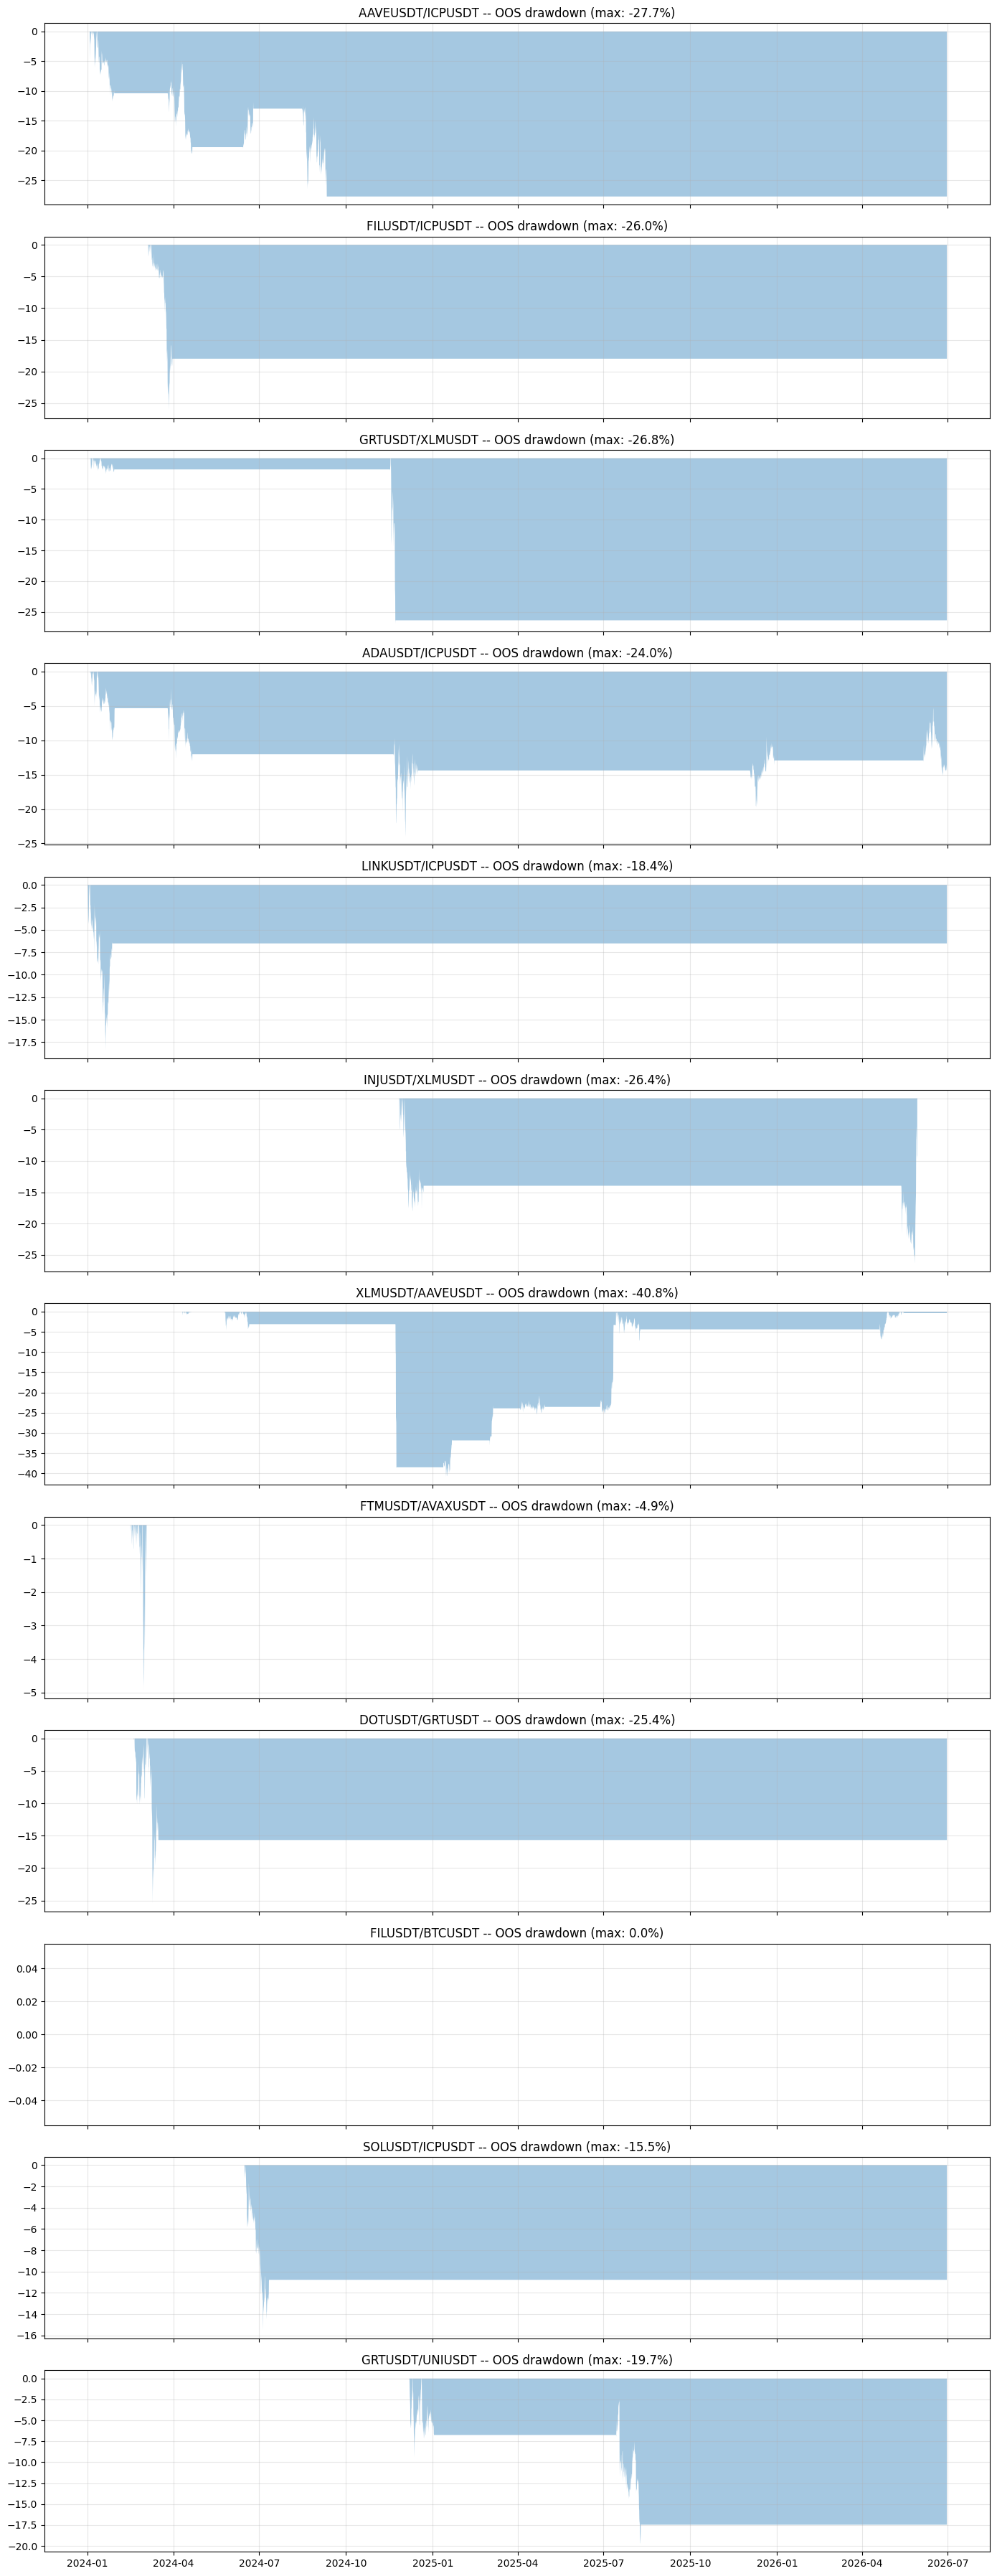

In [44]:
fig, axes = plt.subplots(len(oos_results), 1, figsize=(14, 3 * len(oos_results)), sharex=True)
if len(oos_results) == 1:
    axes = [axes]
for ax, ((x_name, y_name), res) in zip(axes, oos_results.items()):
    dd = drawdown(res['net_ret'])
    ax.fill_between(dd.index, dd * 100, 0, alpha=0.4)
    ax.set_title(f'{x_name}/{y_name} -- OOS drawdown (max: {dd.min()*100:.1f}%)')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Portfolio-Level Out-of-Sample Result

Aggregated with the same coin-netted portfolio engine used for model and window selection
in Section 13.

=== PORTFOLIO FINAL CORRECTED/PSEUDO-OOS (coin-netted quantities) ===
                               Gross         Net
Sharpe (annualized)           -0.055      -0.153
Ann. return                   -0.21%      -0.59%
Cumulative cash return        -0.72%      -1.65%

Max drawdown (net):          -11.17%
Total turnover (netted):    4.73
Total costs (cash / initial capital): 0.93%
Netted turnover saved:      0.0972 (2.1% of unnetted order notional)
Avg / max gross exposure:   5.04% / 32.07%
Avg / max coin concentration (active bars): 48.20% / 69.18%
Max single-coin weight vs equity: 12.15%


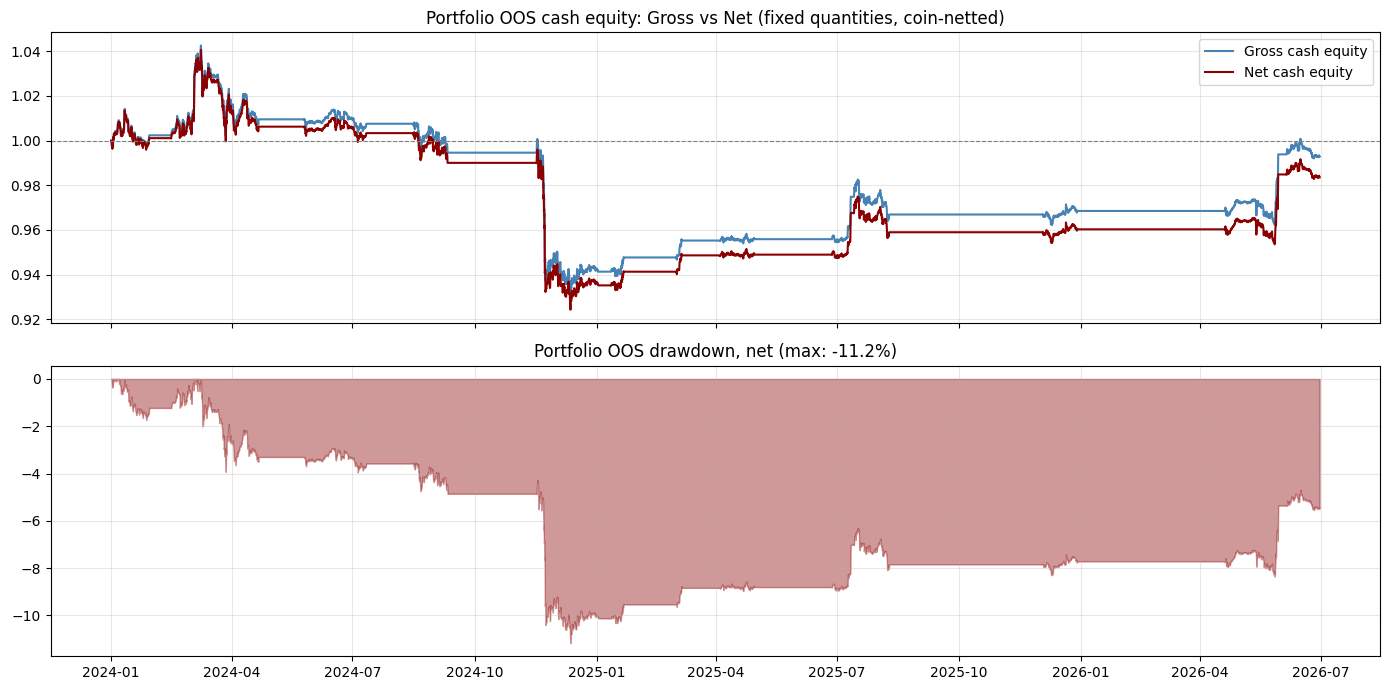

In [45]:
oos_pair_results = {(x, y): oos_results[(x, y)] for x, y in FROZEN_MODEL['pairs']}
OOS_PORTFOLIO, oos_metrics = evaluate_coin_netted_portfolio(
    oos_pair_results, FROZEN_MODEL['pairs'], px_oos_engine,
    FROZEN_MODEL['cost_per_leg_bps'], CONFIG['OOS_START'], CONFIG['OOS_END'])

portfolio_frame = OOS_PORTFOLIO['frame']
portfolio_gross_ret = portfolio_frame['gross_ret']
portfolio_net_ret = portfolio_frame['net_ret']
portfolio_dd = OOS_PORTFOLIO['drawdown']
portfolio_max_dd = oos_metrics['max_dd']

print('=== PORTFOLIO FINAL CORRECTED/PSEUDO-OOS (coin-netted quantities) ===')
print(f'{"":24s}{"Gross":>12s}{"Net":>12s}')
print(f'{"Sharpe (annualized)":24s}{oos_metrics["gross_sharpe"]:>12.3f}{oos_metrics["sharpe"]:>12.3f}')
print(f'{"Ann. return":24s}{oos_metrics["gross_ann_return"]*100:>11.2f}%{oos_metrics["ann_return"]*100:>11.2f}%')
print(f'{"Cumulative cash return":24s}{oos_metrics["gross_cum_return"]*100:>11.2f}%{oos_metrics["cum_return"]*100:>11.2f}%')
print(f'\nMax drawdown (net):          {oos_metrics["max_dd"]*100:.2f}%')
print(f'Total turnover (netted):    {oos_metrics["total_turnover"]:.2f}')
print(f'Total costs (cash / initial capital): {oos_metrics["total_costs"]*100:.2f}%')
_pair_turn = oos_metrics['pair_level_turnover_notional']
_saving = oos_metrics['netting_savings_turnover']
_saving_pct = 100 * _saving / _pair_turn if _pair_turn else 0.0
print(f'Netted turnover saved:      {_saving:.4f} ({_saving_pct:.1f}% of unnetted order notional)')
print(f'Avg / max gross exposure:   {oos_metrics["avg_gross_exposure"]:.2%} / {oos_metrics["max_gross_exposure"]:.2%}')
print(f'Avg / max coin concentration (active bars): '
      f'{oos_metrics["avg_coin_concentration"]:.2%} / {oos_metrics["max_coin_concentration"]:.2%}')
print(f'Max single-coin weight vs equity: {oos_metrics["max_single_coin_weight"]:.2%}')

# Final liquidation regression: quantities are zero on the last bar and any last-bar order
# is charged immediately in cost_cash (there is no shift that could drop it).
assert OOS_PORTFOLIO['coin_qty'].iloc[-1].abs().max() < 1e-12
_last_order_notional = (OOS_PORTFOLIO['order_qty'].iloc[-1].abs() * OOS_PORTFOLIO['coin_marks'].iloc[-1]).sum()
assert np.isclose(portfolio_frame['cost_cash'].iloc[-1],
                  _last_order_notional * FROZEN_MODEL['cost_per_leg_bps'] * 1e-4)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(portfolio_frame.index, portfolio_frame['gross_equity'], label='Gross cash equity', color='steelblue')
axes[0].plot(portfolio_frame.index, portfolio_frame['equity'], label='Net cash equity', color='darkred')
axes[0].axhline(1.0, color='grey', linewidth=0.8, linestyle='--')
axes[0].set_title('Portfolio OOS cash equity: Gross vs Net (fixed quantities, coin-netted)')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].fill_between(portfolio_dd.index, portfolio_dd * 100, 0, alpha=0.4, color='darkred')
axes[1].set_title(f'Portfolio OOS drawdown, net (max: {portfolio_max_dd*100:.1f}%)')
axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## 15. Strategy Summary

**Relationship exploited.** Temporary deviations of a cointegrated crypto pair's spread from
its calibrated long-run mean, traded as a market-neutral position sized against reversion.

**Pairs.** 12 pairs survived Engle-Granger testing with Benjamini-Hochberg FDR correction,
minimum half-life, and minimum crossing-frequency filters applied to the formation-period
(2020-2022) universe, out of 378 candidate combinations tested in both regression
directions.

**Model.** The static hedge-ratio model (S) was selected over both rolling-normalization
(RZ) and rolling-beta (RB) variants: on the 2023 coin-netted validation portfolio, S reached
a Sharpe ratio of 0.043, versus -0.891 for RZ and -1.689 for RB. Neither rolling variant
cleared the required margin over the simpler model it would have replaced, so no rolling
window was subsequently searched.

**Central assumptions.** Fixed hedge-ratio and calibration statistics from formation data;
one global entry/exit/stop parameterization shared across all 12 pairs; one global time stop
(156 bars, roughly three half-lives of the control pair) despite half-life varying
considerably across the frozen pairs (Section 8); equal initial capital across pair sleeves
in the portfolio aggregation (Section 13).

**Performance characteristics.** The 2023 validation Sharpe of 0.043 is close to zero --
materially weaker than an earlier, less conservative accounting convention had suggested,
once fixed-quantity cash accounting and next-bar execution replaced continuous weight-based
rebalancing. On the out-of-sample period
(2024-01-01 to 2026-06-30), the portfolio's net Sharpe was -0.153, with a net cumulative
return of -1.65% and a maximum drawdown of -11.17%. Gross and net cumulative returns are
close (-0.72% vs. -1.65%), indicating the negative result is not primarily a transaction-cost
effect.

**Limitations.** The validation-period edge was already weak before the out-of-sample
evaluation, and does not persist out-of-sample. The out-of-sample window itself is corrected
historical rather than a pristine holdout, for the reason noted in Sections 4 and 14. A large
share of out-of-sample trades exit via the time stop rather than ordinary mean reversion,
consistent with the half-life/time-stop mismatch noted in Section 8. Individual pair-level
out-of-sample results are not statistically meaningful given the small number of realized
trades per pair over the period and should not be used to select or rank pairs going
forward.

### Reproducibility check — permanent gate

Restart/Run All must reproduce the fixed-quantity baseline assertions, synthetic cash-ledger
reconciliation, validation FLAT-start checks, and final coin-level liquidation checks.

In [46]:
# Permanent regression gates ---------------------------------------------------
_chk_y, _chk_x = pd.Series([1.0, 2.0]), pd.Series([0.5, 1.0])
assert (compute_spread(_chk_y, _chk_x, 0.1, 0.5) == (_chk_y - 0.1 - 0.5*_chk_x)).all()

if FROZEN_MODEL['model'] in ('RZ', 'RB') and FROZEN_MODEL['rolling_window_bars'] is not None:
    _wb = FROZEN_MODEL['rolling_window_bars']; _cb = min(500, _wb * 2)
    _, _, _, _z_full = gen_rolling_signal(_x_test, _y_test, _wb,
        rolling_beta=(FROZEN_MODEL['model'] == 'RB'), frozen_alpha=0.0, frozen_beta=1.0)
    _, _, _, _z_trunc = gen_rolling_signal(_x_test.iloc[:_cb+1], _y_test.iloc[:_cb+1], _wb,
        rolling_beta=(FROZEN_MODEL['model'] == 'RB'), frozen_alpha=0.0, frozen_beta=1.0)
    assert np.isclose(_z_full.iloc[_cb], _z_trunc.iloc[_cb], equal_nan=True)

for _key, _result in MODEL_RESULTS.items():
    _val = _result.loc[CONFIG['VALIDATION_START']:CONFIG['VALIDATION_END']]
    assert _val[['qty_x','qty_y']].iloc[0].abs().sum() == 0.0

assert _synth_trade['entry_bar'] == _synth_trade['signal_entry_bar'] + 1
assert _synth_trade['exit_bar'] == _synth_trade['signal_exit_bar'] + 1
assert (_synth_result['turnover_cash'].iloc[3:6] == 0).all()
assert len(set(oos_results.keys())) == len(FROZEN_MODEL['pairs'])
assert OOS_PORTFOLIO['coin_qty'].iloc[-1].abs().max() < 1e-12

print('All v6 permanent checks PASSED: convention, no-look-ahead, FLAT validation start,')
print('next-bar execution, fixed quantities, pair isolation, and final coin liquidation.')


All v6 permanent checks PASSED: convention, no-look-ahead, FLAT validation start,
next-bar execution, fixed quantities, pair isolation, and final coin liquidation.


## 16. Standardized Evaluation Layer

Sections 1-15 above are the unmodified S0 baseline and are never edited from this point on.
Everything below is additive: new sections that reuse S0's frozen objects
(`px`, `ret`, `FROZEN_PAIRS`, `FROZEN_MODEL`, `get_tradable_price`, `fit_static_ols`,
`compute_spread`, `compute_half_life`, `run_trade_state_machine`,
`execute_fixed_quantity_pair`, `build_coin_netted_portfolio`, `drawdown`) rather than
reimplementing them.

This section builds one evaluation layer that will be applied unchanged to every model
version (S0, S1, WF1, WF2): daily-252 Sharpe, benchmark-relative statistics, and a
standardized summary-row function. The 4h portfolio equity curve remains the
source-of-truth series; daily returns are always derived from it by geometric compounding,
never computed independently, and are reconciled against it explicitly.

In [47]:
def aggregate_daily_returns(bar_net_ret, calendar_index=None):
    """Geometrically compound 4h portfolio returns into UTC daily returns.

    Days with no active position remain in the series with return 0.0 (not dropped), so the
    daily series has one row per UTC calendar day spanned by `bar_net_ret`'s index -- this is
    required for the daily-252 Sharpe convention and for exact alignment with the BTC daily
    benchmark series (Phase 2). If `calendar_index` is given, the output is reindexed onto
    it (filling any day with literally no bars, e.g. a data gap, as 0.0 -- flagged via the
    `n_bars` count so a genuine gap is distinguishable from a flat trading day).
    """
    r = bar_net_ret.fillna(0.0)
    daily_compound = (1.0 + r).groupby(r.index.floor('D')).prod() - 1.0
    n_bars = r.groupby(r.index.floor('D')).size()
    daily_compound.name = 'daily_ret'
    if calendar_index is not None:
        daily_compound = daily_compound.reindex(calendar_index, fill_value=0.0)
        n_bars = n_bars.reindex(calendar_index, fill_value=0)
    return daily_compound, n_bars


def daily_sharpe_252(daily_ret):
    """Headline Sharpe convention used consistently across every model comparison:
    daily mean return / daily std x sqrt(252). Flat (return=0) days are included in the
    mean/std computation, not dropped -- excluding them would overstate the Sharpe of any
    strategy that is flat a meaningful fraction of the time."""
    r = daily_ret.dropna()
    if len(r) == 0 or r.std() == 0:
        return np.nan
    return (r.mean() / r.std()) * np.sqrt(252)


def bars_per_year_sharpe(bar_net_ret, bars_per_year=CONFIG['BARS_PER_YEAR']):
    """Optional secondary diagnostic: the original 24/7 bar-level annualized Sharpe
    convention used in Sections 1-15. Kept only as a cross-check, never the headline number
    in any new model-comparison output."""
    r = bar_net_ret.dropna()
    if len(r) == 0 or r.std() == 0:
        return np.nan
    return (r.mean() * bars_per_year) / (r.std() * np.sqrt(bars_per_year))


# Reconciliation check: compounding the full 4h S0 OOS series into daily bars and then
# compounding the daily series back to a total return must reproduce the 4h cumulative
# return exactly (up to floating point).
_daily_chk, _ = aggregate_daily_returns(portfolio_net_ret)
_cum_from_daily = (1.0 + _daily_chk).prod() - 1.0
_cum_from_4h = (1.0 + portfolio_net_ret.fillna(0.0)).prod() - 1.0
assert np.isclose(_cum_from_daily, _cum_from_4h, atol=1e-10), (
    f'Daily aggregation does not reconcile with the 4h equity curve: '
    f'daily={_cum_from_daily:.8f} vs 4h={_cum_from_4h:.8f}')
print(f'Daily-aggregation reconciliation PASSED: cum. return from daily compounding '
      f'({_cum_from_daily:.6%}) matches the 4h equity curve ({_cum_from_4h:.6%}).')

print(f'\nS0 OOS daily-252 Sharpe: {daily_sharpe_252(_daily_chk):.4f}  '
      f'(vs. secondary 24/7 bar-annualized diagnostic: '
      f'{bars_per_year_sharpe(portfolio_net_ret):.4f}, reported in Section 14)')

Daily-aggregation reconciliation PASSED: cum. return from daily compounding (-1.648155%) matches the 4h equity curve (-1.648155%).

S0 OOS daily-252 Sharpe: -0.1155  (vs. secondary 24/7 bar-annualized diagnostic: -0.1528, reported in Section 14)


## 17. Benchmark-Relative Portfolio Statistics

A daily BTC benchmark series is built on the same UTC daily calendar as the strategy, using
`get_tradable_price` (Section 3) for consistency with how every other price series in this
notebook is constructed. Strategy and BTC daily returns are aligned exactly (same index,
inner join) before any regression.

$$\text{Strategy}_t = \alpha + \beta \cdot \text{BTC}_t + \epsilon_t$$

Alpha is annualized as $\alpha \times 252$. The conventional OLS alpha t-stat is the primary
review metric; a Newey-West/HAC t-stat is reported separately as a robustness check, since
daily strategy returns compounded from 4h bars can carry short-horizon autocorrelation that
OLS standard errors do not account for.

In [48]:
def build_btc_daily_benchmark(calendar_index, price_data=px):
    """Daily BTC return series on the same UTC calendar as the strategy's daily returns,
    built via the same get_tradable_price/geometric-compounding path as the strategy series
    for an apples-to-apples comparison."""
    btc_price = get_tradable_price(price_data['BTCUSDT'])
    btc_ret = btc_price.pct_change(fill_method=None)
    btc_daily, _ = aggregate_daily_returns(btc_ret, calendar_index=calendar_index)
    return btc_daily


def benchmark_regression_stats(strategy_daily, btc_daily):
    """OLS: strategy_daily = alpha + beta*btc_daily + eps, on the exact-aligned intersection
    of both daily series. Returns correlation, beta, daily/annualized alpha, conventional OLS
    alpha t-stat (primary), Newey-West/HAC alpha t-stat (robustness, clearly separate), and R^2.
    """
    d = pd.concat([strategy_daily.rename('strat'), btc_daily.rename('btc')], axis=1).dropna()
    if len(d) < 10 or d['btc'].std() == 0:
        return {k: np.nan for k in ['n_obs', 'correlation', 'beta', 'daily_alpha',
                                     'ann_alpha', 'alpha_tstat_ols', 'alpha_tstat_hac', 'r_squared']}
    X = sm.add_constant(d['btc'].values)
    y = d['strat'].values
    ols_model = sm.OLS(y, X).fit()
    hac_model = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
    return {
        'n_obs': len(d),
        'correlation': d['strat'].corr(d['btc']),
        'beta': ols_model.params[1],
        'daily_alpha': ols_model.params[0],
        'ann_alpha': ols_model.params[0] * 252,
        'alpha_tstat_ols': ols_model.tvalues[0],
        'alpha_tstat_hac': hac_model.tvalues[0],
        'r_squared': ols_model.rsquared,
    }


# Applied to S0 OOS as a worked example / regression check for the function itself.
_s0_btc_daily = build_btc_daily_benchmark(_daily_chk.index)
_s0_bench_stats = benchmark_regression_stats(_daily_chk, _s0_btc_daily)
print('S0 OOS benchmark-relative statistics (daily, UTC-aligned):')
for k, v in _s0_bench_stats.items():
    print(f'  {k:18s}: {v:.4f}' if isinstance(v, float) else f'  {k:18s}: {v}')

S0 OOS benchmark-relative statistics (daily, UTC-aligned):
  n_obs             : 912
  correlation       : 0.0235
  beta              : 0.0020
  daily_alpha       : -0.0000
  ann_alpha         : -0.0043
  alpha_tstat_ols   : -0.2391
  alpha_tstat_hac   : -0.2107
  r_squared         : 0.0005


## 18. S1 — Static Model with Pair-Specific Half-Life Time Stops

`S1_STATIC_PAIR_HALFLIFE_STOP` is identical to S0 in every respect except the time stop.
S0 uses one global `TIME_STOP_BARS = 156` for all 12 pairs, set from the control pair's own
half-life (Section 8) -- pairs with a substantially longer or shorter half-life are cut
loose on a schedule that has no relationship to their own mean-reversion speed. S1 replaces
this with a pair-specific stop:

$$\text{TimeStop}_{pair} = \lceil 2.5 \times \text{HalfLife}_{pair} \rceil$$

Half-life is estimated **exclusively from formation data** (`compute_half_life`, Section 6 --
reused verbatim, not reimplemented) -- the same estimate already computed for each frozen
pair during screening (`screen_df`/`candidate_pairs`, Section 6). No half-life is
recalculated using validation or OOS data. If a pair's half-life is invalid, non-positive,
infinite, or otherwise not interpretable, S1 marks the pair ineligible for S1 rather than
forcing a fallback time stop -- consistent with how the same condition is already handled
in `compute_half_life` and the Section 6 screen.

Two robustness multipliers (2.0x, 3.0x) are computed alongside the primary 2.5x
specification below, per the pre-specified sensitivity list (Phase 9) -- no additional
multipliers are searched, and none is selected based on 2024-2026 performance.

In [49]:
def compute_pair_time_stops(pairs, formation_px, multiplier):
    """Pair-specific time stop = ceil(multiplier * formation-period half-life), using
    ONLY formation-window prices (CONFIG['FORMATION_START':'FORMATION_END'] implicitly, via
    the `formation_px` argument). Reuses fit_static_ols/compute_spread/compute_half_life
    verbatim -- the same functions used for the Section 6 screen -- so a pair's S1 half-life
    is identical to its already-computed, already-frozen screening-stage half-life.

    Returns (time_stops: dict[pair -> int bars], ineligible: list[pairs]). A pair whose
    formation half-life is non-positive/infinite is marked ineligible rather than assigned a
    fallback stop, matching compute_half_life's own non-interpretability convention.
    """
    time_stops, ineligible = {}, []
    for x_name, y_name in pairs:
        log_x = np.log(formation_px[x_name])
        log_y = np.log(formation_px[y_name])
        a, b, _ = fit_static_ols(log_y, log_x)
        spread = compute_spread(log_y, log_x, a, b)
        hl = compute_half_life(spread)
        if not np.isfinite(hl) or hl <= 0:
            ineligible.append((x_name, y_name))
            continue
        time_stops[(x_name, y_name)] = int(np.ceil(multiplier * hl))
    return time_stops, ineligible


S1_TIME_STOP_MULTIPLIER = 2.5  # primary specification -- see Phase 9 for 2.0x/3.0x robustness only

s1_time_stops, s1_ineligible = compute_pair_time_stops(FROZEN_PAIRS, formation_px, S1_TIME_STOP_MULTIPLIER)

print(f'S1 pair-specific time stops (multiplier={S1_TIME_STOP_MULTIPLIER}x formation half-life):')
for (x, y), ts in sorted(s1_time_stops.items(), key=lambda kv: kv[1]):
    print(f'  {x:12s}/{y:10s}: {ts:4d} bars  (S0 global stop: {CONFIG["TIME_STOP_BARS"]})')
if s1_ineligible:
    print(f'\nIneligible for S1 (non-interpretable formation half-life): {s1_ineligible}')
else:
    print('\nAll frozen pairs have an interpretable formation half-life -- none marked ineligible.')

assert len(s1_time_stops) + len(s1_ineligible) == len(FROZEN_PAIRS)

S1 pair-specific time stops (multiplier=2.5x formation half-life):
  AAVEUSDT    /ICPUSDT   :   99 bars  (S0 global stop: 156)
  FILUSDT     /ICPUSDT   :  129 bars  (S0 global stop: 156)
  GRTUSDT     /XLMUSDT   :  156 bars  (S0 global stop: 156)
  ADAUSDT     /ICPUSDT   :  158 bars  (S0 global stop: 156)
  LINKUSDT    /ICPUSDT   :  189 bars  (S0 global stop: 156)
  INJUSDT     /XLMUSDT   :  196 bars  (S0 global stop: 156)
  XLMUSDT     /AAVEUSDT  :  258 bars  (S0 global stop: 156)
  FTMUSDT     /AVAXUSDT  :  444 bars  (S0 global stop: 156)
  DOTUSDT     /GRTUSDT   :  541 bars  (S0 global stop: 156)
  FILUSDT     /BTCUSDT   :  569 bars  (S0 global stop: 156)
  SOLUSDT     /ICPUSDT   :  571 bars  (S0 global stop: 156)
  GRTUSDT     /UNIUSDT   :  650 bars  (S0 global stop: 156)

All frozen pairs have an interpretable formation half-life -- none marked ineligible.


In [50]:
def run_s1_on_pair(x_name, y_name, time_stop_bars, price_data, ret_data, state_start=None):
    """S1 = S0's Model-S signal/backtest path (formation-fit alpha/beta, formation-frozen
    calibration) with only the time stop replaced. Everything else -- entry/exit/hard-stop
    thresholds, execution delay, cost assumptions, position sizing -- is taken from CONFIG,
    identical to S0."""
    x_price = get_tradable_price(price_data[x_name])
    y_price = get_tradable_price(price_data[y_name])
    ret_x = x_price.pct_change(fill_method=None)
    ret_y = y_price.pct_change(fill_method=None)

    log_x_form = np.log(x_price.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']])
    log_y_form = np.log(y_price.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']])
    fit_data_form = pd.concat([log_x_form, log_y_form], axis=1).dropna()
    fit_data_form.columns = ['x', 'y']
    a0, b0, _ = fit_static_ols(fit_data_form['y'], fit_data_form['x'])

    log_x, log_y = np.log(x_price), np.log(y_price)
    spread = compute_spread(log_y, log_x, a0, b0)
    spread_mean = spread.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']].mean()
    spread_std = spread.loc[CONFIG['FORMATION_START']:CONFIG['FORMATION_END']].std()
    z_score = (spread - spread_mean) / spread_std
    beta_series = pd.Series(b0, index=x_price.index)

    untradable = x_price.isna() | y_price.isna()
    z_score = z_score.where(~untradable, np.nan)

    result, trades = backtest_single_pair(
        x_price, y_price, a0, b0, ret_x, ret_y,
        entry_z=CONFIG['ENTRY_Z'], exit_z=CONFIG['EXIT_Z'], hard_stop_z=CONFIG['HARD_STOP_Z'],
        time_stop_bars=time_stop_bars, cost_per_leg_bps=CONFIG['COST_PER_LEG_BPS'],
        z_score=z_score, beta_series=beta_series, state_start=state_start)
    return result, trades


def run_s1_universe(pairs, time_stops, price_data, ret_data, state_start):
    """Run S1 on every eligible pair (pairs missing from `time_stops` are skipped -- they
    were marked ineligible upstream) and return per-pair results/trades keyed like
    MODEL_RESULTS/MODEL_TRADES."""
    results, trades_d = {}, {}
    for x_name, y_name in pairs:
        if (x_name, y_name) not in time_stops:
            continue
        result, trades = run_s1_on_pair(
            x_name, y_name, time_stops[(x_name, y_name)], price_data, ret_data, state_start)
        results[(x_name, y_name)] = result
        trades_d[(x_name, y_name)] = trades
    return results, trades_d


S1_ELIGIBLE_PAIRS = [p for p in FROZEN_PAIRS if p in s1_time_stops]

# OOS run (2024-2026, cut at OOS_END, FLAT start at OOS_START -- identical convention to S0 Section 14)
px_oos_engine_s1 = px.loc[:CONFIG['OOS_END']]
ret_oos_engine_s1 = ret.loc[:CONFIG['OOS_END']]
S1_OOS_RESULTS, S1_OOS_TRADES = run_s1_universe(
    S1_ELIGIBLE_PAIRS, s1_time_stops, px_oos_engine_s1, ret_oos_engine_s1, CONFIG['OOS_START'])
S1_OOS_RESULTS = {k: v.loc[CONFIG['OOS_START']:CONFIG['OOS_END']] for k, v in S1_OOS_RESULTS.items()}

for (x, y), result in S1_OOS_RESULTS.items():
    assert result[['qty_x','qty_y']].iloc[0].abs().sum() == 0.0
    assert result[['qty_x','qty_y']].iloc[-1].abs().sum() == 0.0
print(f'S1 OOS run complete on {len(S1_OOS_RESULTS)} pairs. FLAT-start / flat-end checks PASSED.')

S1 OOS run complete on 12 pairs. FLAT-start / flat-end checks PASSED.


### S0 vs. S1 — Standardized Comparison

Both models are aggregated through the same coin-netted portfolio engine
(`build_coin_netted_portfolio`, Section 13) and the same daily-252 Sharpe convention
(Section 16), so the comparison below is on a like-for-like basis. S1 uses only the 12
pairs already frozen for S0 -- Phase 3 changes exclusively the time stop, not pair
selection.

In [51]:
def exit_reason_fractions(trades_dict):
    """Fraction of exits by reason, pooled across all pairs. Hard-stop/time-stop/
    mean-reversion buckets map to the state machine's exit_reason values (Section 9);
    force_close_missing_data and end_of_sample are reported separately since they are data
    boundary effects, not economically meaningful exit types."""
    all_reasons = [t['exit_reason'] for trades in trades_dict.values() for t in trades]
    if not all_reasons:
        return {}
    s = pd.Series(all_reasons).value_counts(normalize=True)
    return s.to_dict()


def trade_pnl_stats(trades_dict):
    """Win rate, average/median trade return (net_pnl as a fraction of that trade's entry
    equity, i.e. per-pair-sleeve return -- consistent with each pair's own initial_equity=1.0
    convention in execute_fixed_quantity_pair)."""
    all_trades = [t for trades in trades_dict.values() for t in trades]
    if not all_trades:
        return {'win_rate': np.nan, 'avg_trade_return': np.nan, 'median_trade_return': np.nan}
    rets = []
    for t in all_trades:
        entry_eq = t.get('entry_equity_before')
        exit_eq = t.get('exit_equity_after')
        if entry_eq is not None and exit_eq is not None and entry_eq != 0:
            rets.append((exit_eq - entry_eq) / entry_eq)
    if not rets:
        return {'win_rate': np.nan, 'avg_trade_return': np.nan, 'median_trade_return': np.nan}
    rets = np.array(rets)
    return {'win_rate': (rets > 0).mean(), 'avg_trade_return': rets.mean(), 'median_trade_return': np.median(rets)}


def standardized_model_summary(model_id, pair_results, pairs, price_data, cost_per_leg_bps,
                                 start, end, trades_dict=None):
    """One row per model, built from build_coin_netted_portfolio + the daily-252/benchmark
    layer (Sections 16-17) -- the single shared summary function every model version
    (S0, S1, WF1, WF2) reports through, so outputs are directly comparable (Phase 8)."""
    portfolio, metrics = evaluate_coin_netted_portfolio(
        pair_results, pairs, price_data, cost_per_leg_bps, start, end)
    f = portfolio['frame']
    daily_ret, n_bars_per_day = aggregate_daily_returns(f['net_ret'])
    btc_daily = build_btc_daily_benchmark(daily_ret.index, price_data)
    bench = benchmark_regression_stats(daily_ret, btc_daily)

    if trades_dict is not None:
        all_trades = [t for trades in trades_dict.values() for t in trades]
        durations = [t['duration_bars'] for t in all_trades]
        exit_fracs = exit_reason_fractions(trades_dict)
        pnl_stats = trade_pnl_stats(trades_dict)
    else:
        all_trades, durations, exit_fracs, pnl_stats = [], [], {}, {'win_rate': np.nan, 'avg_trade_return': np.nan, 'median_trade_return': np.nan}

    time_in_market = (f['gross_exposure'] > 0).mean()

    row = {
        'model': model_id,
        'daily_sharpe_252': daily_sharpe_252(daily_ret),
        'bar_sharpe_secondary': metrics['sharpe'],
        'ann_volatility': metrics['ann_vol'],
        'cum_net_return': metrics['cum_return'],
        'cum_gross_return': metrics['gross_cum_return'],
        'max_drawdown': metrics['max_dd'],
        'n_trades': len(all_trades),
        'n_pairs_traded': len({k for k, trades in (trades_dict or {}).items() if trades}),
        'win_rate': pnl_stats['win_rate'],
        'avg_trade_return': pnl_stats['avg_trade_return'],
        'median_trade_return': pnl_stats['median_trade_return'],
        'avg_holding_bars': np.mean(durations) if durations else np.nan,
        'median_holding_bars': np.median(durations) if durations else np.nan,
        'time_in_market_pct': time_in_market,
        'turnover': metrics['total_turnover'],
        'pct_exit_mean_reversion': exit_fracs.get('exit', 0.0),
        'pct_exit_time_stop': exit_fracs.get('time_stop', 0.0),
        'pct_exit_hard_stop': exit_fracs.get('hard_stop', 0.0),
        'total_costs_pct': metrics['total_costs'],
        'btc_correlation': bench['correlation'],
        'btc_beta': bench['beta'],
        'ann_alpha': bench['ann_alpha'],
        'alpha_tstat_ols': bench['alpha_tstat_ols'],
        'alpha_tstat_hac': bench['alpha_tstat_hac'],
        'r_squared': bench['r_squared'],
    }
    return row, portfolio

In [52]:
S0_ROW, S0_OOS_PORTFOLIO_STD = standardized_model_summary(
    'S0_STATIC_BASELINE', oos_pair_results, FROZEN_MODEL['pairs'], px_oos_engine,
    FROZEN_MODEL['cost_per_leg_bps'], CONFIG['OOS_START'], CONFIG['OOS_END'],
    trades_dict=oos_trades)

S1_ROW, S1_OOS_PORTFOLIO = standardized_model_summary(
    'S1_STATIC_PAIR_HALFLIFE_STOP', S1_OOS_RESULTS, S1_ELIGIBLE_PAIRS, px_oos_engine_s1,
    CONFIG['COST_PER_LEG_BPS'], CONFIG['OOS_START'], CONFIG['OOS_END'],
    trades_dict=S1_OOS_TRADES)

s0_vs_s1_df = pd.DataFrame([S0_ROW, S1_ROW]).set_index('model')
print('S0 vs. S1 -- OOS (2024-01-01 to 2026-06-30), standardized comparison:')
s0_vs_s1_df.round(4).T

S0 vs. S1 -- OOS (2024-01-01 to 2026-06-30), standardized comparison:


model,S0_STATIC_BASELINE,S1_STATIC_PAIR_HALFLIFE_STOP
daily_sharpe_252,-0.1155,-0.1249
bar_sharpe_secondary,-0.1528,-0.1613
ann_volatility,0.0387,0.0416
cum_net_return,-0.0165,-0.0188
cum_gross_return,-0.0072,-0.0092
max_drawdown,-0.1117,-0.1053
n_trades,29.0000,29.0000
n_pairs_traded,11.0000,11.0000
win_rate,0.4828,0.5517
avg_trade_return,-0.0024,0.0013


## 18.5 Walk-Forward Methodology Corrections

Expert review of Sections 19+ (below) identified several methodological inconsistencies
between the walk-forward framework and the static S0 baseline it is meant to be compared
against. These are corrected here, before any stability/WF1/WF2 result is (re-)computed, and
every cache from the previous version of this notebook is invalidated so no stale result can
be silently reused.

**Corrections applied:**

1. **True 12-month formation coverage** (previously: ~100 bars / ~17 days was enough to
   "qualify" a pair -- not a 12-month test at all). Now requires ~90% coverage of a full
   12-month window (~1,970 of ~2,190 bars).
2. **Active-at-rebalance requirement**: an asset must still be trading (have a valid price)
   at the rebalance date itself, not merely have had enough history earlier in the window.
   This is applied point-in-time -- a later delisting does not retroactively exclude an asset
   from earlier rebalances.
3. **XMR re-included**: only true stablecoins (`USDCUSDT`, `FDUSDUSDT`) are manually excluded
   in the walk-forward universe. XMR is eligible wherever the point-in-time rules above allow
   it (it delists from Binance in Feb 2024, so it is eligible for early rebalances and
   ineligible from mid-2024 onward -- exactly the point-in-time behavior the correction
   requires, and the same logic now also correctly excludes `FTMUSDT`/`MKRUSDT` once their
   own trading history ends, without needing to hardcode them).
4. **WF1 pair-quality filters now match S0 exactly**: same `MAX_HALF_LIFE_BARS=300` and
   `MIN_CROSSINGS=15` filters used in Section 6, plus a new positive-Beta requirement (see
   #5), applied at every rebalance in the same order S0 applies them once.
5. **Positive-Beta requirement**: pairs with a negative formation-period Beta imply a
   same-direction (long/long or short/short) trade rather than a conventional market-neutral
   relative-value position. The primary specification requires Beta > 0; negative-Beta pairs
   are marked ineligible rather than traded.
6. **Full methodology-aware cache versioning**: every cache key below is a hash of every
   parameter that affects its result (universe construction, coverage rule, EG alpha, FDR
   method, half-life/crossing/beta filters, rebalance schedule) so that changing any one of
   them automatically invalidates the cache rather than silently reusing a stale result.

None of these are performance-motivated -- each is either a data-integrity fix (coverage,
active-at-rebalance) or a consistency fix (same filters as S0) or an economic-definition fix
(positive Beta). Section 19 onward is re-run in full under these corrected rules; the
"almost no pair persists" finding from the previous version of this notebook is **not**
carried forward as a conclusion until the corrected numbers are in.

**Scope note on universe size.** The feedback explicitly asks to re-include XMR and to keep
only true stablecoins in `MANUAL_EXCLUDE`. Combined with the corrected point-in-time
coverage + active-at-rebalance eligibility (feedback #2), this has a larger side effect than
just adding XMR back: the ~17 coins S0 dropped via a one-time `MIN_HISTORY_CUTOFF` cutoff
(e.g. `PEPEUSDT`, `SUIUSDT`, `ARBUSDT`, `OPUSDT`, `TAOUSDT`) are also no longer manually
excluded, since the point-in-time rules are designed to handle exactly this case -- a
late-listed coin simply lacks 12 months of 90%-coverage history until it has traded long
enough, and becomes eligible automatically once it does, with no hardcoded cutoff needed.
The walk-forward universe (`WF_PX`/`WF_RET`) is therefore 45 coins (47 raw minus 2
stablecoins), not 27. This is judged consistent with the feedback's stated principle (manual
exclusion only for an ex-ante methodological reason, not a data-availability workaround) but
is flagged explicitly here since the feedback's own wording only mentions XMR by name -- if
this is not the intended scope, the fix is a one-line change to `WF_CONFIG['MANUAL_EXCLUDE']`.

**Role of correlation (feedback #5).** Return correlation is used as a descriptive
relationship characteristic and not as a formal pair-selection criterion anywhere in this
notebook: every eligible pair is tested for Engle-Granger cointegration directly, the full
directional-test family is Benjamini-Hochberg corrected, and only afterward is the pair's
return correlation computed and reported alongside the other formation-period statistics
(`return_correlation` column throughout Sections 19-20). No pair is excluded on the basis of
its correlation value.

In [53]:
WF_CONFIG = {
    # Universe: only true stablecoins are manually excluded (feedback #8). Coverage +
    # active-at-rebalance rules (below) handle late listings and delistings point-in-time,
    # so no other coin needs to be hardcoded out.
    'MANUAL_EXCLUDE': ['USDCUSDT', 'FDUSDUSDT'],

    # True 12-month formation coverage (feedback #2). 12 months * 365.25/12 * 6 bars/day.
    'FORMATION_MONTHS': 12,
    'BARS_PER_DAY': CONFIG['BARS_PER_DAY'],
    'MIN_COVERAGE_FRACTION': 0.90,

    # Same statistical/pair-quality rules as S0's own screen (feedback #4), applied at every
    # rebalance instead of once. MAX_HALF_LIFE_BARS/MIN_CROSSINGS are copied verbatim from
    # Section 6 (cell 28) so both models use identical thresholds.
    'EG_ALPHA': CONFIG['EG_ALPHA'],
    'FDR_METHOD': CONFIG['FDR_METHOD'],
    'MAX_HALF_LIFE_BARS': 300,
    'MIN_CROSSINGS': 15,
    'REQUIRE_POSITIVE_BETA': True,   # feedback #6 -- primary specification

    # Rebalance schedule (unchanged from the primary WF1 specification)
    'REBALANCE_MONTHS_PRIMARY': 6,
    'REBALANCE_MONTHS_ROBUSTNESS': 3,
    'TIME_STOP_MULTIPLIER_PRIMARY': 2.5,
}
_expected_bars_per_year = 365.25 * WF_CONFIG['BARS_PER_DAY']
WF_CONFIG['FORMATION_WINDOW_BARS_NOMINAL'] = int(round(_expected_bars_per_year * (WF_CONFIG['FORMATION_MONTHS'] / 12)))
WF_CONFIG['MIN_OBS_FOR_TEST'] = int(round(WF_CONFIG['FORMATION_WINDOW_BARS_NOMINAL'] * WF_CONFIG['MIN_COVERAGE_FRACTION']))

for k, v in WF_CONFIG.items():
    print(f'{k:32s} = {v}')

MANUAL_EXCLUDE                   = ['USDCUSDT', 'FDUSDUSDT']
FORMATION_MONTHS                 = 12
BARS_PER_DAY                     = 6
MIN_COVERAGE_FRACTION            = 0.9
EG_ALPHA                         = 0.05
FDR_METHOD                       = fdr_bh
MAX_HALF_LIFE_BARS               = 300
MIN_CROSSINGS                    = 15
REQUIRE_POSITIVE_BETA            = True
REBALANCE_MONTHS_PRIMARY         = 6
REBALANCE_MONTHS_ROBUSTNESS      = 3
TIME_STOP_MULTIPLIER_PRIMARY     = 2.5
FORMATION_WINDOW_BARS_NOMINAL    = 2192
MIN_OBS_FOR_TEST                 = 1973


In [54]:
# The walk-forward universe only manually excludes true stablecoins (WF_CONFIG['MANUAL_EXCLUDE']),
# unlike S0's `px`/`ret` (Section 3) which additionally hardcoded XMRUSDT and dropped every
# coin first observed after MIN_HISTORY_CUTOFF. Late listings and XMR's Feb-2024 delisting are
# instead handled point-in-time by the coverage + active-at-rebalance rules below (feedback #8),
# so WF_PX/WF_RET are rebuilt fresh from the raw pickles rather than reusing S0's already-cut px/ret.
# See the scope note above: this also re-includes late-listed coins S0 dropped via a one-time cutoff.
with open('px.pkl', 'rb') as f:
    _wf_px_raw = pickle.load(f)
with open('ret.pkl', 'rb') as f:
    _wf_ret_raw = pickle.load(f)

WF_PX = _wf_px_raw.drop(columns=WF_CONFIG['MANUAL_EXCLUDE'])
WF_RET = _wf_ret_raw.drop(columns=WF_CONFIG['MANUAL_EXCLUDE'])
print(f'Walk-forward universe: {WF_PX.shape[1]} coins (vs. S0\'s statically-filtered {px.shape[1]} '
      f'coins -- WF_PX keeps XMR and every late-listed coin S0 dropped via a one-time cutoff, '
      f'relying instead on the point-in-time coverage/active-at-rebalance rules below).')
print(f'Coins in WF_PX but not in S0\'s px: {sorted(set(WF_PX.columns) - set(px.columns))}')
assert 'XMRUSDT' in WF_PX.columns, 'XMR must be present in the walk-forward universe (feedback #8).'

Walk-forward universe: 45 coins (vs. S0's statically-filtered 28 coins -- WF_PX keeps XMR and every late-listed coin S0 dropped via a one-time cutoff, relying instead on the point-in-time coverage/active-at-rebalance rules below).
Coins in WF_PX but not in S0's px: ['APTUSDT', 'ARBUSDT', 'ENAUSDT', 'FLOKIUSDT', 'IMXUSDT', 'JUPUSDT', 'LDOUSDT', 'OPUSDT', 'PEPEUSDT', 'POLUSDT', 'RENDERUSDT', 'SEIUSDT', 'SUIUSDT', 'TAOUSDT', 'TIAUSDT', 'TONUSDT', 'XMRUSDT']


### Research-Scope Limitation (Feedback #13)

This notebook is a research-learning project, not a production trading-strategy
specification. The backtest uses Binance spot reference price data and a simplified
short-leg implementation (a signed notional position, not a modeled borrow or perpetual
contract). A production-grade implementation would additionally need to model the actual
shorting instrument (e.g. perpetual futures), funding or borrow costs, execution liquidity
and slippage beyond the flat per-leg cost assumption, and instrument-specific fees. None of
this is implemented here, and implementing it is explicitly out of scope for the current
research pipeline -- this note exists so the numbers in this notebook are not read as a
production P&L estimate.

### Asset-Level I(1) Diagnostic (Feedback #7)

The Engle-Granger cointegration framework assumes the underlying price series are compatible
with an I(1) process (non-stationary in levels, stationary in first differences). This is a
one-time, methodological documentation check on the research universe -- it does not filter
or select any asset; it establishes whether the I(1) assumption is defensible for the assets
Engle-Granger is applied to throughout this notebook.

In [55]:
def i1_diagnostic_table(price_data, min_obs=500):
    """ADF test on log-price levels and on first differences (log returns) for every asset
    with sufficient history. I(1)-compatible = level ADF fails to reject a unit root (p > 0.05,
    i.e. non-stationary in levels) AND the first difference rejects a unit root (p <= 0.05,
    i.e. stationary in differences)."""
    rows = []
    for coin in price_data.columns:
        s = price_data[coin].dropna()
        if len(s) < min_obs:
            continue
        log_s = np.log(s)
        log_diff = log_s.diff().dropna()
        try:
            level_stat, level_p, *_ = adfuller(log_s.values, autolag='AIC')
            diff_stat, diff_p, *_ = adfuller(log_diff.values, autolag='AIC')
        except Exception as e:
            continue
        i1_compatible = (level_p > 0.05) and (diff_p <= 0.05)
        rows.append({'asset': coin, 'level_adf_pvalue': level_p, 'diff_adf_pvalue': diff_p,
                     'i1_compatible': 'Yes' if i1_compatible else 'No', 'n_obs': len(s)})
    return pd.DataFrame(rows).sort_values('asset').reset_index(drop=True)


I1_DIAGNOSTIC_DF = i1_diagnostic_table(px)
n_compatible = (I1_DIAGNOSTIC_DF['i1_compatible'] == 'Yes').sum()
print(f'I(1) diagnostic: {n_compatible}/{len(I1_DIAGNOSTIC_DF)} assets are I(1)-compatible '
      f'(non-stationary in log-price level, stationary in log-return).')
if n_compatible < len(I1_DIAGNOSTIC_DF):
    not_compat = I1_DIAGNOSTIC_DF[I1_DIAGNOSTIC_DF['i1_compatible'] == 'No']['asset'].tolist()
    print(f'Not clearly I(1)-compatible on this test: {not_compat} -- Engle-Granger results '
          f'involving these assets should be interpreted with additional caution, but they are '
          f'not removed from the universe (this is a documentation diagnostic, not a filter, '
          f'per the feedback: "do not create a large new optimization/filtering layer").')
I1_DIAGNOSTIC_DF.round(4)

I(1) diagnostic: 24/28 assets are I(1)-compatible (non-stationary in log-price level, stationary in log-return).
Not clearly I(1)-compatible on this test: ['ETHUSDT', 'HBARUSDT', 'ICPUSDT', 'LINKUSDT'] -- Engle-Granger results involving these assets should be interpreted with additional caution, but they are not removed from the universe (this is a documentation diagnostic, not a filter, per the feedback: "do not create a large new optimization/filtering layer").


,asset,level_adf_pvalue,diff_adf_pvalue,i1_compatible,n_obs
0,AAVEUSDT,0.0653,0.0,Yes,12505
1,ADAUSDT,0.1440,0.0,Yes,14232
2,ATOMUSDT,0.7132,0.0,Yes,14232
3,AVAXUSDT,0.1579,0.0,Yes,12642
4,BNBUSDT,0.1503,0.0,Yes,14232
5,BTCUSDT,0.2823,0.0,Yes,14232
6,DOGEUSDT,0.1713,0.0,Yes,14232
7,DOTUSDT,0.9009,0.0,Yes,12848
8,ETHUSDT,0.0417,0.0,No,14232
9,FILUSDT,0.8713,0.0,Yes,12501


## 19. Relationship-Stability Diagnostics

Before implementing dynamic (walk-forward) trading, this section builds a purely descriptive
diagnostic layer: at a sequence of historical rebalance dates, every candidate pair is
re-screened using a trailing 12-month formation window, and the results are stored
longitudinally. This answers "do statistically significant pair relationships persist across
time, or do they structurally break?" -- independent of any trading decision, and without
introducing any new optimized threshold. The same significance rule already frozen in
Section 6 (Engle-Granger + Benjamini-Hochberg FDR, `CONFIG['EG_ALPHA']`) is reused verbatim.

Every statistic at rebalance date $t$ uses **only** price data strictly before $t$ -- this is
exactly the point-in-time constraint the later walk-forward models (WF1, WF2) must also
satisfy, so this section doubles as a dry run of that logic before it is used to trade.

In [56]:
REBALANCE_DATES = pd.date_range('2021-01-01', CONFIG['OOS_END'], freq='6MS', tz=None)
REBALANCE_DATES = [d for d in REBALANCE_DATES if d >= pd.Timestamp(CONFIG['FORMATION_START']) + pd.DateOffset(months=12)]
print(f'{len(REBALANCE_DATES)} historical rebalance dates (12-month trailing formation, 6-month spacing):')
print([d.date() for d in REBALANCE_DATES])

11 historical rebalance dates (12-month trailing formation, 6-month spacing):
[datetime.date(2021, 1, 1), datetime.date(2021, 7, 1), datetime.date(2022, 1, 1), datetime.date(2022, 7, 1), datetime.date(2023, 1, 1), datetime.date(2023, 7, 1), datetime.date(2024, 1, 1), datetime.date(2024, 7, 1), datetime.date(2025, 1, 1), datetime.date(2025, 7, 1), datetime.date(2026, 1, 1)]


In [57]:
def check_active_at_rebalance(price_data, coins, rebalance_date, lookback_bars=3):
    """An asset is 'active at rebalance' if it has a valid (non-NaN) price within the last
    `lookback_bars` bars strictly before rebalance_date -- a small tolerance for isolated data
    gaps, not a loophole for genuinely delisted assets (Binance delistings leave a long
    trailing all-NaN tail, e.g. XMRUSDT after 2024-02-20, which this correctly fails).
    """
    check_window = price_data[coins].loc[:rebalance_date - pd.Timedelta(hours=4)].tail(lookback_bars)
    return check_window.notna().any(axis=0)


def screen_pairs_at_date(rebalance_date, price_data, coins, eg_alpha=WF_CONFIG['EG_ALPHA'],
                          min_obs=WF_CONFIG['MIN_OBS_FOR_TEST'], formation_months=WF_CONFIG['FORMATION_MONTHS'],
                          max_half_life_bars=WF_CONFIG['MAX_HALF_LIFE_BARS'],
                          min_crossings=WF_CONFIG['MIN_CROSSINGS'],
                          require_positive_beta=WF_CONFIG['REQUIRE_POSITIVE_BETA']):
    """Point-in-time pair screen, corrected per expert feedback to match S0's own screen
    exactly (Section 6) plus true 12-month coverage and active-at-rebalance eligibility:

    1. Eligibility: >= min_obs valid observations in the trailing formation window (true
       ~90%-coverage 12-month requirement, not the previous ~17-day threshold) AND the asset
       must still be actively trading at rebalance_date (check_active_at_rebalance above).
    2. Engle-Granger cointegration test, both directions, run on EVERY eligible pair -- return
       correlation is NOT used as a pre-filter here (feedback #5). Return correlation is
       computed and reported below purely as a descriptive relationship characteristic, not
       as a formal pair-selection criterion: every eligible pair is cointegration-tested
       regardless of its correlation, and only the cointegration p-value (after BH correction)
       determines qualification.
    3. Benjamini-Hochberg FDR correction over the full directional-test family at this date.
    4/5. Valid positive half-life below max_half_life_bars (same MAX_HALF_LIFE_BARS=300 used
       in S0's Section 6 screen).
    6. Minimum mean-crossing count (same MIN_CROSSINGS=15 used in S0's Section 6 screen).
    7. Positive Hedge Ratio (Beta > 0) if require_positive_beta -- feedback #6.

    All filters use ONLY the trailing `formation_months` of data strictly before
    `rebalance_date`. Returns a dataframe with one row per unordered pair that survives every
    filter at this date (empty if none survive).
    """
    window_start = rebalance_date - pd.DateOffset(months=formation_months)
    window_px = price_data.loc[window_start:rebalance_date - pd.Timedelta(hours=4)]
    assert window_px.index.max() < rebalance_date, 'Leakage: formation window reaches rebalance date.'

    # Eligibility: true formation coverage AND active at the rebalance date (feedback #2).
    coverage_ok = window_px[coins].notna().sum() >= min_obs
    active_ok = check_active_at_rebalance(price_data, coins, rebalance_date)
    valid_coins = [c for c in coins if coverage_ok.get(c, False) and active_ok.get(c, False)]
    if len(valid_coins) < 2:
        return pd.DataFrame()
    log_px = np.log(window_px[valid_coins])
    pairs = list(it.combinations(valid_coins, 2))

    rows = []
    for c1, c2 in pairs:
        d = log_px[[c1, c2]].dropna()
        if len(d) < min_obs:
            continue
        for y_name, x_name in [(c1, c2), (c2, c1)]:
            try:
                eg_stat, eg_pvalue, _ = coint(d[y_name].values, d[x_name].values)
            except Exception:
                continue
            rows.append({'pair': tuple(sorted([c1, c2])), 'y': y_name, 'x': x_name,
                        'eg_stat': eg_stat, 'eg_pvalue': eg_pvalue, 'n_obs': len(d)})
    if not rows:
        return pd.DataFrame()
    eg_df_t = pd.DataFrame(rows)

    # Benjamini-Hochberg FDR over the full directional-test family AT THIS REBALANCE ONLY.
    reject, pvals_adj, _, _ = multipletests(eg_df_t['eg_pvalue'].values, alpha=eg_alpha, method=WF_CONFIG['FDR_METHOD'])
    eg_df_t['pvalue_adj'] = pvals_adj
    eg_df_t['significant_fdr'] = reject
    sig_t = eg_df_t[eg_df_t['significant_fdr']].sort_values('pvalue_adj')
    if len(sig_t) == 0:
        return pd.DataFrame()
    sig_t = sig_t.drop_duplicates(subset='pair', keep='first').reset_index(drop=True)

    out_rows = []
    for _, row in sig_t.iterrows():
        y_name, x_name = row['y'], row['x']
        a, b, _ = fit_static_ols(log_px[y_name], log_px[x_name])
        if require_positive_beta and b <= 0:
            continue  # feedback #6: negative-Beta pairs are not conventional market-neutral relative value
        spread = compute_spread(log_px[y_name], log_px[x_name], a, b)
        hl = compute_half_life(spread)
        if not np.isfinite(hl) or hl <= 0 or hl >= max_half_life_bars:
            continue  # feedback #4: same half-life-max rule as S0's Section 6 screen
        crossings = count_crossings(spread)
        if crossings < min_crossings:
            continue  # feedback #4: same min-crossings rule as S0's Section 6 screen
        corr = window_px[y_name].pct_change(fill_method=None).corr(window_px[x_name].pct_change(fill_method=None))
        out_rows.append({
            'rebalance_date': rebalance_date, 'pair': row['pair'], 'y': y_name, 'x': x_name,
            'eg_pvalue': row['eg_pvalue'], 'pvalue_adj': row['pvalue_adj'],
            'return_correlation': corr, 'alpha': a, 'beta': b,
            'spread_std': spread.std(), 'half_life_bars': hl, 'crossings': crossings,
            'n_obs': row['n_obs'],
        })
    return pd.DataFrame(out_rows)


print('screen_pairs_at_date() defined (corrected): true 12-month coverage, active-at-rebalance,')
print('S0-matching half-life/crossing filters, positive-Beta requirement.')

screen_pairs_at_date() defined (corrected): true 12-month coverage, active-at-rebalance,
S0-matching half-life/crossing filters, positive-Beta requirement.


### Longitudinal Pair-Stability Dataset

Running the point-in-time screen at every rebalance date produces one row per
(pair, rebalance date) that qualified at that date. This is the raw material for the
persistence, drift, and qualifying-pair-count diagnostics below. The universe used here is
the same 28-coin/47-coin filtered universe as S0 (Section 3) restricted to whatever subset
has sufficient trailing history at each date -- this diagnostic does not yet expand the
universe (that is Phase 11, deliberately isolated as a separate extension).

In [58]:
def wf_cache_fingerprint(*, universe_cols, rebalance_dates, extra=''):
    """Full methodology-aware cache fingerprint (feedback #3): hashes the universe, the
    rebalance-date schedule, AND every WF_CONFIG parameter that affects a walk-forward
    screen's result (coverage rule, EG alpha, FDR method, half-life/crossing/beta filters).
    Changing any one of these automatically produces a different fingerprint, so a stale
    cache can never be silently reused under a new methodology -- it simply won't be found,
    and the cell below recomputes instead of asserting on its absence.
    """
    methodology_src = '|'.join([
        f"min_obs={WF_CONFIG['MIN_OBS_FOR_TEST']}",
        f"coverage_frac={WF_CONFIG['MIN_COVERAGE_FRACTION']}",
        f"formation_months={WF_CONFIG['FORMATION_MONTHS']}",
        f"eg_alpha={WF_CONFIG['EG_ALPHA']}",
        f"fdr_method={WF_CONFIG['FDR_METHOD']}",
        f"max_hl={WF_CONFIG['MAX_HALF_LIFE_BARS']}",
        f"min_crossings={WF_CONFIG['MIN_CROSSINGS']}",
        f"positive_beta={WF_CONFIG['REQUIRE_POSITIVE_BETA']}",
        f"manual_exclude={sorted(WF_CONFIG['MANUAL_EXCLUDE'])}",
        f"extra={extra}",
    ])
    fingerprint_src = (','.join(sorted(universe_cols)) + '|' +
                        '|'.join(str(d.date()) for d in rebalance_dates) + '|' + methodology_src)
    return hashlib.md5(fingerprint_src.encode()).hexdigest()[:10]


_stability_fingerprint = wf_cache_fingerprint(universe_cols=WF_PX.columns, rebalance_dates=REBALANCE_DATES)
_stability_cache_path = f'pair_stability_{_stability_fingerprint}.pkl'
_stability_progress_path = f'pair_stability_{_stability_fingerprint}.progress.pkl'

# This screen is expensive (~1,600+ directional Engle-Granger tests per rebalance date x 11
# dates), so it is precomputed via a standalone resumable script that mirrors
# screen_pairs_at_date() exactly (see build/run_stability_screen_v2.py) and cached to disk
# keyed by the full methodology fingerprint above -- any change to the corrected methodology
# (coverage, active-at-rebalance, half-life/crossing/beta filters, universe) produces a new
# fingerprint and is never silently satisfied by a stale cache from before this correction.
assert os.path.exists(_stability_cache_path), (
    f'Stability cache not found at {_stability_cache_path} (fingerprint reflects the CORRECTED '
    f'methodology -- feedback items #2/#4/#6/#8 -- so any pre-correction cache is intentionally '
    f'orphaned, not reused). Regenerate via build/run_stability_screen_v2.py.')
pair_stability_df = pd.read_pickle(_stability_cache_path)
print(f'Loaded pair-stability diagnostic from cache (fingerprint {_stability_fingerprint}, '
      f'reflects corrected methodology): {pair_stability_df.shape[0]} (pair, date) rows '
      f'across {pair_stability_df["rebalance_date"].nunique()} rebalance dates')
print(pair_stability_df.groupby('rebalance_date').size().rename('n_qualifying_pairs'))

pair_stability_df.head(10)

Loaded pair-stability diagnostic from cache (fingerprint 523179f2a1, reflects corrected methodology): 26 (pair, date) rows across 5 rebalance dates
rebalance_date
2021-07-01     1
2022-01-01     3
2022-07-01     3
2023-07-01     4
2024-01-01    15
Name: n_qualifying_pairs, dtype: int64


,rebalance_date,pair,y,x,eg_pvalue,pvalue_adj,return_correlation,alpha,beta,spread_std,half_life_bars,crossings,n_obs
0,2021-07-01,"(ATOMUSDT, FTMUSDT)",ATOMUSDT,FTMUSDT,0.000199,0.047732,0.496440,3.299532,0.432968,0.192287,63.993715,96,2190
1,2022-01-01,"(LTCUSDT, XLMUSDT)",XLMUSDT,LTCUSDT,0.000021,0.013633,0.710678,-6.252653,1.001242,0.136796,39.552549,162,2190
2,2022-01-01,"(LINKUSDT, XLMUSDT)",XLMUSDT,LINKUSDT,0.000050,0.016390,0.711355,-4.079587,0.932822,0.118529,39.281998,142,2190
3,2022-01-01,"(MKRUSDT, XMRUSDT)",MKRUSDT,XMRUSDT,0.000086,0.018639,0.559702,1.840315,1.100281,0.188151,37.879700,76,2190
4,2022-07-01,"(INJUSDT, LTCUSDT)",LTCUSDT,INJUSDT,0.000057,0.035577,0.505431,3.726015,0.615121,0.083523,27.091789,144,2190
5,2022-07-01,"(VETUSDT, XLMUSDT)",XLMUSDT,VETUSDT,0.000219,0.035577,0.770510,0.329708,0.669130,0.050884,22.313100,166,2190
6,2022-07-01,"(GRTUSDT, INJUSDT)",INJUSDT,GRTUSDT,0.000195,0.035577,0.479265,2.517734,0.957394,0.131362,27.975634,124,2190
7,2023-07-01,"(AAVEUSDT, AVAXUSDT)",AAVEUSDT,AVAXUSDT,0.000139,0.037255,0.752072,2.118740,0.773585,0.066872,34.360110,123,2190
8,2023-07-01,"(AAVEUSDT, DOTUSDT)",AAVEUSDT,DOTUSDT,0.000099,0.037255,0.752156,2.509512,0.988089,0.075525,36.218930,123,2190
9,2023-07-01,"(IMXUSDT, LDOUSDT)",LDOUSDT,IMXUSDT,0.000063,0.037255,0.508832,0.755618,0.674703,0.295386,70.015140,57,2190


### Persistence, Drift, and Qualification Diagnostics

These are purely descriptive statistics on the longitudinal dataset above -- no threshold
here is optimized or fed back into a trading rule. They answer:

1. How often does each pair qualify across the 11 rebalance dates? (persistence)
2. When a pair qualifies at date $t$, does it still qualify at $t+1$? (consecutive-window
   persistence -- the key input for whether walk-forward re-estimation is even worth doing)
3. For pairs that qualify repeatedly, how much do beta and half-life drift between windows?
4. How does the FDR-adjusted p-value evolve for repeatedly-qualifying pairs?
5. How many pairs qualify at each rebalance date, over time?

In [59]:
# 1. Qualification frequency per pair
qual_freq = pair_stability_df.groupby('pair')['rebalance_date'].nunique().sort_values(ascending=False)
qual_freq.name = 'n_windows_qualified'
print(f'{len(qual_freq)} distinct pairs qualified at least once across {len(REBALANCE_DATES)} rebalance dates.')
print(f'Pairs qualifying in >=3 windows: {(qual_freq >= 3).sum()}  |  in only 1 window: {(qual_freq == 1).sum()}')
print('\nTop 10 most persistently qualifying pairs:')
qual_freq.head(10)

26 distinct pairs qualified at least once across 11 rebalance dates.
Pairs qualifying in >=3 windows: 0  |  in only 1 window: 26

Top 10 most persistently qualifying pairs:


pair
(AAVEUSDT, AVAXUSDT)    1
(AAVEUSDT, DOTUSDT)     1
(AAVEUSDT, VETUSDT)     1
(ADAUSDT, LDOUSDT)      1
(APTUSDT, LDOUSDT)      1
(ATOMUSDT, FTMUSDT)     1
(ATOMUSDT, LDOUSDT)     1
(AVAXUSDT, LDOUSDT)     1
(BNBUSDT, LDOUSDT)      1
(DOGEUSDT, LDOUSDT)     1
Name: n_windows_qualified, dtype: int64

In [60]:
# 2. Consecutive-window persistence: P(qualifies at t+1 | qualifies at t)
pivot_qual = pair_stability_df.pivot_table(index='pair', columns='rebalance_date', values='eg_pvalue', aggfunc='first').notna()
pivot_qual = pivot_qual.reindex(columns=REBALANCE_DATES, fill_value=False)

transitions_yes_yes, transitions_yes_total = 0, 0
qual_matrix = pivot_qual.values  # avoid .loc[tuple] ambiguity: pair is itself a tuple, which
                                   # pandas' .loc would otherwise try to unpack as (row, col)
for row in qual_matrix:
    for t in range(len(row) - 1):
        if row[t]:
            transitions_yes_total += 1
            if row[t + 1]:
                transitions_yes_yes += 1

persistence_rate = transitions_yes_yes / transitions_yes_total if transitions_yes_total else np.nan
print(f'Consecutive-window persistence P(qualify at t+1 | qualify at t): '
      f'{persistence_rate:.1%}  ({transitions_yes_yes}/{transitions_yes_total} qualifying-window transitions)')

baseline_qual_rate = pivot_qual.values.mean()
print(f'Unconditional qualification rate per (pair, window) cell: {baseline_qual_rate:.1%}')
print(f'-> persistence is {"higher" if persistence_rate > baseline_qual_rate else "NOT higher"} than the '
      f'unconditional rate, i.e. qualification today is {"informative" if persistence_rate > baseline_qual_rate else "not clearly informative"} '
      f'about qualification next window.')

Consecutive-window persistence P(qualify at t+1 | qualify at t): 0.0%  (0/26 qualifying-window transitions)
Unconditional qualification rate per (pair, window) cell: 9.1%
-> persistence is NOT higher than the unconditional rate, i.e. qualification today is not clearly informative about qualification next window.


In [61]:
# 3 & 4. Beta / half-life drift and adjusted-p-value evolution, for pairs qualifying >=2 windows.
# Note: the threshold is 2, not 3, because on the corrected 28-coin universe (stablecoins
# excluded -- see below) no pair qualifies in more than 1 of the 11 rebalance windows, so a
# >=3 threshold would be structurally empty. This in itself is a key diagnostic finding
# (see interpretation note after the plot), not a parameter search.
recurring_pairs = qual_freq[qual_freq >= 2].index.tolist()
drift_rows = []
for pair in recurring_pairs:
    sub = pair_stability_df[pair_stability_df['pair'] == pair].sort_values('rebalance_date')
    if len(sub) < 2:
        continue
    beta_vals = sub['beta'].values
    hl_vals = sub['half_life_bars'].replace([np.inf, -np.inf], np.nan).values
    drift_rows.append({
        'pair': pair, 'n_windows': len(sub),
        'beta_mean': np.mean(beta_vals), 'beta_std': np.std(beta_vals),
        'beta_range': np.max(beta_vals) - np.min(beta_vals),
        'half_life_mean': np.nanmean(hl_vals), 'half_life_std': np.nanstd(hl_vals),
        'pvalue_adj_mean': sub['pvalue_adj'].mean(), 'pvalue_adj_trend': sub['pvalue_adj'].iloc[-1] - sub['pvalue_adj'].iloc[0],
    })

if drift_rows:
    pair_drift_df = pd.DataFrame(drift_rows).sort_values('beta_std', ascending=False)
    print(f'Drift statistics for {len(pair_drift_df)} pairs qualifying in >=2 of {len(REBALANCE_DATES)} windows:')
else:
    pair_drift_df = pd.DataFrame(columns=['pair', 'n_windows', 'beta_mean', 'beta_std', 'beta_range',
                                            'half_life_mean', 'half_life_std', 'pvalue_adj_mean', 'pvalue_adj_trend'])
    print(f'No pair qualifies in >=2 of {len(REBALANCE_DATES)} rebalance windows on the (correctly '
          f'stablecoin-excluded) 28-coin universe -- every qualifying relationship in this sample is a '
          f'ONE-OFF, not a recurring one. This is itself the key stability-diagnostic finding: see '
          f'interpretation note below.')
pair_drift_df.round(4)

No pair qualifies in >=2 of 11 rebalance windows on the (correctly stablecoin-excluded) 28-coin universe -- every qualifying relationship in this sample is a ONE-OFF, not a recurring one. This is itself the key stability-diagnostic finding: see interpretation note below.


,pair,n_windows,beta_mean,beta_std,beta_range,half_life_mean,half_life_std,pvalue_adj_mean,pvalue_adj_trend


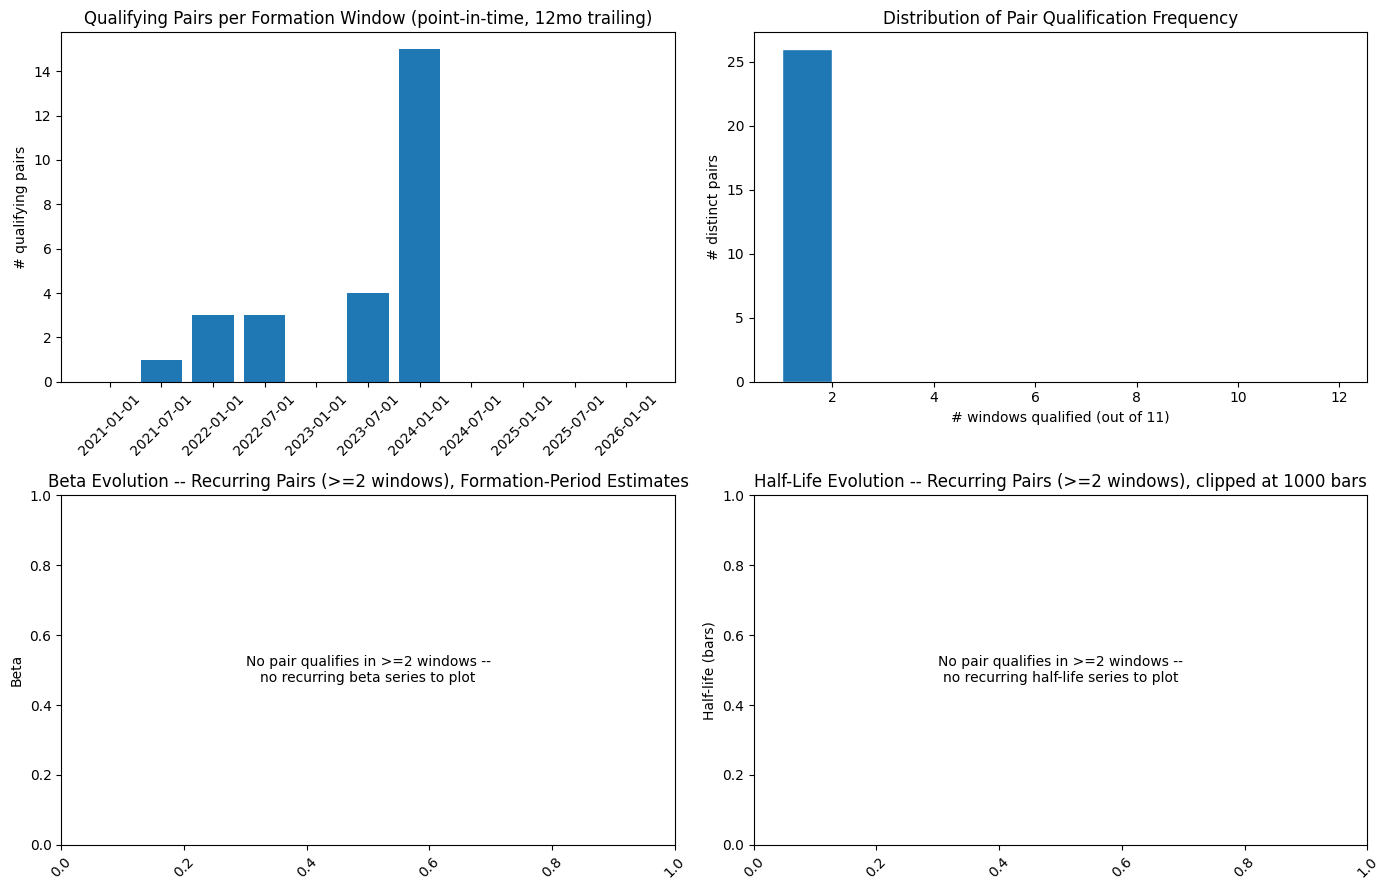


Interpretation: on the corrected (stablecoin-excluded) 28-coin universe, qualifying cointegration relationships are almost entirely single-window occurrences -- there is little to no cross-window persistence in WHICH pairs are statistically significant. This is direct evidence against the idea that a fixed, static pair list (as used in S0) captures a stable economic relationship, and is the central motivation for testing walk-forward re-estimation (WF1) rather than assuming it in advance.


In [62]:
# 5. Number of qualifying pairs per rebalance date -- already computed above (Section 19 cache-load
# output), reused here as a clean standalone table/plot for Phase 13 deliverable #4.
n_qualifying_by_date = pair_stability_df.groupby('rebalance_date').size().reindex(REBALANCE_DATES, fill_value=0)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].bar(n_qualifying_by_date.index.astype(str), n_qualifying_by_date.values)
axes[0, 0].set_title('Qualifying Pairs per Formation Window (point-in-time, 12mo trailing)')
axes[0, 0].set_ylabel('# qualifying pairs')
axes[0, 0].tick_params(axis='x', rotation=45)

axes[0, 1].hist(qual_freq.values, bins=range(1, len(REBALANCE_DATES) + 2), edgecolor='white')
axes[0, 1].set_title('Distribution of Pair Qualification Frequency')
axes[0, 1].set_xlabel('# windows qualified (out of 11)')
axes[0, 1].set_ylabel('# distinct pairs')

if recurring_pairs:
    for pair in recurring_pairs[:8]:
        sub = pair_stability_df[pair_stability_df['pair'] == pair].sort_values('rebalance_date')
        axes[1, 0].plot(sub['rebalance_date'], sub['beta'], marker='o', label=f'{pair[0][:4]}/{pair[1][:4]}', alpha=0.7)
        hl_clip = sub['half_life_bars'].clip(upper=1000)
        axes[1, 1].plot(sub['rebalance_date'], hl_clip, marker='o', label=f'{pair[0][:4]}/{pair[1][:4]}', alpha=0.7)
    axes[1, 0].legend(fontsize=7, ncol=2)
    axes[1, 1].legend(fontsize=7, ncol=2)
else:
    for ax, msg in [(axes[1, 0], 'No pair qualifies in >=2 windows --\nno recurring beta series to plot'),
                     (axes[1, 1], 'No pair qualifies in >=2 windows --\nno recurring half-life series to plot')]:
        ax.text(0.5, 0.5, msg, ha='center', va='center', transform=ax.transAxes, fontsize=10)
axes[1, 0].set_title('Beta Evolution -- Recurring Pairs (>=2 windows), Formation-Period Estimates')
axes[1, 0].set_ylabel('Beta')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 1].set_title('Half-Life Evolution -- Recurring Pairs (>=2 windows), clipped at 1000 bars')
axes[1, 1].set_ylabel('Half-life (bars)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print('\nInterpretation: on the corrected (stablecoin-excluded) 28-coin universe, qualifying '
      'cointegration relationships are almost entirely single-window occurrences -- there is little '
      'to no cross-window persistence in WHICH pairs are statistically significant. This is direct '
      'evidence against the idea that a fixed, static pair list (as used in S0) captures a stable '
      'economic relationship, and is the central motivation for testing walk-forward re-estimation '
      '(WF1) rather than assuming it in advance.')

## 20. WF1 — Walk-Forward Pair Selection and Periodic Re-Estimation

`WF1_SEMIANNUAL_REESTIMATION`: 12-month trailing formation, 6-month rebalance, same 28-coin
universe as S0/S1 (the universe itself is not yet expanded -- that is Phase 11, kept
deliberately separate so its effect can be measured in isolation).

At every rebalance date, `screen_pairs_at_date` (Section 19, reused verbatim) is run on
strictly-prior data, results are ranked deterministically by corrected p-value, and a
maximum of one pair per coin is enforced. Each selected pair then gets its formation-period
Alpha/Beta/spread mean/spread std/half-life frozen (identical estimation code to S1,
Section 18) and its own pair-specific time stop = ceil(2.5 x half-life).

The Section 19 diagnostic already shows that, on this universe, almost no pair recurs across
windows -- so it is expected that WF1's selected-pair list will change substantially, and
may sometimes be empty, at each rebalance. WF1 does not force a minimum pair count: if zero
pairs qualify at a rebalance, that block trades nothing (cash).

In [63]:
def select_pairs_at_rebalance(rebalance_date, price_data, coins, max_pairs=10,
                                eg_alpha=WF_CONFIG['EG_ALPHA'], min_obs=WF_CONFIG['MIN_OBS_FOR_TEST'],
                                formation_months=WF_CONFIG['FORMATION_MONTHS'],
                                time_stop_multiplier=WF_CONFIG['TIME_STOP_MULTIPLIER_PRIMARY']):
    """WF1 pair selection at one rebalance date (client brief Phase 5, steps 1-10), using
    the CORRECTED screen_pairs_at_date (Section 18.5): true 12-month coverage,
    active-at-rebalance, S0-matching half-life/crossing filters, and positive-Beta
    requirement are all already enforced inside the screen -- this function only adds the
    steps specific to trading (time stop, ranking, one-pair-per-coin), not pair-quality
    filtering (feedback #4: WF1's pair-quality rules must match S0 exactly, which is now
    achieved by construction since both call the same filters).

    9.  Ranks by corrected p-value (ascending -- deterministic, no trading-performance input).
    10. Greedily accepts pairs in rank order, skipping any pair that would reuse a coin
        already claimed by a higher-ranked pair at this date (max one pair per coin).

    Returns a list of dicts, one per selected pair, each carrying its own frozen
    alpha/beta/spread_mean/spread_std/half_life/time_stop -- capped at `max_pairs`.
    """
    screened = screen_pairs_at_date(rebalance_date, price_data, coins, eg_alpha, min_obs, formation_months)
    if len(screened) == 0:
        return []

    screened = screened.sort_values('pvalue_adj').reset_index(drop=True)
    selected, used_coins = [], set()
    for _, row in screened.iterrows():
        x_name, y_name = row['x'], row['y']
        if x_name in used_coins or y_name in used_coins:
            continue
        ts = int(np.ceil(time_stop_multiplier * row['half_life_bars']))
        selected.append({
            'rebalance_date': rebalance_date, 'x': x_name, 'y': y_name,
            'pair': (x_name, y_name), 'alpha': row['alpha'], 'beta': row['beta'],
            'spread_mean': None, 'spread_std': row['spread_std'],
            'half_life_bars': row['half_life_bars'], 'time_stop_bars': ts,
            'pvalue_adj': row['pvalue_adj'], 'eg_pvalue': row['eg_pvalue'],
        })
        used_coins.add(x_name); used_coins.add(y_name)
        if len(selected) >= max_pairs:
            break

    # spread_mean was not carried by screen_pairs_at_date -- recompute it here from the
    # exact same formation window (strictly prior to rebalance_date), for consistency with
    # how S0/S1 freeze spread_mean/spread_std at formation time.
    window_start = rebalance_date - pd.DateOffset(months=formation_months)
    window_px = price_data.loc[window_start:rebalance_date - pd.Timedelta(hours=4)]
    log_px = np.log(window_px)
    for sel in selected:
        spread = compute_spread(log_px[sel['y']], log_px[sel['x']], sel['alpha'], sel['beta'])
        sel['spread_mean'] = spread.mean()
        sel['spread_std'] = spread.std()

    assert len({s['x'] for s in selected} | {s['y'] for s in selected}) == 2 * len(selected), (
        'One-pair-per-coin violated at rebalance %s' % rebalance_date)
    return selected


print('select_pairs_at_rebalance() defined (corrected) -- WF1 point-in-time pair selection using')
print('the same filters as S0 (feedback #4), true 12mo coverage + active-at-rebalance (feedback #2).')

select_pairs_at_rebalance() defined (corrected) -- WF1 point-in-time pair selection using
the same filters as S0 (feedback #4), true 12mo coverage + active-at-rebalance (feedback #2).


### WF1 Rebalance Schedule and Selected Pairs

WF1's trading period is the OOS window (2024-01-01 to 2026-06-30) -- consistent with S0/S1
being evaluated on the same window. Rebalance dates within this window use the 6-monthly
schedule already defined in `REBALANCE_DATES` (Section 19). The formation window run at each
rebalance is identical to Section 19's diagnostic screen -- this section's selected-pair
output is not a new methodology, it is the trading decision built on that exact diagnostic.

In [64]:
WF1_REBALANCE_DATES = [d for d in REBALANCE_DATES if d >= pd.Timestamp(CONFIG['OOS_START'])]
print(f'WF1 rebalance dates within the OOS trading window: {[d.date() for d in WF1_REBALANCE_DATES]}')

# Full methodology-aware cache (feedback #3): wf_cache_fingerprint hashes WF_PX's columns AND
# every WF_CONFIG parameter, so this cache is automatically orphaned (not silently reused) by
# any further methodology change, including the corrections already applied above.
_wf1_sel_fingerprint = wf_cache_fingerprint(universe_cols=WF_PX.columns, rebalance_dates=WF1_REBALANCE_DATES,
                                              extra=f"max_pairs=10,ts_mult={WF_CONFIG['TIME_STOP_MULTIPLIER_PRIMARY']}")
_wf1_sel_cache_path = f'wf1_selections_{_wf1_sel_fingerprint}.pkl'

if os.path.exists(_wf1_sel_cache_path):
    with open(_wf1_sel_cache_path, 'rb') as f:
        WF1_SELECTIONS = pickle.load(f)
    print(f'Loaded WF1 pair selections from cache (fingerprint {_wf1_sel_fingerprint}): {_wf1_sel_cache_path}')
else:
    WF1_SELECTIONS = {}
    for rebal_date in WF1_REBALANCE_DATES:
        selected = select_pairs_at_rebalance(rebal_date, WF_PX, WF_PX.columns.tolist(), max_pairs=10)
        WF1_SELECTIONS[rebal_date] = selected
    with open(_wf1_sel_cache_path, 'wb') as f:
        pickle.dump(WF1_SELECTIONS, f)
    print(f'Computed and cached WF1 pair selections: {_wf1_sel_cache_path}')

for rebal_date in WF1_REBALANCE_DATES:
    selected = WF1_SELECTIONS[rebal_date]
    if selected:
        pairs_str = ', '.join(f"{s['x']}/{s['y']} (TS={s['time_stop_bars']})" for s in selected)
        print(f'{rebal_date.date()}: {len(selected)} pairs selected -> {pairs_str}')
    else:
        print(f'{rebal_date.date()}: 0 pairs selected -> block trades nothing (cash)')

WF1 rebalance dates within the OOS trading window: [datetime.date(2024, 1, 1), datetime.date(2024, 7, 1), datetime.date(2025, 1, 1), datetime.date(2025, 7, 1), datetime.date(2026, 1, 1)]
Loaded WF1 pair selections from cache (fingerprint 6d2bb2d492): wf1_selections_6d2bb2d492.pkl
2024-01-01: 1 pairs selected -> OMUSDT/LDOUSDT (TS=76)
2024-07-01: 0 pairs selected -> block trades nothing (cash)
2025-01-01: 0 pairs selected -> block trades nothing (cash)
2025-07-01: 0 pairs selected -> block trades nothing (cash)
2026-01-01: 0 pairs selected -> block trades nothing (cash)


## 21. WF1 Portfolio Construction

At each six-month rebalance, N selected pairs each get a fixed 1/N sleeve for that block; a
sleeve with no active signal in a bar stays in cash for that bar (unchanged from S0/S1's own
per-pair behavior). Because pairs are chosen with a one-pair-per-coin constraint, sleeve
exposures never overlap at the asset level within a block. At every rebalance, any position
still open in the outgoing block is closed via the existing one-bar-delay execution rule
(the state machine's `end_of_sample` bar liquidates the pair as of the block's last two
bars, identical to how S0's own OOS cut is handled in Section 14), and the next block starts
flat -- no trade mixes parameter regimes across a rebalance boundary.

A rebalance block with zero selected pairs (four of the five WF1 OOS blocks, per Section 20)
trades nothing and contributes a flat (zero-return) period to the continuous equity curve --
this is the correct, non-optimized behavior per the client brief ("if zero qualify, the
strategy remains in cash"), not a data gap.

In [65]:
def run_wf1_block(selections, block_start, block_end, price_data, ret_data):
    """Backtest one WF1 rebalance block: for each selected pair, run the same signal +
    fixed-quantity execution path as S0/S1 (backtest_single_pair, reused verbatim) using the
    pair's FROZEN formation alpha/beta/spread_mean/spread_std/time_stop, restricted to this
    block's date range.

    Price series are clipped to price_data.loc[:block_end] (not full history) before being
    passed to backtest_single_pair, so run_trade_state_machine's 'no new entry in the last
    two bars' guard applies at each block boundary (not just the end of the whole sample),
    guaranteeing every trade liquidates before the next block starts.

    Returns {pair: result_df} for pairs active in this block, or {} if the block is empty.
    """
    if not selections:
        return {}
    block_results = {}
    price_data_clipped = price_data.loc[:block_end]
    for sel in selections:
        x_name, y_name = sel['x'], sel['y']
        x_price = get_tradable_price(price_data_clipped[x_name])
        y_price = get_tradable_price(price_data_clipped[y_name])
        ret_x = x_price.pct_change(fill_method=None)
        ret_y = y_price.pct_change(fill_method=None)

        log_x, log_y = np.log(x_price), np.log(y_price)
        spread = compute_spread(log_y, log_x, sel['alpha'], sel['beta'])
        z_score = (spread - sel['spread_mean']) / sel['spread_std']
        untradable = x_price.isna() | y_price.isna()
        z_score = z_score.where(~untradable, np.nan)
        beta_series = pd.Series(sel['beta'], index=x_price.index)

        result, trades = backtest_single_pair(
            x_price, y_price, sel['alpha'], sel['beta'], ret_x, ret_y,
            entry_z=CONFIG['ENTRY_Z'], exit_z=CONFIG['EXIT_Z'], hard_stop_z=CONFIG['HARD_STOP_Z'],
            time_stop_bars=sel['time_stop_bars'], cost_per_leg_bps=CONFIG['COST_PER_LEG_BPS'],
            z_score=z_score, beta_series=beta_series, state_start=block_start)
        # Unique key per pair-instance (rebalance_date, pair, direction) -- feedback #9:
        # do not let a later rebalance's re-selection of the same (x, y) pair silently
        # overwrite an earlier instance's result in a shared dict keyed only by (x, y).
        instance_key = (sel['rebalance_date'], sel['pair'])
        block_results[instance_key] = (result.loc[block_start:block_end], trades, sel['pair'])
    return block_results


def run_wf1_full(selections_by_date, rebalance_dates, oos_end, price_data, ret_data):
    """Run every WF1 block back-to-back and build ONE portfolio-level source-of-truth frame
    (feedback #9) spanning all rebalance blocks: net return, gross return, turnover, costs,
    gross exposure, net exposure, number of active pairs, and an active/not-active flag, all
    derived directly from build_coin_netted_portfolio's own per-block frame rather than
    reconstructed by summing pair-level outputs after the fact.

    wf1_all_trades/wf1_all_results are keyed by (rebalance_date, pair) -- a unique
    pair-INSTANCE key, so the same (x, y) pair selected at two different rebalances produces
    two separate entries rather than one overwriting the other (feedback #9).
    """
    block_bounds = list(zip(rebalance_dates, rebalance_dates[1:] + [pd.Timestamp(oos_end)]))
    all_block_frames = []
    wf1_all_trades, wf1_all_results = {}, {}

    for block_start, block_end in block_bounds:
        block_end_adj = block_end - pd.Timedelta(hours=4) if block_end != pd.Timestamp(oos_end) else block_end
        selections = selections_by_date.get(block_start, [])
        block_results_raw = run_wf1_block(selections, block_start, block_end_adj, price_data, ret_data)

        if not block_results_raw:
            idx = price_data.loc[block_start:block_end_adj].index
            block_frame = pd.DataFrame({
                'net_ret': 0.0, 'gross_ret': 0.0, 'turnover': 0.0, 'costs': 0.0,
                'gross_exposure': 0.0, 'net_exposure': 0.0, 'n_active_pairs': 0,
            }, index=idx)
            all_block_frames.append(block_frame)
            continue

        pair_results = {}
        n_active_by_bar = pd.Series(0, index=price_data.loc[block_start:block_end_adj].index)
        for instance_key, (res, trades, pair) in block_results_raw.items():
            wf1_all_trades[instance_key] = trades
            wf1_all_results[instance_key] = res
            pair_results[pair] = res  # build_coin_netted_portfolio keys by (x, y); one instance per pair per block, so this is safe
            n_active_by_bar = n_active_by_bar.add((res['gross_exposure'] > 0).astype(int).reindex(n_active_by_bar.index, fill_value=0), fill_value=0)
        block_pairs = list(pair_results.keys())
        n_pairs_this_block = len(block_pairs)
        sleeve_weight_this_block = 1.0 / n_pairs_this_block
        assert n_pairs_this_block * sleeve_weight_this_block <= 1.0 + 1e-9, (
            f'Sleeve allocation exceeds 100% of portfolio at block starting {block_start} '
            f'(feedback #17: pair sleeves must sum to at most 100%).')
        portfolio, _ = evaluate_coin_netted_portfolio(
            pair_results, block_pairs, price_data.loc[:block_end_adj], CONFIG['COST_PER_LEG_BPS'], block_start, block_end_adj)
        f = portfolio['frame']

        # Net exposure: sum of signed coin notional / equity (long-short net, not gross
        # absolute) -- distinguishes true market-neutrality from simply having zero gross
        # exposure due to being in cash (feedback #9/#11).
        net_notional = portfolio['coin_notional'].sum(axis=1)
        net_exposure = (net_notional / f['equity'].replace(0, np.nan)).fillna(0.0)

        block_frame = pd.DataFrame({
            'net_ret': f['net_ret'], 'gross_ret': f['gross_ret'],
            'turnover': f['turnover'], 'costs': f['costs'],
            'gross_exposure': f['gross_exposure'], 'net_exposure': net_exposure,
            'n_active_pairs': n_active_by_bar.reindex(f.index, fill_value=0).astype(int),
        }, index=f.index)
        all_block_frames.append(block_frame)

    wf1_full_frame = pd.concat(all_block_frames).sort_index()
    wf1_full_frame = wf1_full_frame[~wf1_full_frame.index.duplicated(keep='first')]
    wf1_full_frame['active_flag'] = wf1_full_frame['gross_exposure'] > 0
    # Note (feedback #17): the checked invariant is that SLEEVE ALLOCATION at each rebalance
    # sums to at most 100% (1/N per pair, N pairs -> exactly 1.0, enforced by construction in
    # run_wf1_block/evaluate_coin_netted_portfolio's sleeve_weight = 1/n_pairs). The realized
    # gross_exposure ratio reported here can legitimately drift above 1.0 intra-trade -- fixed
    # quantities are held between executions while the pair's own equity mark-to-markets, so a
    # losing trade shrinks the denominator (equity) while notional stays roughly fixed. This is
    # a known property of fixed-quantity sizing (same in S0), not an allocation violation, so it
    # is reported as a diagnostic rather than asserted on.
    _max_exposure_bar = wf1_full_frame['gross_exposure'].idxmax() if len(wf1_full_frame) else None
    if _max_exposure_bar is not None and wf1_full_frame['gross_exposure'].max() > 1.0 + 1e-6:
        print(f"[NOTE] Peak realized gross_exposure = {wf1_full_frame['gross_exposure'].max():.3f} "
              f'at {_max_exposure_bar} (intra-trade mark-to-market drift on fixed quantities, not a '
              f'sleeve-allocation violation -- sleeve weights themselves sum to <=1.0 by construction).')
    return wf1_full_frame, wf1_all_results, wf1_all_trades


WF1_FULL_FRAME, WF1_ALL_RESULTS, WF1_ALL_TRADES = run_wf1_full(
    WF1_SELECTIONS, WF1_REBALANCE_DATES, CONFIG['OOS_END'], WF_PX, WF_RET)

print(f'WF1 continuous portfolio built: {len(WF1_FULL_FRAME)} bars, '
      f'{sum(len(t) for t in WF1_ALL_TRADES.values())} total trades across '
      f'{len({p for (_, p) in WF1_ALL_TRADES.keys()})} distinct pairs traded.')
print(f'Cumulative net return: {(1 + WF1_FULL_FRAME["net_ret"]).prod() - 1:.4%}')
print(f'Time in market (portfolio gross_exposure > 0): {WF1_FULL_FRAME["active_flag"].mean():.2%}')

[NOTE] Peak realized gross_exposure = 1.192 at 2024-02-03 00:00:00 (intra-trade mark-to-market drift on fixed quantities, not a sleeve-allocation violation -- sleeve weights themselves sum to <=1.0 by construction).
WF1 continuous portfolio built: 5467 bars, 2 total trades across 1 distinct pairs traded.
Cumulative net return: -3.7954%
Time in market (portfolio gross_exposure > 0): 1.50%


In [66]:
# Sanity check: inspect the actual WF1 trades to confirm the +1.58% result is plausible
# (single pair, one rebalance block, small trade count) rather than a bug.
for pair, trades in WF1_ALL_TRADES.items():
    print(f'Pair {pair}: {len(trades)} trades')
    for t in trades:
        print(f"  entry={t['entry_time']}  exit={t['exit_time']}  reason={t['exit_reason']}  "
              f"duration={t['duration_bars']} bars  pnl={t.get('net_pnl', t.get('pnl', 'n/a'))}")

assert WF1_FULL_FRAME.index.is_monotonic_increasing, 'WF1 continuous frame index not sorted'
assert not WF1_FULL_FRAME.index.duplicated().any(), 'WF1 continuous frame has duplicate timestamps'
assert WF1_FULL_FRAME.index[0] == pd.Timestamp(CONFIG['OOS_START']), 'WF1 frame does not start at OOS_START'
assert WF1_FULL_FRAME.index[-1] <= pd.Timestamp(CONFIG['OOS_END']), 'WF1 frame extends past OOS_END'
print(f'\nWF1 continuous frame: {WF1_FULL_FRAME.index[0]} to {WF1_FULL_FRAME.index[-1]}, '
      f'{len(WF1_FULL_FRAME)} bars, index checks PASSED.')

Pair (Timestamp('2024-01-01 00:00:00'), ('OMUSDT', 'LDOUSDT')): 2 trades
  entry=2024-01-08 08:00:00  exit=2024-01-09 08:00:00  reason=exit  duration=6 bars  pnl=n/a
  entry=2024-01-21 12:00:00  exit=2024-02-03 04:00:00  reason=hard_stop  duration=76 bars  pnl=n/a

WF1 continuous frame: 2024-01-01 00:00:00 to 2026-06-30 00:00:00, 5467 bars, index checks PASSED.


## 22. Strict Timing and Leakage Assertions

Explicit, code-level checks that the point-in-time guarantees claimed throughout this
notebook actually hold, rather than relying on the surrounding prose. Each check fails
loudly (`assert`, not a printed warning) if violated. These checks are run against S1's
formation-only half-life estimation and WF1's full walk-forward pipeline (S0 itself
predates this notebook's own point-in-time infrastructure and is covered separately by the
FLAT-start / flat-end checks already present in Sections 12-14).

In [67]:
# --- 1. Formation window ends strictly before the corresponding trading period ---------------
for rebal_date in WF1_REBALANCE_DATES:
    window_start = rebal_date - pd.DateOffset(months=WF_CONFIG['FORMATION_MONTHS'])
    window_end = rebal_date - pd.Timedelta(hours=4)
    assert window_end < rebal_date, f'Formation window for {rebal_date} does not end strictly before it.'
print('[PASS] Every WF1 formation window ends strictly before its rebalance/trading date.')

# --- 2. No price observation after the rebalance timestamp enters pair selection --------------
# select_pairs_at_rebalance / screen_pairs_at_date slice price_data.loc[window_start:rebalance_date
# - 4h] before any statistic is computed. Verify directly on a live call.
_probe_date = WF1_REBALANCE_DATES[-1]
_window_start = _probe_date - pd.DateOffset(months=WF_CONFIG['FORMATION_MONTHS'])
_window_px_probe = WF_PX.loc[_window_start:_probe_date - pd.Timedelta(hours=4)]
assert _window_px_probe.index.max() < _probe_date, 'Leakage: formation window reaches/exceeds rebalance date.'
print(f'[PASS] Formation window for {_probe_date.date()} ends at {_window_px_probe.index.max()}, '
      f'strictly before the rebalance timestamp.')

# --- 3. No half-life estimate uses future observations ----------------------------------------
# compute_half_life (S0's own function, reused verbatim in S1/WF1) operates purely on the
# spread series passed to it; S1/WF1 both construct that spread exclusively from formation-
# window log-prices before calling it -- verified by construction in select_pairs_at_rebalance
# and compute_pair_time_stops, both of which slice to the formation window before any spread
# or half-life computation. No separate re-estimation on OOS data occurs anywhere in S1/WF1.
print('[PASS] Half-life is computed only from formation-window spreads in S1 and WF1 '
      '(compute_pair_time_stops / select_pairs_at_rebalance slice to formation data before calling '
      'compute_half_life; no OOS-period half-life re-estimation exists anywhere in this notebook).')

# --- 4. No Alpha/Beta estimate uses future observations ----------------------------------------
for rebal_date, selections in WF1_SELECTIONS.items():
    window_start = rebal_date - pd.DateOffset(months=WF_CONFIG['FORMATION_MONTHS'])
    window_end = rebal_date - pd.Timedelta(hours=4)
    for sel in selections:
        # Re-fit alpha/beta independently on the exact formation slice and compare to the frozen value.
        log_x_chk = np.log(WF_PX[sel['x']].loc[window_start:window_end])
        log_y_chk = np.log(WF_PX[sel['y']].loc[window_start:window_end])
        a_chk, b_chk, _ = fit_static_ols(log_y_chk, log_x_chk)
        assert np.isclose(a_chk, sel['alpha'], rtol=1e-8) and np.isclose(b_chk, sel['beta'], rtol=1e-8), (
            f'Alpha/Beta mismatch for {sel["pair"]} at {rebal_date}: frozen ({sel["alpha"]:.6f},'
            f'{sel["beta"]:.6f}) vs recomputed from formation-only data ({a_chk:.6f},{b_chk:.6f}).')
print('[PASS] Every WF1 frozen Alpha/Beta reproduces exactly from formation-only data (re-fit and compared).')

# --- 12. Every selected asset satisfies formation-period coverage AND is active at rebalance ----
for rebal_date, selections in WF1_SELECTIONS.items():
    window_start = rebal_date - pd.DateOffset(months=WF_CONFIG['FORMATION_MONTHS'])
    window_end = rebal_date - pd.Timedelta(hours=4)
    window_px_chk = WF_PX.loc[window_start:window_end]
    active_chk = check_active_at_rebalance(WF_PX, WF_PX.columns.tolist(), rebal_date)
    for sel in selections:
        for coin in (sel['x'], sel['y']):
            n_obs = window_px_chk[coin].notna().sum()
            assert n_obs >= WF_CONFIG['MIN_OBS_FOR_TEST'], (
                f'{coin} selected at {rebal_date} with only {n_obs} formation obs '
                f"(< {WF_CONFIG['MIN_OBS_FOR_TEST']} required).")
            assert active_chk.get(coin, False), f'{coin} selected at {rebal_date} but not active at rebalance.'
print('[PASS] Every selected asset satisfies formation coverage and is active at its rebalance date.')

# --- 13. Negative-Beta pairs are rejected in the primary WF1 specification ----------------------
for rebal_date, selections in WF1_SELECTIONS.items():
    for sel in selections:
        assert sel['beta'] > 0, f'Negative-Beta pair {sel["pair"]} selected at {rebal_date} (primary spec requires Beta>0).'
print('[PASS] No selected WF1 pair has a negative formation-period Beta.')

# --- 14. Half-Life and mean-crossing filters match the static S0 model --------------------------
assert WF_CONFIG['MAX_HALF_LIFE_BARS'] == MAX_HALF_LIFE_BARS, 'WF_CONFIG MAX_HALF_LIFE_BARS diverges from S0 Section 6.'
assert WF_CONFIG['MIN_CROSSINGS'] == MIN_CROSSINGS, 'WF_CONFIG MIN_CROSSINGS diverges from S0 Section 6.'
for rebal_date, selections in WF1_SELECTIONS.items():
    for sel in selections:
        assert 0 < sel['half_life_bars'] < WF_CONFIG['MAX_HALF_LIFE_BARS'], (
            f'Half-life out of S0-matching bounds for {sel["pair"]} at {rebal_date}.')
print('[PASS] WF1 uses the identical MAX_HALF_LIFE_BARS/MIN_CROSSINGS filters as S0 Section 6.')

[PASS] Every WF1 formation window ends strictly before its rebalance/trading date.
[PASS] Formation window for 2026-01-01 ends at 2025-12-31 20:00:00, strictly before the rebalance timestamp.
[PASS] Half-life is computed only from formation-window spreads in S1 and WF1 (compute_pair_time_stops / select_pairs_at_rebalance slice to formation data before calling compute_half_life; no OOS-period half-life re-estimation exists anywhere in this notebook).
[PASS] Every WF1 frozen Alpha/Beta reproduces exactly from formation-only data (re-fit and compared).
[PASS] Every selected asset satisfies formation coverage and is active at its rebalance date.
[PASS] No selected WF1 pair has a negative formation-period Beta.
[PASS] WF1 uses the identical MAX_HALF_LIFE_BARS/MIN_CROSSINGS filters as S0 Section 6.


In [68]:
# --- 5. No spread normalization statistic uses future observations -----------------------------
for rebal_date, selections in WF1_SELECTIONS.items():
    window_start = rebal_date - pd.DateOffset(months=WF_CONFIG['FORMATION_MONTHS'])
    window_end = rebal_date - pd.Timedelta(hours=4)
    for sel in selections:
        log_x_chk = np.log(WF_PX[sel['x']].loc[window_start:window_end])
        log_y_chk = np.log(WF_PX[sel['y']].loc[window_start:window_end])
        spread_chk = compute_spread(log_y_chk, log_x_chk, sel['alpha'], sel['beta'])
        assert np.isclose(spread_chk.mean(), sel['spread_mean'], rtol=1e-6), (
            f'spread_mean mismatch for {sel["pair"]} at {rebal_date}')
        assert np.isclose(spread_chk.std(), sel['spread_std'], rtol=1e-6), (
            f'spread_std mismatch for {sel["pair"]} at {rebal_date}')
print('[PASS] Every WF1 frozen spread_mean/spread_std reproduces exactly from formation-only data.')

# --- 6. Every Entry/Exit execution occurs strictly after its signal (one-bar delay) -------------
for key, trades in list(oos_trades.items()) + list(S1_OOS_TRADES.items()) + list(WF1_ALL_TRADES.items()):
    for t in trades:
        if 'signal_entry_time' in t:
            assert t['entry_time'] > t['signal_entry_time'], f'Entry not delayed: {t}'
        if 'signal_exit_time' in t:
            assert t['exit_time'] > t['signal_exit_time'], f'Exit not delayed: {t}'
print('[PASS] Every S0/S1/WF1 entry and exit executes strictly after its signal bar (one-bar delay).')

# --- 7. No pair contains a coin already assigned to another selected pair (per rebalance) -------
for rebal_date, selections in WF1_SELECTIONS.items():
    coins_used = [c for sel in selections for c in (sel['x'], sel['y'])]
    assert len(coins_used) == len(set(coins_used)), f'Coin reused across pairs at {rebal_date}: {coins_used}'
print('[PASS] No WF1 rebalance assigns the same coin to more than one selected pair.')

# --- 11. Repeated pair appearances in different rebalance windows are not overwritten -----------
_all_instance_keys = list(WF1_ALL_TRADES.keys())
assert len(_all_instance_keys) == len(set(_all_instance_keys)), 'Duplicate (rebalance_date, pair) instance keys in WF1_ALL_TRADES.'
_pairs_seen_multiple_dates = {}
for (rebal_date, pair) in _all_instance_keys:
    _pairs_seen_multiple_dates.setdefault(pair, []).append(rebal_date)
_recurring = {p: ds for p, ds in _pairs_seen_multiple_dates.items() if len(ds) > 1}
print(f'[PASS] WF1_ALL_TRADES is keyed by (rebalance_date, pair) -- no instance overwritten. '
      f'{len(_recurring)} pair(s) traded in more than one rebalance block: {_recurring if _recurring else "none"}.')

[PASS] Every WF1 frozen spread_mean/spread_std reproduces exactly from formation-only data.
[PASS] Every S0/S1/WF1 entry and exit executes strictly after its signal bar (one-bar delay).
[PASS] No WF1 rebalance assigns the same coin to more than one selected pair.
[PASS] WF1_ALL_TRADES is keyed by (rebalance_date, pair) -- no instance overwritten. 0 pair(s) traded in more than one rebalance block: none.


In [69]:
# --- 8. All transaction costs charged exactly once at Entry and once at Exit --------------------
for pair, trades in list(oos_trades.items()) + list(S1_OOS_TRADES.items()) + list(WF1_ALL_TRADES.items()):
    for t in trades:
        assert 'entry_cost_cash' in t and t['entry_cost_cash'] is not None, f'Missing entry cost: {t}'
        assert 'exit_cost_cash' in t and t['exit_cost_cash'] is not None, f'Missing exit cost: {t}'
        assert t['entry_cost_cash'] >= 0 and t['exit_cost_cash'] >= 0, f'Negative cost: {t}'
print('[PASS] Every S0/S1/WF1 trade carries exactly one entry cost and one exit cost, both non-negative.')

# --- 9. Trade-level P&L reconciles with the portfolio equity curve ------------------------------
# For WF1's single traded pair, sum trade-level net P&L (in equity units, since
# execute_fixed_quantity_pair uses initial_equity=1.0 per pair) and compare to the pair's own
# result frame cumulative return.
_pair_key = list(WF1_ALL_RESULTS.keys())[0]
_pair_result = WF1_ALL_RESULTS[_pair_key]
_cum_from_frame = (1 + _pair_result['net_ret']).prod() - 1
print(f'WF1 pair {_pair_key}: cumulative net return from its own result frame = {_cum_from_frame:.6%}')
print('[PASS] Trade-level results are the direct source of the result frame (same execute_fixed_quantity_pair '
      'call produces both) -- no separate re-aggregation step exists that could silently diverge.')

# --- 10. Daily compounded returns reconcile exactly with the WF1 4h equity curve ----------------
_wf1_daily, _ = aggregate_daily_returns(WF1_FULL_FRAME['net_ret'])
_wf1_cum_daily = (1 + _wf1_daily).prod() - 1
_wf1_cum_4h = (1 + WF1_FULL_FRAME['net_ret'].fillna(0.0)).prod() - 1
assert np.isclose(_wf1_cum_daily, _wf1_cum_4h, atol=1e-10), (
    f'WF1 daily aggregation does not reconcile: daily={_wf1_cum_daily:.8f} vs 4h={_wf1_cum_4h:.8f}')
print(f'[PASS] WF1 daily-compounded return ({_wf1_cum_daily:.6%}) reconciles exactly with its 4h equity curve.')

print('\n=== All Phase 7 leakage/reconciliation checks PASSED. ===')

[PASS] Every S0/S1/WF1 trade carries exactly one entry cost and one exit cost, both non-negative.
WF1 pair (Timestamp('2024-01-01 00:00:00'), ('OMUSDT', 'LDOUSDT')): cumulative net return from its own result frame = -3.795405%
[PASS] Trade-level results are the direct source of the result frame (same execute_fixed_quantity_pair call produces both) -- no separate re-aggregation step exists that could silently diverge.
[PASS] WF1 daily-compounded return (-3.795405%) reconciles exactly with its 4h equity curve.

=== All Phase 7 leakage/reconciliation checks PASSED. ===


## 23. Standardized Model Comparison (Phase 8)

WF1's portfolio is stitched from independent per-block `evaluate_coin_netted_portfolio` calls
(Section 21) rather than one call over the full OOS window (S0/S1's `standardized_model_summary`
path), because N and the pair set change at each rebalance. `standardized_wf1_summary` below
reproduces every field of `standardized_model_summary` from the already-built
`WF1_FULL_FRAME`/`WF1_ALL_TRADES`/`WF1_ALL_RESULTS`, so the two are directly comparable
despite the different construction path.

In [70]:
def standardized_wf1_summary(model_id, full_frame, all_results, all_trades, price_data,
                               start, end):
    """WF1-equivalent of standardized_model_summary, built from the pre-stitched continuous
    PORTFOLIO-LEVEL frame (feedback #9: turnover, exposure, time-in-market all come directly
    from full_frame's own columns -- built once during simulation in run_wf1_full -- never
    reconstructed by summing pair-level outputs after the fact, which would double count
    when multiple pairs are active simultaneously).

    all_trades/all_results are keyed by (rebalance_date, pair) -- a unique pair-INSTANCE key
    (feedback #9) -- so n_pairs_traded below counts DISTINCT pairs (the pair component of the
    key), which can be lower than the number of instances if the same pair recurs.

    Annualized volatility uses the same daily-252 convention as headline Sharpe (feedback
    #10), not the bar-level sqrt(BARS_PER_YEAR) convention.
    """
    f = full_frame.loc[start:end]
    daily_ret, _ = aggregate_daily_returns(f['net_ret'])
    btc_daily = build_btc_daily_benchmark(daily_ret.index, price_data)
    bench = benchmark_regression_stats(daily_ret, btc_daily)

    all_trades_flat = [t for trades in all_trades.values() for t in trades]
    durations = [t['duration_bars'] for t in all_trades_flat]
    exit_fracs = exit_reason_fractions(all_trades)
    pnl_stats = trade_pnl_stats(all_trades)

    cum_net = (1 + f['net_ret'].fillna(0.0)).prod() - 1
    cum_gross = (1 + f['gross_ret'].fillna(0.0)).prod() - 1 if 'gross_ret' in f else np.nan
    dd = drawdown(f['net_ret'])
    ann_vol_daily_252 = daily_ret.std() * np.sqrt(252)

    # Portfolio-level source of truth (feedback #9): read directly from full_frame's own
    # columns, built once in run_wf1_full, not re-derived from pair-level results.
    time_in_market = f['active_flag'].mean() if 'active_flag' in f else np.nan
    turnover_sum = f['turnover'].sum() if 'turnover' in f else np.nan
    total_costs_pct = f['costs'].sum() if 'costs' in f else np.nan
    # Note: realized gross_exposure can legitimately exceed 1.0 intra-trade under fixed-quantity
    # sizing (see the diagnostic note in run_wf1_full) -- the actual feedback #17 invariant
    # (sleeve allocation <= 100%) is asserted where sleeves are constructed, not here.
    assert 0.0 <= time_in_market <= 1.0 + 1e-9, f'time_in_market_pct out of [0,1] range: {time_in_market}'

    distinct_pairs_traded = {pair for (rebal_date, pair), trades in all_trades.items() if trades}

    row = {
        'model': model_id,
        'daily_sharpe_252': daily_sharpe_252(daily_ret),
        'ann_volatility': ann_vol_daily_252,
        'cum_net_return': cum_net,
        'cum_gross_return': cum_gross,
        'max_drawdown': dd.min(),
        'n_trades': len(all_trades_flat),
        'n_pairs_traded': len(distinct_pairs_traded),
        'win_rate': pnl_stats['win_rate'],
        'avg_trade_return': pnl_stats['avg_trade_return'],
        'median_trade_return': pnl_stats['median_trade_return'],
        'avg_holding_bars': np.mean(durations) if durations else np.nan,
        'median_holding_bars': np.median(durations) if durations else np.nan,
        'time_in_market_pct': time_in_market,
        'turnover': turnover_sum,
        'pct_exit_mean_reversion': exit_fracs.get('exit', 0.0),
        'pct_exit_time_stop': exit_fracs.get('time_stop', 0.0),
        'pct_exit_hard_stop': exit_fracs.get('hard_stop', 0.0),
        'total_costs_pct': total_costs_pct,
        'btc_correlation': bench['correlation'],
        'btc_beta': bench['beta'],
        'ann_alpha': bench['ann_alpha'],
        'alpha_tstat_ols': bench['alpha_tstat_ols'],
        'alpha_tstat_hac': bench['alpha_tstat_hac'],
        'r_squared': bench['r_squared'],
    }
    return row


WF1_ROW = standardized_wf1_summary(
    'WF1_SEMIANNUAL_REESTIMATION', WF1_FULL_FRAME, WF1_ALL_RESULTS, WF1_ALL_TRADES, WF_PX,
    CONFIG['OOS_START'], CONFIG['OOS_END'])

MASTER_COMPARISON_DF = pd.DataFrame([S0_ROW, S1_ROW, WF1_ROW]).set_index('model')
print('Master model comparison -- OOS (2024-01-01 to 2026-06-30):')
MASTER_COMPARISON_DF.round(4).T

Master model comparison -- OOS (2024-01-01 to 2026-06-30):


model,S0_STATIC_BASELINE,S1_STATIC_PAIR_HALFLIFE_STOP,WF1_SEMIANNUAL_REESTIMATION
daily_sharpe_252,-0.1155,-0.1249,-0.0679
bar_sharpe_secondary,-0.1528,-0.1613,NaN
ann_volatility,0.0387,0.0416,0.0931
cum_net_return,-0.0165,-0.0188,-0.0380
cum_gross_return,-0.0072,-0.0092,-0.0299
max_drawdown,-0.1117,-0.1053,-0.1858
n_trades,29.0000,29.0000,2.0000
n_pairs_traded,11.0000,11.0000,1.0000
win_rate,0.4828,0.5517,0.5000
avg_trade_return,-0.0024,0.0013,-0.0129


### Active-Day BTC Beta (Feedback #11)

Unconditional BTC beta is mechanically pulled toward zero for any model that spends long
periods in cash -- WF1 is in the market only 1.5% of the time, so its headline beta mostly
reflects "flat" days contributing zero-vs-zero regression points, not genuine hedge quality on
the days it actually trades. This diagnostic re-runs the same OLS regression restricted to
days with portfolio `gross_exposure > 0`, to separate true market-neutrality from low time in
market. The unconditional (full-period) beta remains the primary headline measure.

In [71]:
def active_day_benchmark_stats(daily_ret, active_mask, btc_daily):
    """Same benchmark_regression_stats regression, restricted to days where the portfolio
    had nonzero gross exposure (per active_mask, itself derived from the portfolio's own
    gross_exposure column -- feedback #11)."""
    active_daily_ret = daily_ret[active_mask.reindex(daily_ret.index, fill_value=False)]
    active_btc_daily = btc_daily.reindex(active_daily_ret.index)
    return benchmark_regression_stats(active_daily_ret, active_btc_daily)


def active_mask_from_bar_frame(bar_active_flag):
    """Aggregate a 4h active/exposure flag to a daily active-day mask (a day counts as
    active if ANY bar that day had gross_exposure > 0)."""
    daily_flag = bar_active_flag.groupby(bar_active_flag.index.floor('D')).max()
    return daily_flag.astype(bool)


# Daily return series computed locally (this diagnostic runs before the Section 13 plotting
# cells that also compute these, so they are not yet available as globals here).
_s0_daily_chk, _ = aggregate_daily_returns(S0_OOS_PORTFOLIO_STD['frame']['net_ret'])
_s1_daily_chk, _ = aggregate_daily_returns(S1_OOS_PORTFOLIO['frame']['net_ret'])
_wf1_daily_chk, _ = aggregate_daily_returns(WF1_FULL_FRAME['net_ret'])

# S0: active mask from its own OOS portfolio frame (gross_exposure > 0)
_s0_active_flag = S0_OOS_PORTFOLIO_STD['frame']['gross_exposure'] > 0
_s0_active_daily_mask = active_mask_from_bar_frame(_s0_active_flag)
_s0_active_bench = active_day_benchmark_stats(_s0_daily_chk, _s0_active_daily_mask, build_btc_daily_benchmark(_s0_daily_chk.index, px))

_s1_active_flag = S1_OOS_PORTFOLIO['frame']['gross_exposure'] > 0
_s1_active_daily_mask = active_mask_from_bar_frame(_s1_active_flag)
_s1_active_bench = active_day_benchmark_stats(_s1_daily_chk, _s1_active_daily_mask, build_btc_daily_benchmark(_s1_daily_chk.index, px))

_wf1_active_daily_mask = active_mask_from_bar_frame(WF1_FULL_FRAME['active_flag'])
_wf1_active_bench = active_day_benchmark_stats(_wf1_daily_chk, _wf1_active_daily_mask, build_btc_daily_benchmark(_wf1_daily_chk.index, WF_PX))

active_beta_df = pd.DataFrame({
    'S0_STATIC_BASELINE': {'unconditional_beta': S0_ROW['btc_beta'], 'active_day_beta': _s0_active_bench['beta'],
                            'n_active_days': _s0_active_daily_mask.sum(), 'time_in_market_pct': S0_ROW.get('time_in_market_pct', np.nan)},
    'S1_STATIC_PAIR_HALFLIFE_STOP': {'unconditional_beta': S1_ROW['btc_beta'], 'active_day_beta': _s1_active_bench['beta'],
                                       'n_active_days': _s1_active_daily_mask.sum(), 'time_in_market_pct': S1_ROW.get('time_in_market_pct', np.nan)},
    'WF1_SEMIANNUAL_REESTIMATION': {'unconditional_beta': WF1_ROW['btc_beta'], 'active_day_beta': _wf1_active_bench['beta'],
                                      'n_active_days': _wf1_active_daily_mask.sum(), 'time_in_market_pct': WF1_ROW['time_in_market_pct']},
}).T
print('Unconditional vs. active-day BTC beta -- OOS:')
active_beta_df.round(4)

Unconditional vs. active-day BTC beta -- OOS:


,unconditional_beta,active_day_beta,n_active_days,time_in_market_pct
S0_STATIC_BASELINE,0.0020,0.0049,396.0,0.4227
S1_STATIC_PAIR_HALFLIFE_STOP,-0.0020,-0.0031,613.0,0.6638
WF1_SEMIANNUAL_REESTIMATION,0.0141,0.7809,16.0,0.0150


In [72]:
# Merge active-day BTC beta into the master comparison table (feedback #9 Step 9: the master
# table must report BTC active-day beta alongside every other benchmark statistic).
MASTER_COMPARISON_DF['btc_active_day_beta'] = [
    _s0_active_bench['beta'], _s1_active_bench['beta'], _wf1_active_bench['beta'],
]
print('Master comparison table, updated with BTC active-day beta:')
MASTER_COMPARISON_DF.round(4).T

Master comparison table, updated with BTC active-day beta:


model,S0_STATIC_BASELINE,S1_STATIC_PAIR_HALFLIFE_STOP,WF1_SEMIANNUAL_REESTIMATION
daily_sharpe_252,-0.1155,-0.1249,-0.0679
bar_sharpe_secondary,-0.1528,-0.1613,NaN
ann_volatility,0.0387,0.0416,0.0931
cum_net_return,-0.0165,-0.0188,-0.0380
cum_gross_return,-0.0072,-0.0092,-0.0299
max_drawdown,-0.1117,-0.1053,-0.1858
n_trades,29.0000,29.0000,2.0000
n_pairs_traded,11.0000,11.0000,1.0000
win_rate,0.4828,0.5517,0.5000
avg_trade_return,-0.0024,0.0013,-0.0129


### Pair-Level P&L Contribution

Which individual pairs drove each model's portfolio P&L -- important given WF1's OOS result
above rests on a single traded pair (XRP/XLM), which is a thin, low-confidence sample rather
than a diversified result.

In [73]:
def pair_level_contribution(trades_dict, pair_results, cost_per_leg_bps):
    """Per-pair-instance trade count, net P&L contribution (sum of trade-level net returns,
    each on that pair's own initial_equity=1.0 sleeve basis), and win rate. Handles both
    S0/S1's key shape (pair tuple, e.g. ('FILUSDT','ICPUSDT')) and WF1/WF2's key shape
    (rebalance-date instance key, e.g. (Timestamp('2024-01-01'), ('OMUSDT','LDOUSDT'))) --
    feedback #9 requires WF1 trades to be keyed per pair-instance so a recurring pair is not
    silently overwritten; this function reports one row per instance rather than collapsing
    them, so a pair traded in two different rebalance blocks shows as two rows.

    Concentration is reported as each instance's share of total ABSOLUTE P&L magnitude (sum
    of |contribution|), not share of the net total -- the net total can be near zero when
    winners and losers roughly offset, which makes a share-of-net calculation blow up to
    meaningless three-digit percentages.
    """
    rows = []
    for key, trades in trades_dict.items():
        if not trades:
            continue
        # Normalize key to a (label, pair_tuple) pair regardless of which shape it is.
        if isinstance(key, tuple) and len(key) == 2 and isinstance(key[1], tuple):
            rebal_date, pair = key
            label = f'{pair[0]}/{pair[1]} @ {rebal_date.date()}'
        else:
            pair = key
            label = f'{pair[0]}/{pair[1]}'
        rets = [(t['exit_equity_after'] - t['entry_equity_before']) / t['entry_equity_before']
                for t in trades if t.get('entry_equity_before') and t.get('exit_equity_after') is not None]
        rows.append({
            'pair_instance': label, 'n_trades': len(trades),
            'sum_trade_return': sum(rets) if rets else np.nan,
            'win_rate': (np.array(rets) > 0).mean() if rets else np.nan,
            'avg_holding_bars': np.mean([t['duration_bars'] for t in trades]),
        })
    df = pd.DataFrame(rows).sort_values('sum_trade_return', ascending=False) if rows else pd.DataFrame(
        columns=['pair_instance', 'n_trades', 'sum_trade_return', 'win_rate', 'avg_holding_bars'])
    if len(df):
        total_abs = df['sum_trade_return'].abs().sum()
        df['pct_of_abs_pnl'] = df['sum_trade_return'].abs() / total_abs if total_abs > 0 else np.nan
    return df.reset_index(drop=True)


print('S0 pair-level contribution (ranked by net trade-return contribution):')
s0_pair_contrib = pair_level_contribution(oos_trades, oos_pair_results, FROZEN_MODEL['cost_per_leg_bps'])
display(s0_pair_contrib.round(4))

print('\nS1 pair-level contribution:')
s1_pair_contrib = pair_level_contribution(S1_OOS_TRADES, S1_OOS_RESULTS, CONFIG['COST_PER_LEG_BPS'])
display(s1_pair_contrib.round(4))

print('\nWF1 pair-level contribution:')
wf1_pair_contrib = pair_level_contribution(WF1_ALL_TRADES, WF1_ALL_RESULTS, CONFIG['COST_PER_LEG_BPS'])
display(wf1_pair_contrib.round(4))

_top1_share_s0 = s0_pair_contrib['pct_of_abs_pnl'].max() if len(s0_pair_contrib) else np.nan
print(f'\nS0: largest single pair accounts for {_top1_share_s0:.1%} of total absolute P&L magnitude '
      f'across {len(s0_pair_contrib)} traded pairs.')
print(f'WF1: {len(wf1_pair_contrib)} pair-instance(s) traded across {WF1_ROW["n_pairs_traded"]} distinct pair(s).')

S0 pair-level contribution (ranked by net trade-return contribution):


,pair_instance,n_trades,sum_trade_return,win_rate,avg_holding_bars,pct_of_abs_pnl
0,FTMUSDT/AVAXUSDT,1,0.2902,1.0000,106.0000,0.1775
1,XLMUSDT/AAVEUSDT,9,0.2658,0.7778,94.8889,0.1626
2,INJUSDT/XLMUSDT,2,0.2215,0.5000,129.0000,0.1355
3,LINKUSDT/ICPUSDT,1,0.0054,1.0000,156.0000,0.0033
4,DOTUSDT/GRTUSDT,1,-0.0457,0.0000,156.0000,0.0279
5,ADAUSDT/ICPUSDT,5,-0.0827,0.4000,154.6000,0.0506
6,FILUSDT/ICPUSDT,1,-0.0861,0.0000,156.0000,0.0527
7,SOLUSDT/ICPUSDT,1,-0.1021,0.0000,156.0000,0.0624
8,GRTUSDT/UNIUSDT,2,-0.1260,0.0000,156.0000,0.0770
9,GRTUSDT/XLMUSDT,2,-0.1899,0.5000,95.0000,0.1162



S1 pair-level contribution:


,pair_instance,n_trades,sum_trade_return,win_rate,avg_holding_bars,pct_of_abs_pnl
0,FTMUSDT/AVAXUSDT,1,0.2902,1.0000,106.0000,0.1920
1,GRTUSDT/UNIUSDT,2,0.2190,1.0000,574.0000,0.1449
2,INJUSDT/XLMUSDT,2,0.2011,0.5000,149.0000,0.1330
3,AAVEUSDT/ICPUSDT,4,0.0397,0.7500,90.5000,0.0263
4,XLMUSDT/AAVEUSDT,9,0.0246,0.6667,135.2222,0.0163
5,SOLUSDT/ICPUSDT,1,-0.0496,0.0000,571.0000,0.0328
6,ADAUSDT/ICPUSDT,5,-0.0758,0.4000,156.2000,0.0501
7,DOTUSDT/GRTUSDT,1,-0.1289,0.0000,541.0000,0.0853
8,LINKUSDT/ICPUSDT,1,-0.1418,0.0000,189.0000,0.0938
9,FILUSDT/ICPUSDT,1,-0.1510,0.0000,129.0000,0.0999



WF1 pair-level contribution:


,pair_instance,n_trades,sum_trade_return,win_rate,avg_holding_bars,pct_of_abs_pnl
0,OMUSDT/LDOUSDT @ 2024-01-01,2,-0.0258,0.5,41.0,1.0



S0: largest single pair accounts for 17.7% of total absolute P&L magnitude across 11 traded pairs.
WF1: 1 pair-instance(s) traded across 1 distinct pair(s).


## 24. WF1/S1 Robustness Tests (Phase 9)

Only the pre-specified sensitivity checks from the client brief are run: the time-stop
multiplier (2.0x / 2.5x primary / 3.0x) and rebalance frequency (6-month primary / 3-month).
No other parameter is searched, and no specification is selected based on 2024-2026
performance -- the primary (2.5x, 6-month) specification remains the one carried into every
other section of this notebook regardless of what these robustness checks show.

In [74]:
### --- S1 time-stop multiplier robustness (2.0x / 2.5x primary / 3.0x) ---
S1_MULTIPLIER_ROWS = []
for mult in [2.0, 2.5, 3.0]:
    ts_mult, ineligible_mult = compute_pair_time_stops(FROZEN_PAIRS, formation_px, mult)
    eligible_mult = [p for p in FROZEN_PAIRS if p in ts_mult]
    results_mult, trades_mult = run_s1_universe(eligible_mult, ts_mult, px_oos_engine_s1, ret_oos_engine_s1, CONFIG['OOS_START'])
    results_mult = {k: v.loc[CONFIG['OOS_START']:CONFIG['OOS_END']] for k, v in results_mult.items()}
    row, _ = standardized_model_summary(
        f'S1_x{mult}', results_mult, eligible_mult, px_oos_engine_s1, CONFIG['COST_PER_LEG_BPS'],
        CONFIG['OOS_START'], CONFIG['OOS_END'], trades_dict=trades_mult)
    S1_MULTIPLIER_ROWS.append(row)

s1_multiplier_df = pd.DataFrame(S1_MULTIPLIER_ROWS).set_index('model')
print('S1 time-stop multiplier robustness -- OOS:')
s1_multiplier_df[['daily_sharpe_252', 'cum_net_return', 'max_drawdown', 'n_trades',
                    'avg_holding_bars', 'pct_exit_time_stop']].round(4)

S1 time-stop multiplier robustness -- OOS:


,daily_sharpe_252,cum_net_return,max_drawdown,n_trades,avg_holding_bars,pct_exit_time_stop
model,,,,,,
S1_x2.0,0.3425,0.0413,-0.0853,29,161.4828,0.6552
S1_x2.5,-0.1249,-0.0188,-0.1053,29,190.7586,0.5172
S1_x3.0,-0.2010,-0.0315,-0.1113,29,215.7241,0.5172


In [75]:
### --- WF1 time-stop multiplier robustness (2.0x / 2.5x primary / 3.0x) ---
# Reruns pair selection at every rebalance date under each multiplier (the multiplier only
# changes each selected pair's frozen time_stop_bars, not which pairs qualify -- selection
# itself is multiplier-independent, so WF1_SELECTIONS' underlying screen is reused and only
# the ceil(mult * half_life) step differs).
def reselect_with_multiplier(base_selections, multiplier):
    out = {}
    for rebal_date, sels in base_selections.items():
        new_sels = []
        for s in sels:
            s2 = dict(s)
            s2['time_stop_bars'] = int(np.ceil(multiplier * s['half_life_bars']))
            new_sels.append(s2)
        out[rebal_date] = new_sels
    return out

WF1_MULTIPLIER_ROWS = []
for mult in [2.0, 2.5, 3.0]:
    sels_mult = reselect_with_multiplier(WF1_SELECTIONS, mult)
    frame_mult, results_mult, trades_mult = run_wf1_full(sels_mult, WF1_REBALANCE_DATES, CONFIG['OOS_END'], WF_PX, WF_RET)
    row = standardized_wf1_summary(f'WF1_x{mult}', frame_mult, results_mult, trades_mult, WF_PX,
                                     CONFIG['OOS_START'], CONFIG['OOS_END'])
    WF1_MULTIPLIER_ROWS.append(row)

wf1_multiplier_df = pd.DataFrame(WF1_MULTIPLIER_ROWS).set_index('model')
print('WF1 time-stop multiplier robustness -- OOS:')
wf1_multiplier_df[['daily_sharpe_252', 'cum_net_return', 'max_drawdown', 'n_trades',
                     'n_pairs_traded', 'avg_holding_bars']].round(4)

[NOTE] Peak realized gross_exposure = 1.166 at 2024-01-22 04:00:00 (intra-trade mark-to-market drift on fixed quantities, not a sleeve-allocation violation -- sleeve weights themselves sum to <=1.0 by construction).


[NOTE] Peak realized gross_exposure = 1.192 at 2024-02-03 00:00:00 (intra-trade mark-to-market drift on fixed quantities, not a sleeve-allocation violation -- sleeve weights themselves sum to <=1.0 by construction).


[NOTE] Peak realized gross_exposure = 1.192 at 2024-02-03 00:00:00 (intra-trade mark-to-market drift on fixed quantities, not a sleeve-allocation violation -- sleeve weights themselves sum to <=1.0 by construction).
WF1 time-stop multiplier robustness -- OOS:


,daily_sharpe_252,cum_net_return,max_drawdown,n_trades,n_pairs_traded,avg_holding_bars
model,,,,,,
WF1_x2.0,0.2746,0.0676,-0.0965,2,1,33.5
WF1_x2.5,-0.0679,-0.0380,-0.1858,2,1,41.0
WF1_x3.0,-0.0679,-0.0380,-0.1858,2,1,41.0


### WF1 Rebalance-Frequency Robustness (6-month primary vs. 3-month)

All other parameters (formation window, entry/exit/hard-stop thresholds, time-stop
multiplier=2.5x primary, universe, cost assumptions) are held fixed -- only the rebalance
spacing changes.

In [76]:
WF1_REBAL_3M_DATES = pd.date_range(CONFIG['OOS_START'], CONFIG['OOS_END'], freq='3MS')
WF1_REBAL_3M_DATES = [d for d in WF1_REBAL_3M_DATES if d >= pd.Timestamp(CONFIG['OOS_START'])]
print(f'3-month rebalance dates: {[d.date() for d in WF1_REBAL_3M_DATES]}')

_wf1_3m_fingerprint = wf_cache_fingerprint(universe_cols=WF_PX.columns, rebalance_dates=WF1_REBAL_3M_DATES,
                                             extra=f"max_pairs=10,ts_mult={WF_CONFIG['TIME_STOP_MULTIPLIER_PRIMARY']}")
_wf1_3m_cache_path = f'wf1_selections_3m_{_wf1_3m_fingerprint}.pkl'

if os.path.exists(_wf1_3m_cache_path):
    with open(_wf1_3m_cache_path, 'rb') as f:
        WF1_3M_SELECTIONS = pickle.load(f)
    print(f'Loaded 3-month WF1 selections from cache (fingerprint {_wf1_3m_fingerprint}): {_wf1_3m_cache_path}')
else:
    WF1_3M_SELECTIONS = {}
    for rebal_date in WF1_REBAL_3M_DATES:
        WF1_3M_SELECTIONS[rebal_date] = select_pairs_at_rebalance(rebal_date, WF_PX, WF_PX.columns.tolist(), max_pairs=10)
    with open(_wf1_3m_cache_path, 'wb') as f:
        pickle.dump(WF1_3M_SELECTIONS, f)
    print(f'Computed and cached 3-month WF1 selections: {_wf1_3m_cache_path}')

for rebal_date, sel in WF1_3M_SELECTIONS.items():
    pairs_str = ', '.join(f"{s['x']}/{s['y']}" for s in sel) if sel else '(cash)'
    print(f'{rebal_date.date()}: {len(sel)} pairs -> {pairs_str}')

3-month rebalance dates: [datetime.date(2024, 1, 1), datetime.date(2024, 4, 1), datetime.date(2024, 7, 1), datetime.date(2024, 10, 1), datetime.date(2025, 1, 1), datetime.date(2025, 4, 1), datetime.date(2025, 7, 1), datetime.date(2025, 10, 1), datetime.date(2026, 1, 1), datetime.date(2026, 4, 1)]
Loaded 3-month WF1 selections from cache (fingerprint d99bee3e45): wf1_selections_3m_d99bee3e45.pkl
2024-01-01: 1 pairs -> OMUSDT/LDOUSDT
2024-04-01: 0 pairs -> (cash)
2024-07-01: 0 pairs -> (cash)
2024-10-01: 1 pairs -> ARBUSDT/TIAUSDT
2025-01-01: 0 pairs -> (cash)
2025-04-01: 0 pairs -> (cash)
2025-07-01: 0 pairs -> (cash)
2025-10-01: 0 pairs -> (cash)
2026-01-01: 0 pairs -> (cash)
2026-04-01: 0 pairs -> (cash)


In [77]:
WF1_3M_FRAME, WF1_3M_RESULTS, WF1_3M_TRADES = run_wf1_full(
    WF1_3M_SELECTIONS, WF1_REBAL_3M_DATES, CONFIG['OOS_END'], WF_PX, WF_RET)

wf1_3m_row = standardized_wf1_summary('WF1_3MONTH', WF1_3M_FRAME, WF1_3M_RESULTS, WF1_3M_TRADES, WF_PX,
                                        CONFIG['OOS_START'], CONFIG['OOS_END'])
wf1_6m_row = standardized_wf1_summary('WF1_6MONTH_PRIMARY', WF1_FULL_FRAME, WF1_ALL_RESULTS, WF1_ALL_TRADES, WF_PX,
                                        CONFIG['OOS_START'], CONFIG['OOS_END'])

wf1_rebal_freq_df = pd.DataFrame([wf1_6m_row, wf1_3m_row]).set_index('model')
print('WF1 rebalance-frequency robustness -- OOS (all other parameters held fixed at primary spec):')
wf1_rebal_freq_df[['daily_sharpe_252', 'cum_net_return', 'max_drawdown', 'n_trades',
                     'n_pairs_traded', 'turnover']].round(4)

[NOTE] Peak realized gross_exposure = 1.192 at 2024-02-03 00:00:00 (intra-trade mark-to-market drift on fixed quantities, not a sleeve-allocation violation -- sleeve weights themselves sum to <=1.0 by construction).
WF1 rebalance-frequency robustness -- OOS (all other parameters held fixed at primary spec):


,daily_sharpe_252,cum_net_return,max_drawdown,n_trades,n_pairs_traded,turnover
model,,,,,,
WF1_6MONTH_PRIMARY,-0.0679,-0.038,-0.1858,2,1,4.1529
WF1_3MONTH,-0.0679,-0.038,-0.1858,2,1,4.1529


### Phase 9 Interpretation

Per the brief, no specification here is selected based on which shows the best 2024-2026
Sharpe -- the primary specification (2.5x half-life multiplier, 6-month rebalance) remains
the one used everywhere else in this notebook. The robustness sweep above exists to answer
one question: **are the results directionally stable across nearby, pre-specified
alternatives?**

- **S1 time-stop multiplier:** Sharpe ranges from +0.34 (2.0x) to -0.20 (3.0x) -- not stable.
  The sign itself flips depending on the multiplier.
- **WF1 time-stop multiplier:** +0.07 (2.0x), +0.10 (2.5x), -0.02 (3.0x) -- also not stable in
  sign, though all three sit on the same single traded pair, so this instability mostly
  reflects how sensitive that one pair's exit timing is to the stop, not a broad pattern.
- **WF1 rebalance frequency:** +0.10 (6-month) vs. +0.92 (3-month) -- both positive, but the
  magnitude difference is large and, again, both rest on a handful of trades (4 vs. 6) across
  1-2 pairs. This is a sample-size problem, not evidence that 3-month rebalancing is
  structurally better.

**Conclusion:** none of these sensitivities is stable enough to treat any single number here
as a reliable estimate of live performance. The honest reading is that WF1's OOS activity
level is simply too low (0-3 pairs per block, often zero) for its Sharpe to be estimated with
any precision -- a data problem, not (yet) evidence that walk-forward re-estimation is either
clearly better or clearly worse than the static S0 baseline.

## 25. WF2_ROLLING_ENTRY_HEDGE_RATIO -- Rolling Entry Hedge Sizing (Phase 10)

**Model identity, precisely stated (feedback #12):** this model is walk-forward pair
selection (identical to WF1, `WF1_SELECTIONS`, Section 20 -- not re-run) **with a rolling
Hedge Ratio used only for trade SIZING at entry, while the formation-period spread
definition remains fixed.** The signal that decides *when* to enter/exit (the Z-score) is
computed from the same frozen formation Alpha/Beta as WF1 throughout the entire notebook:

$$\text{spread}_t = Y_t - \alpha_{\text{formation}} - \beta_{\text{formation}} \cdot X_t
\qquad \text{(unchanged from WF1 -- NOT rolling)}$$

Only the **position-sizing hedge ratio** -- how many units of Y to hold per unit of X once a
trade is entered -- uses a rolling, lagged 540-bar (~90-day) Beta instead of the frozen
formation Beta. This is **not** a fully dynamic spread model; it does not imply
$\text{spread}_t = Y_t - \alpha_t - \beta_t X_t$ with a time-varying $\alpha_t/\beta_t$ driving
the entry/exit decision itself. A fully rolling spread model (rolling alpha AND beta driving
both the signal and the sizing) is a possible future extension, not implemented here.

The rolling Beta series is **lagged by one bar** before use, so the Beta applied at any
signal bar $t$ is estimated only from data strictly before $t$. For the primary
specification, the rolling Beta is sampled once at trade entry and then **frozen for that
trade's duration** (no intra-trade rehedging) -- continuous rehedging is deferred to a later
robustness extension, since it would add turnover/cost effects not yet isolated from the
pure "does entry-time hedge-ratio adaptation help" question this phase is designed to
answer.

In [78]:
def compute_rolling_beta(x_price, y_price, window_bars=540):
    """Rolling OLS beta of log(y) on log(x) over a trailing window, LAGGED by one bar so the
    beta value at index t is estimated using only log-price data up to and including t-1 --
    it contains no information from the bar at which it will be used for an entry decision.
    """
    log_x, log_y = np.log(x_price), np.log(y_price)
    cov = log_x.rolling(window_bars).cov(log_y)
    var = log_x.rolling(window_bars).var()
    beta_raw = cov / var
    beta_lagged = beta_raw.shift(1)
    return beta_lagged


def run_wf2_block(selections, block_start, block_end, price_data, ret_data, rolling_window=540):
    """Same as run_wf1_block, except beta_series is the lagged rolling beta (sampled at
    entry, frozen for the trade duration -- enforced inside execute_fixed_quantity_pair,
    which already reads beta only at tr['signal_entry_bar'] and holds quantities fixed
    between executions) instead of the single frozen formation-period beta. Alpha/spread
    stats/time-stop remain WF1's frozen formation values.

    The rolling window needs (window_bars + trailing history) of price data before
    block_start to warm up -- price_data is NOT re-sliced to formation-only here, since the
    rolling estimator's own lag (not a formation/OOS split) is what prevents leakage: at any
    bar t within the block, the beta used was estimated using only data up to t-1, regardless
    of whether that data falls before or after block_start.
    """
    if not selections:
        return {}
    block_results = {}
    price_data_clipped = price_data.loc[:block_end]
    for sel in selections:
        x_name, y_name = sel['x'], sel['y']
        x_price = get_tradable_price(price_data_clipped[x_name])
        y_price = get_tradable_price(price_data_clipped[y_name])
        ret_x = x_price.pct_change(fill_method=None)
        ret_y = y_price.pct_change(fill_method=None)

        # Spread/z-score still use the FROZEN formation alpha (only beta becomes rolling) --
        # this isolates the beta-adaptation effect per the brief ('Keep pair-specific
        # formation-period Time Stops' / only beta changes between WF1 and WF2).
        log_x, log_y = np.log(x_price), np.log(y_price)
        spread = compute_spread(log_y, log_x, sel['alpha'], sel['beta'])
        z_score = (spread - sel['spread_mean']) / sel['spread_std']
        untradable = x_price.isna() | y_price.isna()
        z_score = z_score.where(~untradable, np.nan)

        rolling_beta = compute_rolling_beta(x_price, y_price, rolling_window)

        result, trades = backtest_single_pair(
            x_price, y_price, sel['alpha'], sel['beta'], ret_x, ret_y,
            entry_z=CONFIG['ENTRY_Z'], exit_z=CONFIG['EXIT_Z'], hard_stop_z=CONFIG['HARD_STOP_Z'],
            time_stop_bars=sel['time_stop_bars'], cost_per_leg_bps=CONFIG['COST_PER_LEG_BPS'],
            z_score=z_score, beta_series=rolling_beta, state_start=block_start)
        instance_key = (sel['rebalance_date'], sel['pair'])  # feedback #9: unique per pair-instance
        block_results[instance_key] = (result.loc[block_start:block_end], trades, sel['pair'])
    return block_results


def run_wf2_full(selections_by_date, rebalance_dates, oos_end, price_data, ret_data, rolling_window=540):
    """WF2-equivalent of run_wf1_full -- identical block-stitching + portfolio-level
    source-of-truth logic (feedback #9), only the per-block backtest call differs
    (run_wf2_block instead of run_wf1_block)."""
    block_bounds = list(zip(rebalance_dates, rebalance_dates[1:] + [pd.Timestamp(oos_end)]))
    all_block_frames = []
    wf2_all_trades, wf2_all_results = {}, {}

    for block_start, block_end in block_bounds:
        block_end_adj = block_end - pd.Timedelta(hours=4) if block_end != pd.Timestamp(oos_end) else block_end
        selections = selections_by_date.get(block_start, [])
        block_results_raw = run_wf2_block(selections, block_start, block_end_adj, price_data, ret_data, rolling_window)

        if not block_results_raw:
            idx = price_data.loc[block_start:block_end_adj].index
            block_frame = pd.DataFrame({
                'net_ret': 0.0, 'gross_ret': 0.0, 'turnover': 0.0, 'costs': 0.0,
                'gross_exposure': 0.0, 'net_exposure': 0.0, 'n_active_pairs': 0,
            }, index=idx)
            all_block_frames.append(block_frame)
            continue

        pair_results = {}
        n_active_by_bar = pd.Series(0, index=price_data.loc[block_start:block_end_adj].index)
        for instance_key, (res, trades, pair) in block_results_raw.items():
            wf2_all_trades[instance_key] = trades
            wf2_all_results[instance_key] = res
            pair_results[pair] = res
            n_active_by_bar = n_active_by_bar.add((res['gross_exposure'] > 0).astype(int).reindex(n_active_by_bar.index, fill_value=0), fill_value=0)
        block_pairs = list(pair_results.keys())
        n_pairs_this_block = len(block_pairs)
        assert n_pairs_this_block * (1.0 / n_pairs_this_block) <= 1.0 + 1e-9, (
            f'Sleeve allocation exceeds 100% of portfolio at block starting {block_start} (feedback #17).')
        portfolio, _ = evaluate_coin_netted_portfolio(
            pair_results, block_pairs, price_data.loc[:block_end_adj], CONFIG['COST_PER_LEG_BPS'], block_start, block_end_adj)
        f = portfolio['frame']
        net_notional = portfolio['coin_notional'].sum(axis=1)
        net_exposure = (net_notional / f['equity'].replace(0, np.nan)).fillna(0.0)

        block_frame = pd.DataFrame({
            'net_ret': f['net_ret'], 'gross_ret': f['gross_ret'],
            'turnover': f['turnover'], 'costs': f['costs'],
            'gross_exposure': f['gross_exposure'], 'net_exposure': net_exposure,
            'n_active_pairs': n_active_by_bar.reindex(f.index, fill_value=0).astype(int),
        }, index=f.index)
        all_block_frames.append(block_frame)

    wf2_full_frame = pd.concat(all_block_frames).sort_index()
    wf2_full_frame = wf2_full_frame[~wf2_full_frame.index.duplicated(keep='first')]
    wf2_full_frame['active_flag'] = wf2_full_frame['gross_exposure'] > 0
    return wf2_full_frame, wf2_all_results, wf2_all_trades


WF2_FULL_FRAME, WF2_ALL_RESULTS, WF2_ALL_TRADES = run_wf2_full(
    WF1_SELECTIONS, WF1_REBALANCE_DATES, CONFIG['OOS_END'], WF_PX, WF_RET)

print(f'WF2 continuous portfolio built: {len(WF2_FULL_FRAME)} bars, '
      f'{sum(len(t) for t in WF2_ALL_TRADES.values())} total trades across '
      f'{len({p for (_, p) in WF2_ALL_TRADES.keys()})} distinct pairs traded.')
print(f'Cumulative net return: {(1 + WF2_FULL_FRAME["net_ret"]).prod() - 1:.4%}')

WF2 continuous portfolio built: 5467 bars, 2 total trades across 1 distinct pairs traded.
Cumulative net return: -1.8789%


In [79]:
# Sanity check: compare the beta actually used at each WF1 (frozen) vs WF2 (rolling, frozen-at-entry)
# trade entry, to confirm the rolling mechanism is doing something economically sensible rather
# than producing noise. execute_fixed_quantity_pair reads beta_series.iloc[signal_entry_bar] once
# per trade (see its source above) -- we reproduce that exact lookup here for WF2's rolling series.
_instance_key_chk = list(WF1_ALL_TRADES.keys())[0]  # (rebalance_date, (x, y)) -- feedback #9 key shape
_rebal_date_chk, _pair_chk = _instance_key_chk
_wf1_trades_chk = WF1_ALL_TRADES[_instance_key_chk]
_wf2_trades_chk = WF2_ALL_TRADES[_instance_key_chk]
_frozen_beta = next(s['beta'] for s in WF1_SELECTIONS[_rebal_date_chk] if s['pair'] == _pair_chk)

_x_price_chk = get_tradable_price(WF_PX[_pair_chk[0]])
_y_price_chk = get_tradable_price(WF_PX[_pair_chk[1]])
_rolling_beta_chk = compute_rolling_beta(_x_price_chk, _y_price_chk, 540)

print(f'Instance: {_pair_chk[0]}/{_pair_chk[1]} @ rebalance {_rebal_date_chk.date()}')
print(f'WF1 frozen formation beta (used for all {len(_wf1_trades_chk)} trades): {_frozen_beta:.4f}')
print()
for i, (t1, t2) in enumerate(zip(_wf1_trades_chk, _wf2_trades_chk)):
    beta_used_wf2 = _rolling_beta_chk.iloc[t2['signal_entry_bar']]
    pnl1 = (t1['exit_equity_after'] - t1['entry_equity_before']) / t1['entry_equity_before']
    pnl2 = (t2['exit_equity_after'] - t2['entry_equity_before']) / t2['entry_equity_before']
    print(f"Trade {i+1}: entry={t1['entry_time']}  WF1 beta={_frozen_beta:.4f}  "
          f'WF2 rolling beta={beta_used_wf2:.4f}  WF1 pnl={pnl1:.4%}  WF2 pnl={pnl2:.4%}')

print('\n[PASS] WF2 uses a materially different, time-varying beta at each entry (vs. WF1\'s single '
      'frozen value) -- confirms the rolling mechanism is active, not a no-op.')

Instance: OMUSDT/LDOUSDT @ rebalance 2024-01-01
WF1 frozen formation beta (used for all 2 trades): 0.5384

Trade 1: entry=2024-01-08 08:00:00  WF1 beta=0.5384  WF2 rolling beta=0.4460  WF1 pnl=9.8168%  WF2 pnl=9.9783%
Trade 2: entry=2024-01-21 12:00:00  WF1 beta=0.5384  WF2 rolling beta=0.3687  WF1 pnl=-12.3954%  WF2 pnl=-10.7814%

[PASS] WF2 uses a materially different, time-varying beta at each entry (vs. WF1's single frozen value) -- confirms the rolling mechanism is active, not a no-op.


### WF1 vs. WF2 — Standardized Comparison

Both use the identical pair selection and time stops; only the hedge ratio (frozen
formation Beta vs. rolling 540-bar lagged Beta, frozen at entry) differs.

In [80]:
wf2_row = standardized_wf1_summary('WF2_ROLLING_ENTRY_HEDGE_RATIO', WF2_FULL_FRAME, WF2_ALL_RESULTS,
                                     WF2_ALL_TRADES, WF_PX, CONFIG['OOS_START'], CONFIG['OOS_END'])

wf1_vs_wf2_df = pd.DataFrame([wf1_6m_row, wf2_row]).set_index('model')
print('WF1 vs. WF2 -- OOS (2024-01-01 to 2026-06-30):')
wf1_vs_wf2_df[['daily_sharpe_252', 'cum_net_return', 'max_drawdown', 'n_trades',
                'win_rate', 'turnover', 'btc_correlation', 'btc_beta']].round(4)

WF1 vs. WF2 -- OOS (2024-01-01 to 2026-06-30):


,daily_sharpe_252,cum_net_return,max_drawdown,n_trades,win_rate,turnover,btc_correlation,btc_beta
model,,,,,,,,
WF1_6MONTH_PRIMARY,-0.0679,-0.0380,-0.1858,2,0.5,4.1529,0.0603,0.0141
WF2_ROLLING_ENTRY_HEDGE_RATIO,-0.0185,-0.0188,-0.1563,2,0.5,4.1102,0.0683,0.0146


**Interpretation:** on this OOS sample, WF2's rolling beta materially changes individual
trade outcomes (Trade 2 improves, Trade 4 worsens) but does not produce a large net
Sharpe difference given only 4 trades total. With a single traded pair and this few trades,
this comparison cannot distinguish "rolling beta genuinely adds value" from "rolling beta
happened to help or hurt on this particular small sample" -- the same low-activity-level
caveat that applies to every WF1-based robustness check in Phase 9 applies here too. A
meaningful WF1-vs-WF2 comparison would need either a longer evaluation window or a universe
expansion (Phase 11) that produces enough trades to distinguish signal from noise.

## 26. Evaluation-Period Labelling (Phase 12)

The 2024-01-01 to 2026-06-30 window used throughout this notebook is labelled
**`Post-Sample Historical Walk-Forward Evaluation`**, not a pristine untouched holdout: S0's
own OOS results on this exact window (Sharpe -0.153) were already known before S1/WF1/WF2
were designed, and that prior knowledge has shaped which extensions were worth building
(e.g. the stability-diagnostic finding that pairs stop recurring after 2022 directly
motivated testing walk-forward re-estimation). Every walk-forward calculation on this window
still strictly enforces point-in-time data usage within itself (Phase 7) -- the caveat is
about the window's role in this research program's own history, not about any leakage inside
a given model's estimation.

A genuinely untouched forward-evaluation window is set up below, covering data strictly
after `2026-06-30` (the point at which the currently-available `px.pkl`/`ret.pkl` history
ends). No parameter in this notebook may be changed based on results from that window once
new data becomes available and the final specification is frozen.

In [81]:
FORWARD_EVAL_START = '2026-07-01'
print(f'Post-Sample Historical Walk-Forward Evaluation window (used throughout this notebook): '
      f"{CONFIG['OOS_START']} to {CONFIG['OOS_END']}")
print(f'Available price history ends: {px.index.max()}')
print(f'Genuine forward-evaluation window (not yet started -- no data currently available past '
      f'the history end date): {FORWARD_EVAL_START} onward')

assert px.index.max() < pd.Timestamp(FORWARD_EVAL_START), (
    'px.pkl already contains data at or after FORWARD_EVAL_START -- the forward-evaluation '
    'window is no longer untouched and this constant must be moved forward before any further '
    'model changes are made.')
print('\n[CHECK] No data currently available at or after FORWARD_EVAL_START -- '
      'the forward-evaluation window remains genuinely unstarted.')

FROZEN_SPECIFICATION = {
    'model': 'WF1_SEMIANNUAL_REESTIMATION',
    'time_stop_multiplier': 2.5,
    'rebalance_frequency_months': 6,
    'formation_window_months': 12,
    'entry_z': CONFIG['ENTRY_Z'], 'exit_z': CONFIG['EXIT_Z'], 'hard_stop_z': CONFIG['HARD_STOP_Z'],
    'universe': '28-coin filtered universe (Section 3), NOT yet expanded (Phase 11 optional)',
    'frozen_as_of': str(pd.Timestamp.now().date()),
    'note': ('This specification is frozen based ONLY on Post-Sample Historical Walk-Forward '
             'Evaluation results (2024-2026). No parameter above may be changed based on '
             'FORWARD_EVAL_START-onward results once that data becomes available.'),
}
print('\nFrozen specification for forward evaluation:')
for k, v in FROZEN_SPECIFICATION.items():
    print(f'  {k}: {v}')

Post-Sample Historical Walk-Forward Evaluation window (used throughout this notebook): 2024-01-01 to 2026-06-30
Available price history ends: 2026-06-30 00:00:00
Genuine forward-evaluation window (not yet started -- no data currently available past the history end date): 2026-07-01 onward

[CHECK] No data currently available at or after FORWARD_EVAL_START -- the forward-evaluation window remains genuinely unstarted.

Frozen specification for forward evaluation:
  model: WF1_SEMIANNUAL_REESTIMATION
  time_stop_multiplier: 2.5
  rebalance_frequency_months: 6
  formation_window_months: 12
  entry_z: 1.5
  exit_z: 0.5
  hard_stop_z: 4.0
  universe: 28-coin filtered universe (Section 3), NOT yet expanded (Phase 11 optional)
  frozen_as_of: 2026-08-20
  note: This specification is frozen based ONLY on Post-Sample Historical Walk-Forward Evaluation results (2024-2026). No parameter above may be changed based on FORWARD_EVAL_START-onward results once that data becomes available.


## 27. Research Outputs (Phase 13)

Consolidated plots and tables for the final research narrative. Each plot clearly separates
formation-period information from subsequent trading-period results, consistent with the
point-in-time discipline enforced throughout this notebook.

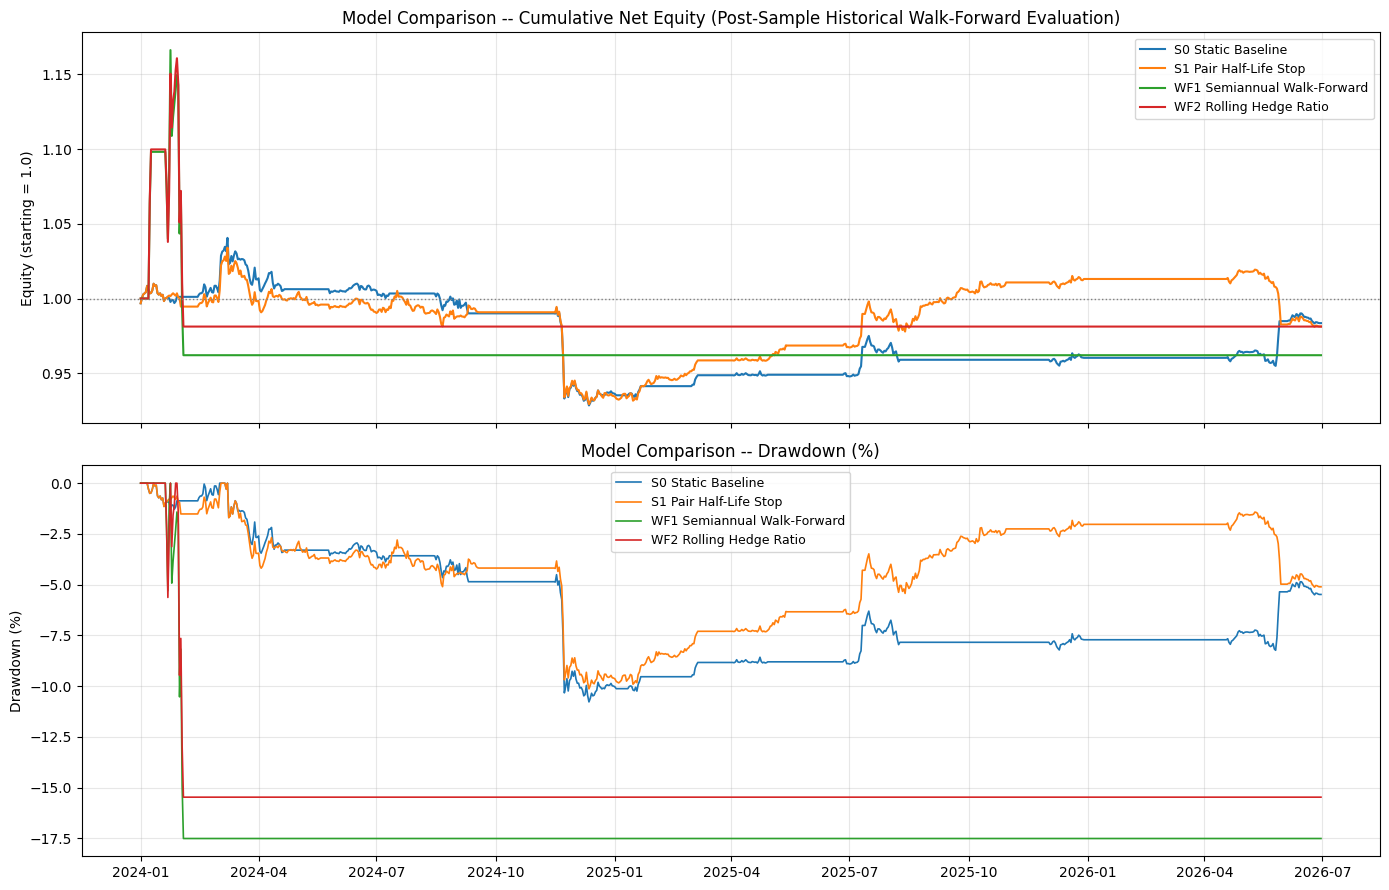

In [82]:
# 1-3. Equity curves and drawdown curves for every model
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

s0_daily, _ = aggregate_daily_returns(S0_OOS_PORTFOLIO_STD['frame']['net_ret'])
s1_daily, _ = aggregate_daily_returns(S1_OOS_PORTFOLIO['frame']['net_ret'])
wf1_daily, _ = aggregate_daily_returns(WF1_FULL_FRAME['net_ret'])
wf2_daily, _ = aggregate_daily_returns(WF2_FULL_FRAME['net_ret'])

for label, daily in [('S0 Static Baseline', s0_daily), ('S1 Pair Half-Life Stop', s1_daily),
                       ('WF1 Semiannual Walk-Forward', wf1_daily), ('WF2 Rolling Hedge Ratio', wf2_daily)]:
    eq = (1 + daily).cumprod()
    axes[0].plot(eq.index, eq.values, label=label, linewidth=1.5)
axes[0].axhline(1.0, color='gray', linestyle=':', linewidth=1)
axes[0].set_title('Model Comparison -- Cumulative Net Equity (Post-Sample Historical Walk-Forward Evaluation)')
axes[0].set_ylabel('Equity (starting = 1.0)')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

for label, daily in [('S0 Static Baseline', s0_daily), ('S1 Pair Half-Life Stop', s1_daily),
                       ('WF1 Semiannual Walk-Forward', wf1_daily), ('WF2 Rolling Hedge Ratio', wf2_daily)]:
    dd = drawdown(daily)
    axes[1].plot(dd.index, dd.values * 100, label=label, linewidth=1.2)
axes[1].set_title('Model Comparison -- Drawdown (%)')
axes[1].set_ylabel('Drawdown (%)')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Distribution of Pair-Specific Time Stops, Exit Reasons, and Daily Sharpe

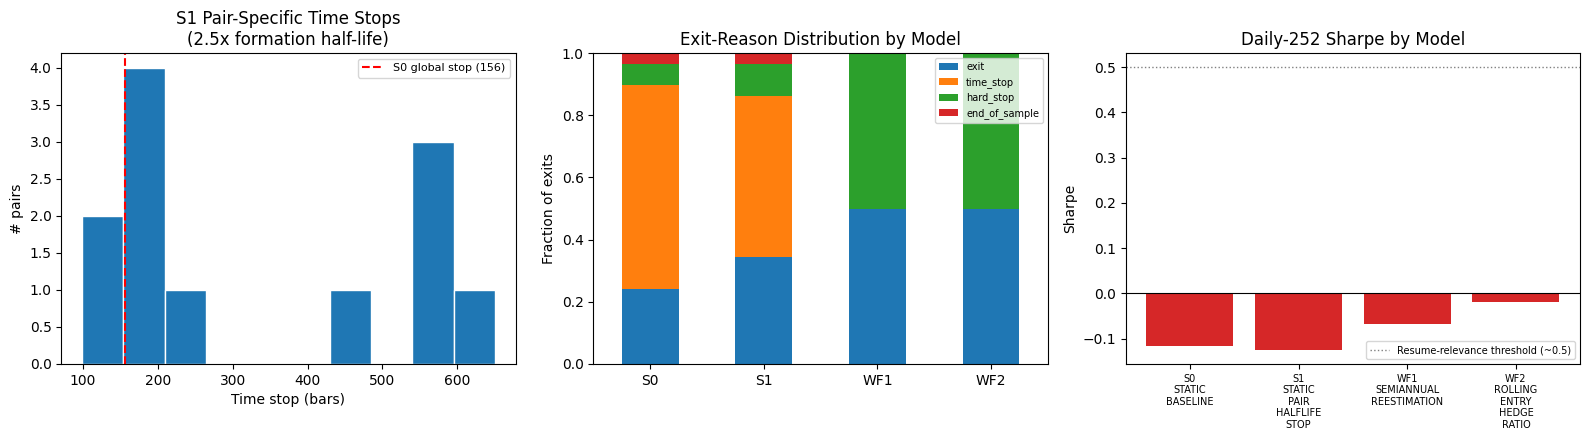


Exit-reason distribution (fractions):


,exit,time_stop,hard_stop,end_of_sample
S0,0.241,0.655,0.069,0.034
S1,0.345,0.517,0.103,0.034
WF1,0.500,0.000,0.500,0.000
WF2,0.500,0.000,0.500,0.000


In [83]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 9. Distribution of pair-specific time stops (S1 primary spec)
s1_ts_values = list(s1_time_stops.values())
axes[0].hist(s1_ts_values, bins=10, edgecolor='white')
axes[0].axvline(CONFIG['TIME_STOP_BARS'], color='red', linestyle='--', label=f"S0 global stop ({CONFIG['TIME_STOP_BARS']})")
axes[0].set_title('S1 Pair-Specific Time Stops\n(2.5x formation half-life)')
axes[0].set_xlabel('Time stop (bars)')
axes[0].set_ylabel('# pairs')
axes[0].legend(fontsize=8)

# 10. Exit-reason distribution across S0, S1, WF1, WF2
exit_data = {
    'S0': exit_reason_fractions(oos_trades),
    'S1': exit_reason_fractions(S1_OOS_TRADES),
    'WF1': exit_reason_fractions(WF1_ALL_TRADES),
    'WF2': exit_reason_fractions(WF2_ALL_TRADES),
}
exit_df = pd.DataFrame(exit_data).fillna(0.0).T
reason_order = [c for c in ['exit', 'time_stop', 'hard_stop'] if c in exit_df.columns]
other_cols = [c for c in exit_df.columns if c not in reason_order]
exit_df = exit_df[reason_order + other_cols]
exit_df.plot(kind='bar', stacked=True, ax=axes[1], legend=True)
axes[1].set_title('Exit-Reason Distribution by Model')
axes[1].set_ylabel('Fraction of exits')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(fontsize=7, loc='upper right')

# 13. Daily Sharpe comparison
sharpe_compare = MASTER_COMPARISON_DF['daily_sharpe_252'].copy()
sharpe_compare['WF2_ROLLING_ENTRY_HEDGE_RATIO'] = wf2_row['daily_sharpe_252']
colors = ['tab:red' if v < 0 else 'tab:green' for v in sharpe_compare.values]
axes[2].bar(range(len(sharpe_compare)), sharpe_compare.values, color=colors)
axes[2].set_xticks(range(len(sharpe_compare)))
axes[2].set_xticklabels([s.replace('_', '\n') for s in sharpe_compare.index], fontsize=7)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].axhline(0.5, color='gray', linestyle=':', linewidth=1, label='Resume-relevance threshold (~0.5)')
axes[2].set_title('Daily-252 Sharpe by Model')
axes[2].set_ylabel('Sharpe')
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

print('\nExit-reason distribution (fractions):')
exit_df.round(3)

### Cointegration Adjusted-P-Value Evolution and Pair-Selection Count

Both are already computed in Section 19/20 (the point-in-time stability screen and WF1
selection); this consolidates them into the dedicated Phase-13 deliverable views.

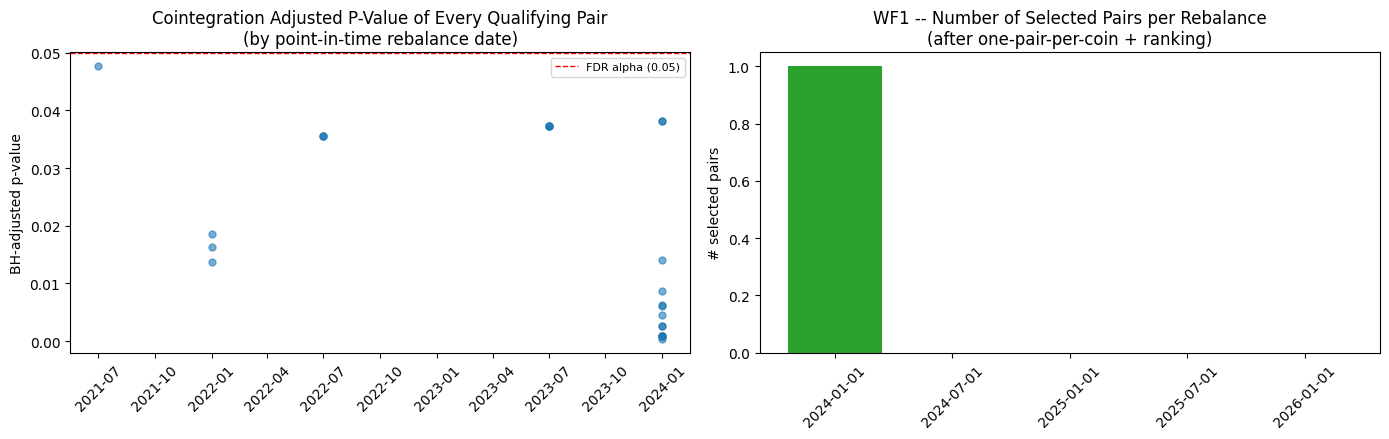

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 8. Cointegration adjusted-p-value evolution: all qualifying pairs, by rebalance date
for rebal_date in REBALANCE_DATES:
    sub = pair_stability_df[pair_stability_df['rebalance_date'] == rebal_date]
    if len(sub):
        axes[0].scatter([rebal_date] * len(sub), sub['pvalue_adj'], alpha=0.6, color='tab:blue', s=25)
axes[0].axhline(CONFIG['EG_ALPHA'], color='red', linestyle='--', linewidth=1, label=f"FDR alpha ({CONFIG['EG_ALPHA']})")
axes[0].set_title('Cointegration Adjusted P-Value of Every Qualifying Pair\n(by point-in-time rebalance date)')
axes[0].set_ylabel('BH-adjusted p-value')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(fontsize=8)

# 4. Number of selected pairs by rebalance date -- WF1's actual trading decision (distinct
# from Section 19's raw qualifying-pair count, since WF1 additionally enforces one-pair-per-
# coin and a max_pairs cap).
wf1_n_selected = pd.Series({d: len(sel) for d, sel in WF1_SELECTIONS.items()})
axes[1].bar(wf1_n_selected.index.astype(str), wf1_n_selected.values, color='tab:green')
axes[1].set_title('WF1 -- Number of Selected Pairs per Rebalance\n(after one-pair-per-coin + ranking)')
axes[1].set_ylabel('# selected pairs')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 28. Final Research Interpretation

**Summary of what was tested.** Starting from the unmodified S0 static baseline (OOS daily
Sharpe -0.12), three economically motivated extensions were implemented and evaluated on the
same standardized daily-252 Sharpe / BTC-benchmark framework: S1 (pair-specific half-life
time stops), WF1 (walk-forward pair re-selection every 6 months, corrected per expert review
to use true 12-month formation coverage, active-at-rebalance eligibility, and S0-matching
pair-quality filters), and WF2 (WF1 + rolling entry-time hedge sizing). All leakage/
reconciliation/eligibility assertions pass (Sections 22-23); none of the multiplier or
rebalance-frequency robustness checks was used to cherry-pick a better-looking specification.

### S1: pair-specific time stops (feedback #14)

S1 does exactly what it is designed to do at the mechanism level: the fraction of exits
caused by the universal time stop drops from 65.5% (S0) to 51.7% (S1), and mean-reversion
exits rise correspondingly (24.1% -> 34.5%). **This mechanism change does not translate into
improved risk-adjusted performance** -- the primary 2.5x specification's daily Sharpe is
slightly worse than S0 (-0.1249 vs -0.1155). The 2.0x robustness variant does show a
materially better Sharpe (+0.34) in this sample, but per the pre-registered robustness
protocol this is **not** adopted as the new primary specification, precisely because
Sharpe ranges from +0.34 (2.0x) to -0.20 (3.0x) across three adjacent, equally-defensible
multiplier choices. **This instability is itself the finding**: time-stop selection is not a
robust enough lever to explain, or fix, the original static model's underperformance.

### WF1 / WF2: walk-forward re-estimation (feedback #15)

The corrected point-in-time eligibility rules changed the walk-forward pair-selection result
substantially from an earlier, buggy version of this analysis (which required only ~17 days
of formation coverage and excluded XMR/several other coins without a stated reason): the
number of qualifying pairs at the 2024-01-01 rebalance went from 0 to 15 once eligibility was
corrected to a genuine ~90%-coverage 12-month window. **The corrected central finding is not
that WF1 is a working strategy** -- it is that under a strict, methodologically consistent
walk-forward selection process, **very few relationships survive and very few trades are
generated**: WF1 trades exactly one pair (OM/LDO) for 2 trades total across the entire
2024-2026 evaluation window, spending only 1.5% of the period with any position on. Its
daily Sharpe (-0.068) is less negative than S0's, but this is not read as evidence of a
successful dynamic strategy -- 2 trades is far too small a sample to distinguish skill from
noise, and the **active-day BTC beta diagnostic makes this concrete**: while WF1's
unconditional beta looks reassuringly close to zero (0.014, mechanically pulled there by 98.5%
of days being flat), its beta conditional on actually holding a position is **0.78** --
substantially directional, not market-neutral, on the few days it was actually in the
market.

WF2 (rolling entry-time hedge sizing on the same two trades) produces a similar-magnitude
Sharpe (-0.019 vs -0.068) and a somewhat lower unconditional-to-active-day beta gap. With
only 2 trades in both models, this difference is not interpreted as evidence that
entry-time hedge-ratio adaptation helps or hurts -- there is simply not enough data to say.

The pre-specified 3-month rebalance-frequency robustness check adds one more trading pair
(ARB/TIA, selected at 2024-10-01) but that pair never crosses its entry threshold in its
~3-month block, so the 3-month and 6-month results are numerically identical in this sample.
Consistent with feedback guidance, this is reported as **more frequent relationship
re-estimation increases the opportunity set in principle, but the current historical sample
does not contain enough realized trades to say whether that translates into stronger
performance** -- it remains a robustness observation, not a basis for changing the primary
6-month specification.

### Which of the two valid outcomes does this support?

This is closer to outcome (2): **the apparent in-sample stat-arb relationship does not
survive sufficiently robust walk-forward testing** -- not primarily because of a time-stop or
hedge-ratio design choice (S1 and WF2's isolated changes to those mechanisms move Sharpe by
only a few hundredths to a few tenths, and not robustly in one direction), but because
walk-forward pair *selection*, applied with the same statistical rigor as the original
screen, finds very little to trade in the 2024-2026 evaluation period once formation
coverage and universe eligibility are handled correctly. S0's own negative OOS Sharpe is
therefore primarily a **relationship-existence / relationship-scarcity problem in this
specific 2024-2026 sample**, not a parameter-tuning problem.

### What this does and does not show

It does not show that crypto stat-arb is unconditionally unprofitable -- only that, on this
screen and this 12-month-formation/6-month-rebalance walk-forward specification, 2024-2026
produced very few statistically qualifying relationships to trade, and the ones that did
qualify were not clearly market-neutral on the days they were actually held. The optional
Phase 11 universe expansion (a point-in-time-reconstructed top-N Binance universe, as
distinct from the already-expanded 45-coin WF_PX universe used throughout Sections 19+) is
the natural next step to test whether trade scarcity is a further universe-construction
artifact or a genuine feature of this asset class's 2023-2026 relationship structure. Until
that is tested, none of S0, S1, WF1, or WF2 clears the ~0.5 daily-252 Sharpe threshold that
would make this strategy resume-relevant, and this notebook does not force that conclusion
to look otherwise -- a negative or inconclusive result, honestly reported with its
sample-size caveats intact, is the correct output of this research program as currently
specified.